[Read in English](https://pilkwangkim.github.io/posts/A-Star-From-Scratch/)

목적지로 곧장 가는 경로가 가장 저렴한 것은 아니다. 잔디 한 칸에 들어가는 비용은 1, 진흙 한 칸에 들어가는 비용은 5라고 하자. 진흙 구간을 가로지르면 적게 움직이고도 도착할 수 있지만, 잔디로 돌아가는 편이 전체 비용은 더 작을 수 있다. 최소화하려는 것은 이동 횟수나 목적지와의 거리가 아니라 **이동 비용의 합**이다.

A\*는 각 후보까지 오는 데 든 비용에, 그곳에서 목적지까지 남은 비용의 추정값을 더해 다음 후보를 고른다. 목적지에 가까워 보이는 쪽만 따라가지도 않고, 이미 든 비용만으로 후보를 고르지도 않는다.

A\*는 “A star”라고 읽으며, 다음 두 값을 더해 탐색 순서를 정한다.

$$
f(n)=g(n)+h(n).
$$

$g(n)$은 발견한 경로를 따라 state $n$까지 오는 데 든 비용이고, $h(n)$은 남은 비용의 추정값이다. 이 추정값을 **heuristic**이라고 한다. 둘을 더한 $f(n)$이 priority이며, 이 값이 가장 작은 후보부터 처리한다. 유용한 heuristic이 있으면 불필요하게 살펴보는 후보를 줄일 수 있다. 남은 비용을 과대추정하지 않는 lower bound를 사용하고 비용 갱신과 종료 조건을 지키면, 최적 경로도 보장할 수 있다. 경로의 비용은 끝까지 원래 이동 비용의 합으로 계산한다. Heuristic은 탐색 순서를 바꿀 뿐, 최적화할 목표를 바꾸지는 않는다.

## 1. 탐색의 대상부터 정하자

### 1.1 State, edge, path

**State**는 탐색하려는 상황을 코드로 표현한 것이다. 다음에 무엇을 할 수 있고 비용은 얼마나 드는지 판단하는 데 필요한 정보를 모두 담아야 한다. 단순한 지도에서는 좌표 `(x, y)`면 충분하다. 열쇠로 문을 여는 미로라면 `(x, y, keys)`처럼 열쇠 보유 여부도 필요하다. 같은 칸이라도 열쇠가 있을 때와 없을 때 갈 수 있는 곳이 다르므로, 서로 다른 state로 구분한다.

State와 탐색 알고리즘이 관리하는 자료구조는 구분하자. 지도 좌표는 state이고, stack의 항목은 나중에 처리할 state를 보관한 기록이다. 보통 stack이나 queue의 내용, 화면에 표시하는 탐색 이력까지 state에 넣지는 않는다. 반면 열쇠는 열 수 있는 문을 결정하므로 state에 포함한다. 도착 시간에 따라 이용 가능한 도로가 달라지는 문제라면 시간도 필요하다. 좌표만 저장해서는 이런 차이를 구분할 수 없다.

State들과 그 사이의 이동을 **graph**로 표현하자.

$$
\begin{gathered}
\mathcal G=(V,E),\\
s\in V,\qquad t\in V.
\end{gathered}
\tag{1}
$$

$V$는 state의 집합이다. Graph에서 각 state를 나타내는 점을 vertex 또는 node라고 한다. $E$에는 가능한 이동을 방향과 함께 기록한다. $s$는 시작점, $t$는 목적지이며, edge $(u,v)$의 비용은 $c(u,v)$다. 양방향 통로는 방향이 반대인 두 edge로 표현하면 된다. 오르막과 내리막처럼 방향에 따라 비용이 달라도 된다.

탐색 문제를 풀기 전에 네 가지를 정해야 한다. 시작 state, 성공 조건, 각 state에서 가능한 action, 그리고 action별 비용이다. 아래 코드에서는 특정 goal에 도착했는지 비교한다. 물통에 4리터를 만드는 퍼즐처럼 성공하는 state가 여러 개일 수도 있다. 이때는 특정 배치와 비교하는 대신 성공 조건을 검사하면 된다. State와 edge를 표현하는 방식은 그대로 쓸 수 있다. Heuristic을 사용한다면 여러 goal 중 **가장 저렴하게 도달할 수 있는 goal**까지의 남은 비용을 추정해야 한다.

경로 $P=(v_0,v_1,\ldots,v_k)$는 $v_0=s$에서 시작해 매번 edge를 따라 이동하고 $v_k=t$에서 끝난다. 이 경로의 비용은

$$
\begin{aligned}
C(P)&=\sum_{i=0}^{k-1}c(v_i,v_{i+1}),\\
C^{\ast}&=\min_{P:s\leadsto t}C(P).
\end{aligned}
\tag{2}
$$

이다. Edge를 몇 번 지나는지는 $k$로, 그 과정에서 드는 비용의 합은 $C(P)$로 구분한다. 모든 edge의 비용이 1일 때만 두 값이 같다. 경로가 없으면 $C^{\ast}=\infty$로 두고 경로를 반환하지 않는다. $s=t$라면 이동할 필요가 없으므로 비용은 0이다.

별도로 명시한 경우를 제외하면 graph는 유한하고, 모든 edge cost는 유한한 0 이상의 값이라고 가정한다. 탐색하는 동안 graph와 비용도 바뀌지 않는다. 비용이 0인 edge는 허용하지만 음수인 edge는 다루지 않는다. 음수 비용에는 다른 알고리즘이 필요하다. 특히 시작점에서 도달 가능한 negative cycle을 거쳐 목적지로 갈 수 있다면, cycle을 한 번 더 돌 때마다 비용이 줄어든다. 이런 경우에는 비용이 가장 작은 경로 자체가 존재하지 않을 수 있다.


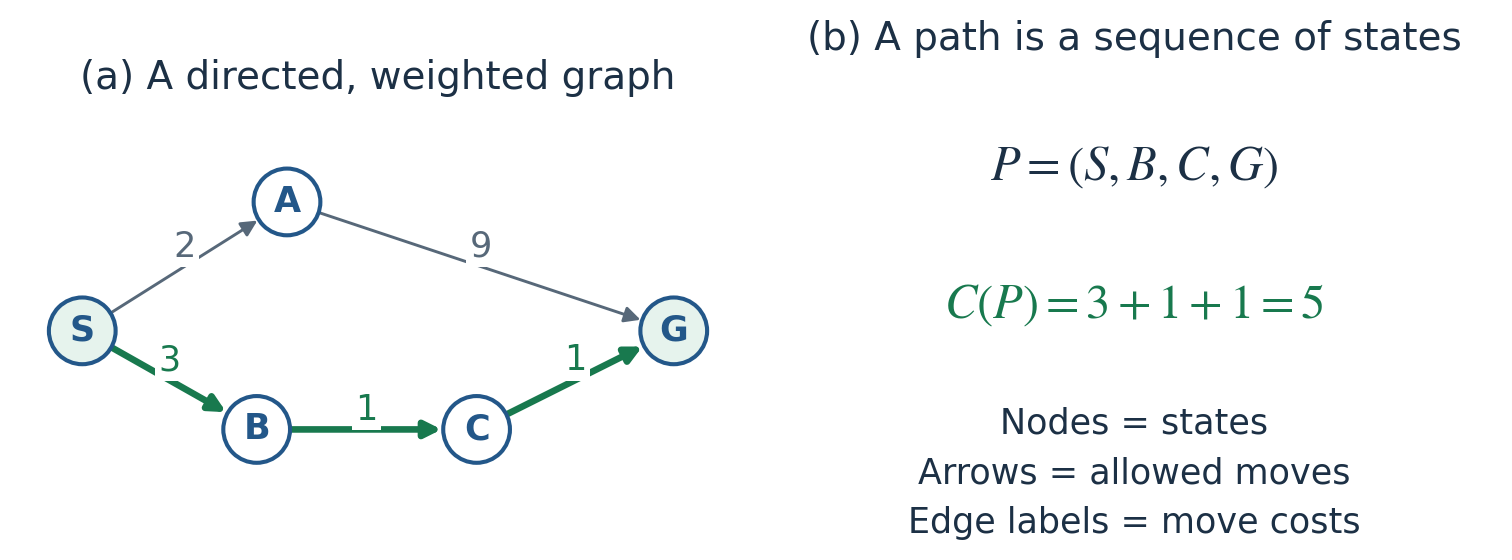

*Figure 1. Graph는 어디로 이동할 수 있는지와 각 이동의 비용을 나타낸다. 탐색 알고리즘에 따라 후보를 살펴보는 순서는 달라져도, 구하려는 답은 이동 비용의 합이 가장 작은 경로다.*

### 1.2 Adjacency list로 표현하기

작은 graph는 dictionary로 간단히 표현할 수 있다. State를 key로 쓰고, 그곳에서 갈 수 있는 `(neighbor, cost)` 쌍을 list에 담는다.


In [1]:
graph = {
    "S": [("A", 2), ("B", 3)],
    "A": [("G", 9)],
    "B": [("C", 1)],
    "C": [("G", 1)],
    "G": [],
}

def path_cost(graph, path):
    # This example has at most one directed edge between each pair.
    return sum(dict(graph[u])[v] for u, v in zip(path, path[1:]))

assert path_cost(graph, ["S", "A", "G"]) == 11
assert path_cost(graph, ["S", "B", "C", "G"]) == 5


`zip(path, path[1:])`는 경로에서 연속한 두 state를 S–B, B–C, C–G처럼 묶는다. 각 쌍에 해당하는 edge cost를 찾아 더하면 전체 경로의 비용이 된다. 마지막 state에 도착한 뒤에는 이동이 없으므로 더할 비용도 없다.

Adjacency list에는 각 vertex에서 나가는 edge만 저장한다. 가능한 모든 vertex 쌍을 행렬로 만드는 방식보다 연결이 드문 graph에 적합하다. Grid에서는 좌표를 바탕으로 이웃을 그때그때 구할 수도 있다. 이 경우에는 지도 전체를 dictionary로 미리 만들 필요도 없다.

`graph["S"]`의 `("A", 2)`를 읽으면 “S에서 A로 한 번 이동할 수 있고, 비용은 2다”가 된다. 이 2는 A 자체에 붙인 점수가 아니라 **S–A 이동의 비용**이다. G에는 빈 list를 연결했다. G도 graph의 state지만 G에서 나가는 edge는 없다. 뒤에서 사용하는 `graph.get(u, [])`는 key가 없을 때도 빈 list를 돌려주므로 같은 방식으로 처리한다.

가능한 action을 한 번 했을 때 도달하는 다음 state를 **successor**라고 한다. Successor list를 미리 저장하면 explicit graph이고, 필요할 때 계산하면 implicit graph다. Grid에서는 이웃 좌표를 구하고 벽이나 지도 밖인 칸을 제외하면 된다. 퍼즐에서는 현재 배치에 가능한 이동을 적용한다. 어느 쪽이든 탐색 알고리즘에는 `(successor, cost)` 쌍을 넘겨주면 된다. 모든 state를 미리 나열하거나 graph를 그림으로 그려 놓을 필요는 없다.

### 1.3 Frontier: 아직 살펴보지 않은 후보들

대부분의 탐색 알고리즘은 다음 과정을 반복한다.

1. **Frontier**에 후보들을 보관한다.
2. 정해진 규칙에 따라 후보 하나를 꺼낸다.
3. 그 후보가 목적지이고 알고리즘의 종료 조건을 만족하면 경로를 복원한다.
4. 그렇지 않으면 그 후보를 **expand**한다. 즉, 나가는 edge들을 확인하고 후보를 추가하거나 갱신한다.

State를 처음 발견해 기록하면 **discovered**, 그 state를 꺼내 나가는 edge까지 살펴봤으면 **expanded**라고 한다. 발견과 처리는 동시에 일어나지 않을 수 있다. 발견한 뒤 한참 기다렸다가 expand할 수도 있고, 알고리즘에 따라 같은 state를 여러 번 expand할 수도 있다. “Visited”만으로는 어느 시점인지 알기 어렵다. 알고리즘이 올바른지 따질 때는 발견한 것인지, expand한 것인지 구분해야 한다.

Frontier에는 서로 다른 갈래의 후보들이 함께 들어 있다. 따라서 frontier에서 꺼낸 순서를 캐릭터의 이동 경로처럼 읽으면 안 된다. A 다음에 B를 expand했더라도 A–B가 연결되어 있지 않을 수 있다. 컴퓨터가 A의 처리를 마치고 B라는 다른 후보를 살펴본 것이다. 마지막에 반환하는 경로는 이 처리 순서와 별개로, 실제 graph의 edge들을 따라야 한다.

경로를 돌려주려면 각 state에 어디서 왔는지도 기록해야 한다. 이를 `parent` dictionary에 저장한다. `parent["C"] == "B"`라면 현재 기록한 경로에서는 B 다음이 C다. 목적지에서 parent를 하나씩 따라가면 시작점까지 거슬러 올라갈 수 있다.


In [2]:
def reconstruct(parent, goal):
    path = []
    node = goal
    while node is not None:
        path.append(node)
        node = parent[node]
    return path[::-1]


S → B → C → G를 기록했다면 parent에는 `B: S`, `C: B`, `G: C`가 들어 있다. 시작점에는 이전 state가 없으므로 `S: None`을 넣는다. 복원 함수는 G, C, B, S 순서로 따라가고, `None`에서 멈춘 뒤 list를 뒤집는다. Frontier가 **앞으로 처리할 후보**를 보관한다면, `parent`는 **경로에서 바로 앞에 오는 state**를 기록한다. 뒤의 코드에서는 `parent`에 key가 있는지를 보고 해당 state를 이미 발견했는지도 확인한다. 한 dictionary를 두 용도로 사용하는 것이다.

`path[::-1]`는 list를 역순으로 만드는 Python slice다. DFS와 BFS는 위의 `reconstruct` 함수를 사용하고, 뒤의 예제도 앞에서 정의한 탐색 함수를 재사용한다. 다운로드한 notebook을 위에서 아래로 실행하면 필요한 함수들이 차례로 정의된다.

원래 graph와 **search tree**는 node가 나타내는 대상부터 다르다. Graph의 node는 state지만, search tree의 node는 그곳에 도착하기까지 선택한 경로도 구분한다. S → A → X와 S → B → X는 같은 X에 도착해도 서로 다른 경로이므로 search tree에서는 별개의 node다. 일반적인 graph DFS와 BFS는 X를 한 번만 기록해 이런 중복을 제거한다. 반대로 모든 경로를 나열하려면 두 경로를 따로 보관해야 한다. 같은 graph를 탐색하더라도 계산량이 크게 달라질 수 있다.

## 2. DFS: 한 갈래를 먼저 따라간다

**Depth-first search**, 줄여서 DFS는 **stack**으로 탐색 순서를 정한다. Stack에서는 마지막에 넣은 후보를 가장 먼저 꺼낸다. 접시를 쌓았다가 맨 위부터 꺼내듯이 처리하므로 last in, first out, 즉 LIFO라고 한다.

아래 코드는 반복문으로 구현한 graph DFS다. State를 stack에 넣을 때 발견 여부도 기록한다. 이웃 list는 역순으로 넣는다. 그래야 원래 list의 첫 번째 이웃이 stack에서 먼저 나온다. 이웃 순서에 따라 반환하는 경로는 달라질 수 있지만, 목적지에 도달할 수 있는지에 대한 답은 같다.


In [3]:
def dfs(graph, start, goal):
    stack = [start]
    parent = {start: None}  # Also records states already discovered.

    while stack:
        u = stack.pop()    # LIFO: follow the newest unfinished branch.
        if u == goal:
            return reconstruct(parent, goal)
        for v, _cost in reversed(graph.get(u, [])):
            if v not in parent:
                parent[v] = u
                stack.append(v)
    return None

assert dfs(graph, "S", "G") == ["S", "A", "G"]


Stack의 **오른쪽 끝**에서 항목을 꺼낸다고 생각하고 코드를 따라가 보자. 처음에는 `[S]`만 있다. S를 꺼낸 뒤 B, A 순서로 넣으면 `[B, A]`가 된다. 다음으로 A를 꺼내 G를 발견하면 `[B, G]`가 된다. 이제 G를 꺼내므로 경로를 반환하고 끝난다. B는 expand할 필요가 없다. 처리한 순서는 S, A, G이고 반환 경로도 S → A → G다. 이 예에서는 우연히 일치하지만, 다른 graph에서는 처리 순서와 반환 경로가 다를 수 있다.

`v not in parent`로 이미 발견한 state를 걸러 내고, 새 state는 stack에 넣을 때 parent도 기록한다. 따라서 cycle이 있어도 같은 state가 계속 추가되지 않는다. 이 구현의 stack에는 B처럼 *나중에 살펴볼 다른 갈래*도 들어 있다. Stack 전체가 현재 경로인 것은 아니다. 반면 recursive DFS의 call stack에는 현재 호출이 끝나기를 기다리는 상위 호출들이 남는다. 두 구현 모두 목적지에 도달할 수 있는지 알아낼 수 있지만, stack에 담기는 항목은 다르다. 갈래 사이에 edge가 있는 graph라면 parent tree도 서로 다를 수 있다.

유한한 graph에서 목적지로 가는 경로가 존재하면 DFS는 그중 *하나*를 찾는다. 가장 저렴한 경로를 고르는 것은 아니다. 코드에서 edge cost를 한 번도 비교하지 않으므로, 처음 찾은 경로가 최적 경로보다 얼마나 비쌀지는 보장할 수 없다. 위 graph에서도 S의 이웃 순서만 바꾸면 반환 경로의 비용이 11에서 5로 달라진다.

Adjacency list를 사용하고 dictionary 연산에 평균적으로 상수 시간이 걸린다고 가정하면, 이 graph DFS의 시간 복잡도는 $O(\lvert V\rvert+\lvert E\rvert)$, 추가 메모리는 $O(\lvert V\rvert)$다. 각 state를 stack에 최대 한 번 넣고, 도달한 state에서 나가는 edge도 각각 최대 한 번 확인하기 때문이다. Recursive DFS에서는 직접 만든 stack 대신 call stack을 쓴다. 한 갈래가 길게 이어지면 호출도 그만큼 깊어져 Python의 재귀 한도를 넘을 수 있다.

집합 양옆의 세로선은 원소 수를 센다는 표시다. V에서는 state 수, E에서는 edge 수를 센다. **Big-O 표기법**으로는 입력 크기에 따라 연산량이나 메모리가 얼마나 빠르게 늘어나는지 비교한다. 상수 배나 증가 속도가 더 느린 항은 생략한다. 위 시간 복잡도는 graph가 커질수록 필요한 작업량이 state 수와 edge 수의 합에 비례하는 범위에서 증가한다는 의미다. 실행 시간이 몇 초인지를 알려 주는 식은 아니다. 엄밀히는 입력이 충분히 클 때 작업량이 그 합의 일정한 상수 배를 넘지 않는다는 상한이다. 추가 메모리를 셀 때는 입력 graph를 저장한 공간은 제외한다.

### 2.1 DFS로 미로 만들기: stack과 backtracking


DFS는 미로를 찾는 데만 쓰는 것이 아니라 미로를 만드는 데도 쓸 수 있다. 처음에는 모든 방 사이를 벽으로 막아 둔다. Stack 맨 위의 방에서 아직 방문하지 않은 이웃 방 하나를 고른다. 두 방 사이의 벽을 허물고 새 방을 stack에 넣는다. 더 갈 이웃이 없으면 현재 방을 꺼내고 이전 방으로 돌아간다. 같은 seed로 시작하면 이웃을 고르는 순서도 같아져 같은 미로가 만들어진다.


**DFS 미로 만들기.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-dfs-maze)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


한 단계씩 진행하기 전에 다음에는 통로를 더 뚫을지, 이전 방으로 돌아갈지 예상해 보자. Seed를 바꿔 보면 길게 이어지는 통로와 일찍 막히는 갈래가 어떻게 달라지는지도 볼 수 있다. Stack에는 현재 탐색 중인 갈래가 남아 있다. 방을 꺼냈다면 그 방의 이웃은 모두 확인했다는 의미다. 실패해서 처음부터 다시 만드는 것이 아니라, 남은 이웃이 있는 방으로 돌아가 작업을 이어 가는 것이다.

방이 $N$개일 때, 새 통로는 언제나 아직 방문하지 않은 방 하나를 연결한다. 따라서 완성된 미로의 통로 수는 $N-1$개다. 모든 방이 연결되고 cycle은 없으므로, 통로 graph는 **spanning tree**가 된다. 어떤 두 방을 골라도 그 사이의 simple route는 하나뿐이다. 이 미로에서 DFS와 BFS로 길을 찾으면 같은 경로가 나올 수밖에 없다. 그 길을 찾기까지 살펴본 방의 수는 달라질 수 있다. 통로를 추가로 뚫어 loop를 만들어야 선택할 경로가 여러 개 생긴다.

여기서 미로 생성과 경로 탐색을 구분하자. 미로를 만들 때는 알고리즘이 벽을 허물어 edge를 추가한다. 완성된 미로에서 길을 찾을 때는 이미 있는 edge만 따라간다.

이 미로 생성기에서는 현재 방을 stack에 남긴 채 새 방을 하나씩 추가한다. 그래서 화면의 stack은 만들고 있는 미로의 현재 경로와 일치하고, pop하면 바로 이전 방으로 돌아간다. 앞의 `dfs` 함수는 후보를 먼저 꺼낸 뒤 아직 발견하지 않은 이웃을 한꺼번에 넣었다. 두 구현에서 stack의 내용이 다른 이유다. 마지막에 넣은 항목부터 꺼내는 LIFO 규칙은 같다.

### 2.2 N-Queens: 충돌하는 배치를 미리 제외한다


Chessboard의 각 column에 queen을 하나씩 놓아 보자. 어느 두 queen도 같은 row나 diagonal에 있으면 안 된다. 이 문제의 state는 **지금까지 queen들을 놓은 배치 전체**다. 예를 들어 `[1, 3]`은 column 0의 queen이 row 1에, column 1의 queen이 row 3에 있다는 배치를 나타낸다. 다음 column에 queen 하나를 놓으면 새로운 state, 즉 successor가 된다.

Python 코드의 row와 column index는 0부터 세고, lab의 안내와 state 표시에서는 row와 column을 1부터 센다.


**N-Queens backtracking.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-dfs-queens)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


Solver를 실행하기 전에 직접 queen들을 놓아 보자. 다음 column에 놓을 곳이 없으면 마지막 queen을 빼고 다른 row를 고른다. 이후 DFS를 한 단계씩 실행하면 같은 선택과 되돌리기가 stack에서 어떻게 처리되는지 볼 수 있다. Queen끼리 충돌하는 배치는 즉시 제외하는데, 이를 **pruning**이라고 한다. 남은 queen들을 어디에 놓더라도 이미 생긴 충돌을 없앨 수는 없다. 그런 배치에서 출발하는 경우를 끝까지 시도할 필요가 없는 이유다.

서로 다른 column $i$와 $j$에 놓인 queen의 row index를 각각 $q_i$와 $q_j$라고 하자. 모든 queen 쌍이 다음 조건을 만족해야 한다.

$$
q_i\ne q_j,\qquad
\lvert q_i-q_j\rvert\ne\lvert i-j\rvert.
$$

첫 번째 조건은 두 queen이 같은 row에 놓이지 않도록 한다. 두 번째 조건은 row 차이와 column 차이가 같아지는 diagonal 배치를 제외한다. Column에는 하나씩만 놓으므로 같은 column인지 따로 검사할 필요는 없다. 완성된 해는 모두 같은 수의 queen을 놓아 얻으므로 depth도 같다. 여기서는 더 저렴한 경로를 찾는 것이 아니라, 조건을 만족하는 배치를 찾는다.


#### 참고: Python으로 pruning 조건 확인하기


In [4]:
def can_place_queen(partial, row):
    col = len(partial)
    return all(row != old_row and abs(row - old_row) != col - old_col
               for old_col, old_row in enumerate(partial))

def queen_solutions(n, partial=()):
    if len(partial) == n:
        yield partial
        return
    for row in range(n):
        if can_place_queen(partial, row):
            yield from queen_solutions(n, partial + (row,))

assert can_place_queen((1, 3), 0)
assert not can_place_queen((1, 3), 2)
assert len(list(queen_solutions(4))) == 2


`enumerate(partial)`은 앞서 놓은 queen의 column과 row를 차례로 꺼낸다. 새 queen이 이들 모두와 충돌하지 않아야 `all(...)`이 참이 된다. `(row,)`는 원소가 하나인 tuple이다. 기존 tuple에 이를 붙여 새 배치를 만들기 때문에 이전 배치는 바뀌지 않는다. 해를 찾으면 `yield`로 하나씩 반환하고, 재귀 호출이 찾은 해는 `yield from`으로 전달한다. 이처럼 값을 하나씩 만드는 함수를 generator라고 한다. `list(...)`로 해들을 모은 뒤 `len(...)`으로 개수를 센다.

`(1, 3)` 다음에 row 2를 고르면 왜 안 될까? Column 1, row 3에 놓은 queen과 같은 diagonal에 놓이기 때문이다. 이 문제에서 방문한 칸만 전역 set에 저장하면 충분하지 않다. 어떤 칸에 놓을 수 있는지는 지금까지 놓은 queen들의 배치에 따라 달라진다.



## 3. BFS: 이동 횟수가 적은 후보부터 살펴본다


**Breadth-first search**, 줄여서 BFS는 stack 대신 **queue**를 쓴다. 먼저 들어온 후보부터 꺼내는 first in, first out, 즉 FIFO 방식이다. 줄을 선 순서대로 차례가 오는 것과 같다.


In [5]:
from collections import deque

def bfs(graph, start, goal):
    queue = deque([start])
    parent = {start: None}

    while queue:
        u = queue.popleft()  # FIFO: finish the older distance layer first.
        if u == goal:
            return reconstruct(parent, goal)
        for v, _cost in graph.get(u, []):
            if v not in parent:
                # Mark on enqueue, not on dequeue: avoid duplicate entries.
                parent[v] = u
                queue.append(v)
    return None

assert bfs(graph, "S", "G") == ["S", "A", "G"]


Python list의 `pop(0)`으로도 맨 앞 원소를 꺼낼 수 있지만, 남은 원소들을 앞으로 옮기는 데 선형 시간이 걸린다. `deque.popleft()`는 나머지 원소를 옮기지 않고 맨 앞 원소를 꺼내므로 이 비용이 들지 않는다.

이번에는 queue의 **왼쪽 끝**에서 항목을 꺼낸다. 같은 graph에서 S를 expand하면 `[A, B]`, A를 expand하면 `[B, G]`, B를 expand하면 `[G, C]`가 된다. 다음 항목은 G이므로 여기서도 S → A → G를 반환한다. BFS는 A까지의 비용 2와 B까지의 비용 3을 비교하지 않는다. A를 먼저 처리한 것은 S의 이웃 list에서 A가 앞에 있었기 때문이다. G를 C보다 먼저 꺼내는 데도 비용은 고려하지 않는다. G는 두 번의 이동으로 이미 발견했고, C를 거쳐 G까지 가려면 세 번 이동해야 한다.

여러 갈래가 같은 state로 이어질 수 있으므로, **queue에 넣는 시점**에 발견 여부를 기록해야 한다. A와 B에서 모두 X로 갈 수 있다고 하자. A를 처리하며 X를 넣은 뒤, 아직 X의 차례가 오기 전에 B를 처리할 수 있다. 이때 `parent`에 X가 있는지 검사하면 X를 다시 넣지 않는다. 검사 시점을 꺼낼 때로 미루면, 한 번도 처리하지 않은 state가 queue에 여러 개 쌓일 수 있다. Unit cost에서는 처음 발견한 경로가 이미 최단 경로이므로 X를 한 번만 넣어도 충분하다.

### 3.1 BFS는 왜 edge 수가 가장 적은 경로를 찾을까?

시작점에서 어떤 state까지 가는 데 필요한 최소 edge 수를 그 state의 depth라고 하자. 처음 queue에는 depth가 0인 시작점만 있다. Depth-$d$ state를 expand하면 depth가 최대 $d+1$인 이웃들을 확인하게 된다. 새로 발견한 이웃은 모두 queue의 뒤에 넣는다. 따라서 앞서 들어온 얕은 후보들이 먼저 처리되고, 그보다 깊은 후보들이 뒤따른다. 이 순서를 유지하면 어떤 state도 더 짧은 경로를 제쳐 두고 긴 경로로 먼저 발견될 수 없다. 처음 기록한 경로가 그 state까지 edge 수가 가장 적은 경로다.

모든 edge의 비용이 같은 양수 $a$라면

$$
C(P)=a\,k(P),
\tag{3}
$$

이므로 edge 수가 가장 적은 경로는 비용도 가장 작다. 모든 edge cost가 0인 경우에도 도달 가능한 경로의 비용이 전부 0이므로 BFS의 답은 최소 비용이다. 하지만 edge마다 비용이 다르면 이야기가 달라진다. 위 증명으로 보장하는 것은 최소 이동 횟수이지, 이동 비용의 최소 합이 아니다.

DFS와 마찬가지로 유한한 explicit graph에서 graph BFS의 시간 복잡도는 $O(\lvert V\rvert+\lvert E\rvert)$, 추가 공간은 $O(\lvert V\rvert)$다. 다른 관점에서 계산할 수도 있다. Branching factor가 $b$이고 가장 가까운 goal의 depth가 $d$인 implicit search tree에서는 그 depth까지의 state 수가 대략

$$
\begin{gathered}
1+b+b^2+\cdots+b^d=O(b^d),\\
b>1.
\end{gathered}
\tag{4}
$$

이다. 앞의 복잡도와 다른 결과처럼 보이지만 세는 기준이 다르다. 앞에서는 전체 state 수를 입력 크기로 썼고, 여기서는 depth에 따라 state가 얼마나 늘어나는지 계산했다. Implicit state space에서는 depth가 커질수록 state 수 자체가 지수적으로 증가할 수 있다. BFS는 이렇게 늘어난 후보들을 frontier에 보관해야 하므로, 실행 시간보다 메모리 한계에 먼저 부딪히는 경우가 많다.

**Branching factor**는 여기서 가정한 full tree의 각 node가 갖는 successor 수다. 매번 선택지가 두 개씩 생긴다면 depth 0에는 후보가 1개, depth 1에는 2개, depth 2에는 4개가 있다. 실제 graph에서는 갈래가 합쳐질 수 있고 successor 수도 제각각이다. 따라서 이 식은 모든 지도의 node 수를 정확히 세는 공식보다는, depth에 따라 후보 수가 얼마나 빠르게 증가할 수 있는지 보여 주는 계산이다. 화면의 BFS frontier에는 먼저 발견한 layer의 남은 후보와 그다음 layer에서 새로 발견한 후보들이 순서대로 기다린다.


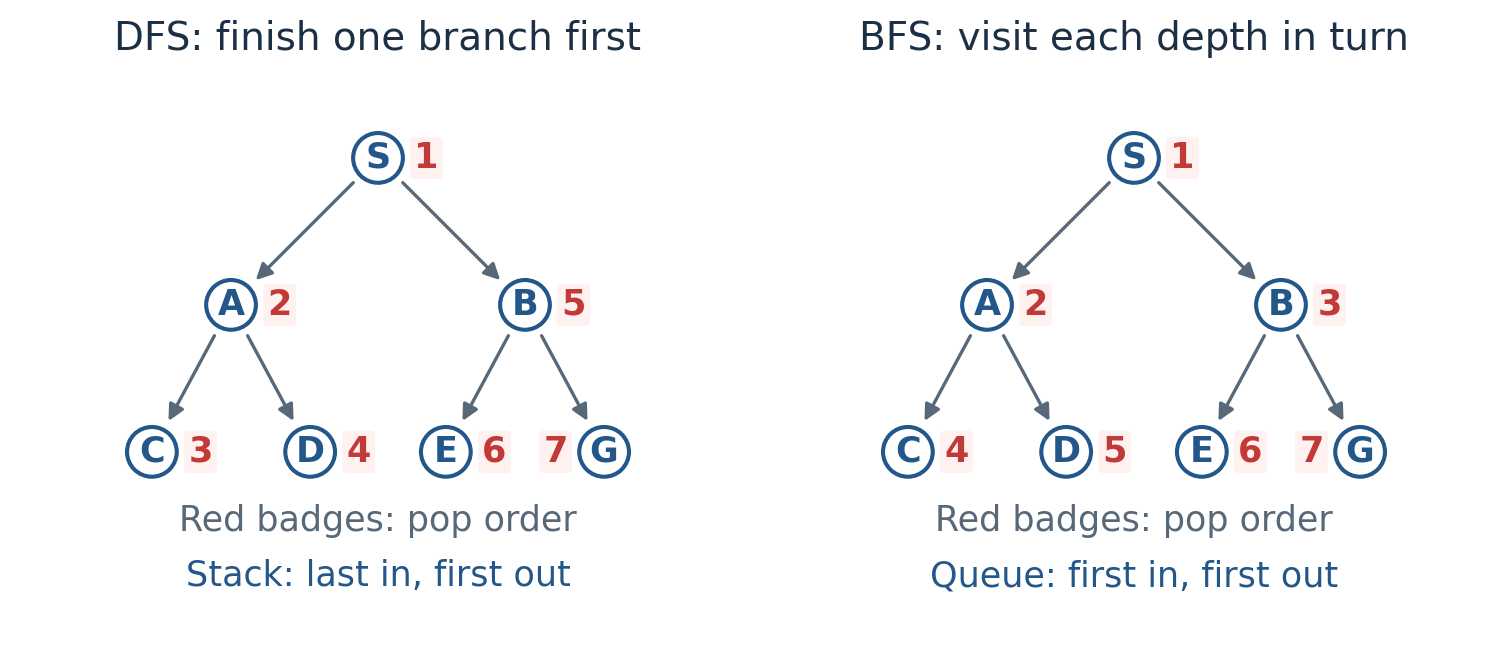

*Figure 2. 코드의 graph와는 별개로, 7개 state로 이루어진 tree에서 DFS와 BFS의 처리 순서를 비교했다. 빨간 숫자는 왼쪽 이웃을 먼저 처리할 때 후보를 꺼내는 순서다. 화살표는 graph의 edge이며, 숫자 순서대로 연속해서 이동하는 경로를 나타내지는 않는다. 이웃 순서를 바꾸면 동순위 후보의 처리 순서도 달라진다.*


**DFS/BFS 탐색 실습.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-astar-traversal)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


DFS를 고르고 **한 단계**를 몇 번 눌러 보자. 다음에 꺼낼 후보를 먼저 예상하면 stack의 동작을 확인하기 쉽다. **초기값으로**를 누른 뒤 BFS에서도 반복하고, 반환 경로와 expanded state 수를 비교해 보자. 더 짧은 경로를 찾은 쪽이 더 적은 state를 살펴봤을까? 경로의 길이와 탐색에 든 작업량은 별도로 비교해야 한다.


#### 참고: 간단한 퀴즈: BFS는 목적지를 발견하자마자 끝내도 될까?


일반적인 unweighted BFS에서는 가능하다. 처음 발견했을 때 이미 최소 depth의 경로를 얻었기 때문이다. 위 코드는 뒤의 알고리즘들과 같은 구조로 읽을 수 있도록 queue에서 꺼낼 때 goal을 검사한다. 반면 Dijkstra와 A\*는 goal을 처음 발견했다고 바로 끝내면 오답이 나올 수 있다. Frontier에 남아 있는 다른 후보를 통해 더 저렴하게 goal에 도착할 수도 있다.



### 3.2 Word ladder: 한 글자씩 바꾸는 최단 경로


한 번에 글자 하나만 바꿔서 `COLD`를 `WARM`으로 만들어 보자. 매번 바꾼 결과는 화면에 표시된 dictionary에 있는 단어여야 한다. 단어 하나를 state로 보고, 정확히 한 자리만 다른 두 단어를 edge로 잇는다. 한 번 바꾸는 비용은 1이다. 실제 영어 단어를 알고 있더라도 화면의 dictionary에 없으면 사용할 수 없다. 이 목록이 이 퍼즐에서 허용하는 state 전부다.


**Word ladder 퍼즐.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-bfs-words)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


가능한 다음 단어를 골라 chain을 이어 보자. 같은 단어를 다시 쓰지 않고 goal까지 갈 수 있을까? 완성한 chain을 BFS의 답과 비교하고, 각 단어가 어느 distance layer에 놓이는지도 확인해 보자. Goal과 철자가 비슷해 보여도 최단 경로에 있는 단어가 아닐 수 있다.

기본 `COLD` → `WARM` 예제의 답은 `COLD` → `CORD` → `CARD` → `WARD` → `WARM`이다. 네 번만 바꾸면 된다. 처음과 마지막 단어는 네 자리가 모두 다르므로, 어떤 경로를 택해도 최소 네 번은 바꿔야 한다. 이 답은 그 lower bound와 같으므로 최단임을 알 수 있다. 반면 `HEAD` → `TAIL` 예제에서는 우회가 필요하다. 마찬가지로 네 자리가 모두 다르지만, 허용된 단어들만으로는 다섯 번을 바꿔야 한다. 필요한 중간 단어를 목록에서 빼면 경로가 아예 사라질 수도 있다.


#### 참고: Python으로 word graph의 edge 만들기


In [6]:
ladder_words = ("COLD", "CORD", "CARD", "WARD", "WARM",
                "WORD", "WORM", "BOLD")
word_graph = {
    word: [(other, 1) for other in ladder_words
           if sum(a != b for a, b in zip(word, other)) == 1]
    for word in ladder_words
}
ladder = bfs(word_graph, "COLD", "WARM")
assert len(ladder) - 1 == 4


코드의 작은 dictionary만으로도 위 경로를 찾을 수 있다. Browser에서는 각 예제에 사용하는 전체 dictionary를 확인할 수 있다. 시작 단어와 목표 단어를 그대로 두더라도, 허용할 단어 목록을 바꾸면 다른 graph가 된다.



### 3.3 물통 퍼즐: 장소 대신 물의 양을 state로 둔다

용량이 3리터와 5리터인 물통이 하나씩 있다. 둘 다 비어 있는 상태에서 시작해 어느 한 통에 정확히 4리터를 담아 보자. 가능한 action은 통 하나를 가득 채우기, 완전히 비우기, 다른 통으로 붓기다. 부을 때는 보내는 통이 비거나 받는 통이 가득 찰 때까지 부어야 한다. 물의 양이 전혀 바뀌지 않는 action은 제외한다. 나머지는 옮긴 양에 관계없이 비용을 모두 1로 센다.


**물통 퍼즐.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-bfs-jugs)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


BFS의 답을 보기 전에 직접 버튼을 누르며 풀어 보고 action을 몇 번 했는지 세어 보자. State에는 마지막에 누른 버튼이 아니라 **현재 두 통에 든 물의 양**을 기록한다. 한 번에 몇 리터를 채우든 action 하나는 edge 하나다. 따라서 BFS로 구하는 것은 옮긴 물의 양이나 소비한 물이 가장 적은 해가 아니라, **action 수가 가장 적은 해**다.

두 통의 용량이 $A$와 $B$라면 state는 다음 집합 안에 있다.

$$
\{0,1,\ldots,A\}\times\{0,1,\ldots,B\}.
$$

3리터/5리터 퍼즐에서 물의 양을 정수로 나타내면 가능한 쌍은 24개뿐이다. 이 중에서도 허용된 action으로 실제로 도달할 수 있는 쌍은 더 적을 수 있다. 현재 물의 양이 `(a, b)`라면 첫 번째 통에서 두 번째 통으로 옮길 수 있는 양과 그 결과는 다음과 같다.

$$
\begin{gathered}
\delta=\min(a,B-b),\\
(a,b)\longrightarrow(a-\delta,b+\delta).
\end{gathered}
$$

보내는 통에 남은 양과 받는 통의 빈 공간 중 작은 쪽만큼 옮기는 식이다. 따라서 어느 통도 용량을 넘지 않고, 붓는 동안 두 통에 든 물의 총량도 같다. 반면 채우기는 수도에서 물을 받고 비우기는 배수구로 버리므로, 이때는 두 통 안의 총량이 바뀐다.


#### 참고: 최단 해 하나와, 풀 수 없는 퍼즐


기본 퍼즐은 최소 여섯 action이 필요하다. 먼저 5리터 통을 채우고 3리터 통에 붓는다. 3리터 통을 비운 뒤, 5리터 통에 남은 2리터를 3리터 통으로 옮긴다. 이제 5리터 통을 다시 채운다. 마지막으로 3리터 통의 빈 공간에 1리터를 채우면 `(3, 4)`가 되어 목표를 달성한다.

용량이 2와 4인 물통으로는 홀수 리터를 만들 수 없다. 위 action들을 어떻게 조합해도 각 통의 물은 2의 배수이기 때문이다. Lab은 도달 가능한 후보를 전부 확인한 뒤 해가 없다고 표시한다. State가 유한하므로 끝없이 시도하지 않고도 실패를 판정할 수 있다. 다만 통을 끝까지 채우고 비우고 붓는 규칙에서의 결과다. 원하는 양만큼 조금씩 부을 수 있다면 문제의 조건이 달라진다.



## 4. Brute force와 DFS는 같은 말이 아니다

**Brute force**는 가능한 경우를 빠짐없이 확인하는 전략이다. Stack이나 queue처럼 자료구조를 가리키는 말은 아니다. 최단 경로를 brute force로 구하려면 시작점에서 목적지까지의 모든 simple path를 만들어 보고, 비용을 비교해 가장 저렴한 것을 고를 수 있다. **Simple path**는 같은 state를 두 번 이상 지나지 않는 경로다.

유한한 graph에서 비용이 모두 0 이상이고 목적지로 가는 경로가 존재한다면, 최적 경로 중에는 반드시 simple path가 있다. Cycle이 있는 경로에서도 그 부분을 빼면 비용이 늘지 않기 때문이다. 따라서 simple path만 확인해도 최적해를 찾을 수 있다. 여기서 제외하는 것은 **한 경로 안에서 같은 state를 반복하는 경우**다. 다른 경로에서 이미 봤다는 이유로 해당 state를 무조건 건너뛰면 안 된다. 같은 state에 도착해도 어떤 경로로 왔는지에 따라 비용이 다를 수 있다.


In [7]:
def exhaustive_shortest(graph, start, goal):
    best_path, best_cost = None, float("inf")

    def visit(u, path, cost):
        nonlocal best_path, best_cost
        if u == goal:
            if cost < best_cost:
                best_path, best_cost = path[:], cost
            return
        for v, edge_cost in graph.get(u, []):
            if v not in path:  # Path-local cycle check, not a global seen set.
                visit(v, path + [v], cost + edge_cost)

    visit(start, [start], 0)
    return best_path, best_cost

assert exhaustive_shortest(graph, "S", "G") == (["S", "B", "C", "G"], 5)


안쪽 `visit` 함수는 `nonlocal`로 바깥 함수의 `best_path`와 `best_cost`를 갱신한다. `path[:]`는 완성한 경로의 복사본을 저장하고, `path + [v]`는 다음 state를 붙인 새 list를 만든다. 각 recursive call에 별도의 후보 경로를 넘기므로, 한 갈래에서 list를 바꿔 다른 갈래에 영향을 주는 일이 없다.

이 코드도 후보 경로들을 depth-first 순서로 탐색한다. 다만 앞의 graph DFS보다 계산량이 훨씬 많다. 같은 state라도 도착한 경로가 다르면 각각 탐색하기 때문이다. 서로 다른 모든 vertex 쌍에 양방향 edge가 있는 **complete directed graph**를 생각해 보자. 서로 다른 시작점과 목적지를 고정했을 때 simple path의 수는

$$
\sum_{j=0}^{\lvert V\rvert-2}\frac{(\lvert V\rvert-2)!}{(\lvert V\rvert-2-j)!},
\tag{5}
$$

이다. 시작점과 목적지 이외의 vertex 중 몇 개를 골라 어떤 순서로 지나는지에 따라 경로가 달라지기 때문이다. Graph가 조금만 커져도 모든 경로를 확인하기는 어려워진다. 그래서 이 코드는 실제 경로 탐색에 쓰기보다는, 작은 예제의 정답을 독립적으로 확인할 때 유용하다.

식에서 $j$는 시작점과 goal 사이에 거치는 vertex 수다. `!`는 factorial로, 예를 들어 `3! = 3 × 2 × 1`이고 `0! = 1`이다. Vertex가 다섯 개인 complete graph에서는 중간 vertex를 0개, 1개, 2개, 3개 거치는 경로가 각각 1, 3, 6, 6개다. 즉 서로 다른 두 끝점을 고정해도 `1 + 3 + 6 + 6 = 16`개의 simple route가 있다. 중간 vertex의 조합뿐 아니라 지나는 순서까지 세기 때문에 factorial이 필요하다.

계산을 줄이려면 좋아 보이는 경로부터 시도하는 것만으로는 부족하다. 같은 state에 도착할 때마다 그 이후의 탐색을 반복하지 않아야 한다. 이후에 가능한 이동과 비용이 현재 state만으로 결정된다면, 그곳까지 더 비싸게 도착한 경로는 버려도 된다.

예를 들어 X에 도착하는 두 경로의 비용이 4와 9라고 하자. X에서 목적지까지 비용이 6인 경로를 이어 붙이면 전체 비용은 각각 10과 15가 된다. X 이후에 어떤 경로를 붙이더라도 비싼 쪽은 항상 5만큼 더 비싸다. 최소 비용을 구하는 데는 X까지의 저렴한 경로만 남기면 충분하다. 비싼 경로까지 탐색하면 같은 일을 반복할 뿐이다. 이처럼 한 후보가 다른 후보보다 유리해 나머지를 제외할 수 있는 관계를 **dominance**라고 한다. 각 state에 도착하는 모든 경로 대신, 지금까지 찾은 최소 비용만 저장하는 근거다.

단, 두 경로로 도착한 뒤에 가능한 선택이 같아야 한다. 열쇠 없이 X에 온 경우와 열쇠를 가지고 온 경우에는 비용만 비교해서 하나를 버릴 수 없다. 이후에 열 수 있는 문이 다르므로 서로 다른 state로 표현해야 한다. 어떤 자원을 한 번만 쓸 수 있다면 사용 여부도 state에 기록한다. 중복 경로를 안전하게 제거하려면 먼저 이런 조건이 빠지지 않도록 state를 정의해야 한다.

## 5. 비용이 다를 때: BFS의 한계와 relaxation

앞의 graph에서 비교할 두 경로는 다음과 같다.

$$
S\to A\to G:\quad 2+9=11,
$$

$$
S\to B\to C\to G:\quad 3+1+1=5.
$$

BFS는 edge가 두 개인 경로를 반환한다. 이동 횟수는 가장 적지만 비용은 최소가 아니다. “최단 경로”에서 길이를 이동 횟수로 셀지, 비용의 합으로 셀지에 따라 답이 달라진다. 알고리즘을 고르기 전에 무엇을 최소화하려는지 정해야 한다.


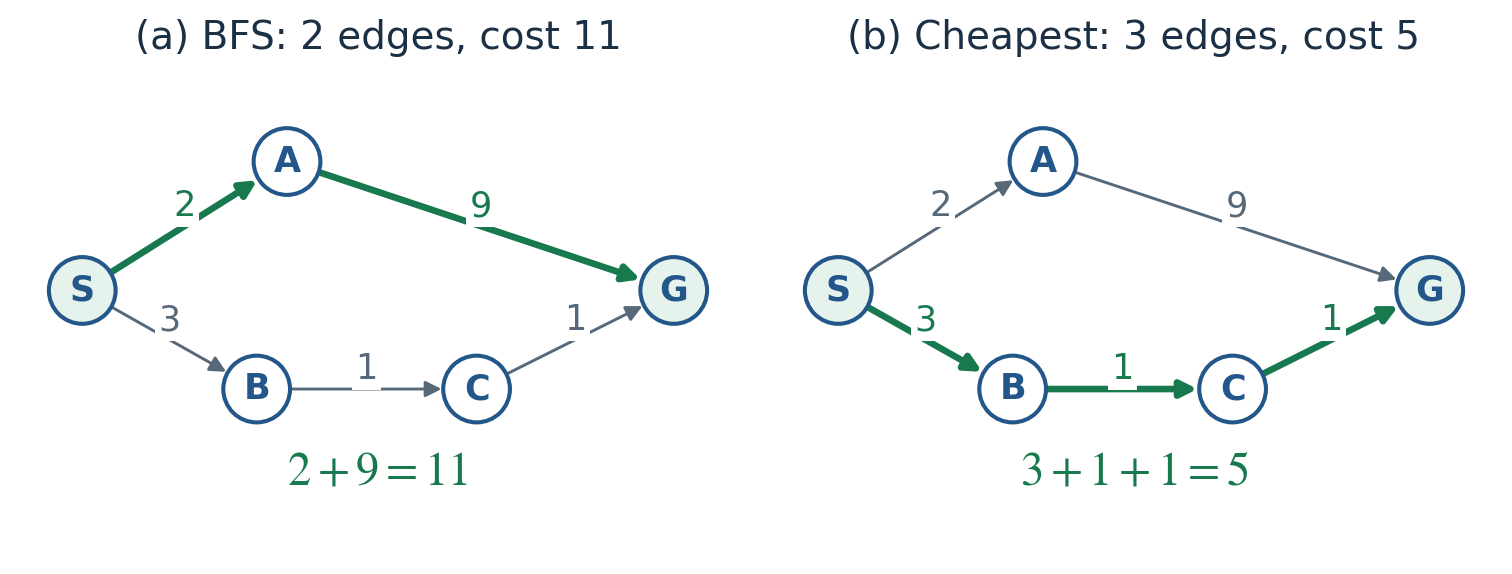

*Figure 3. 이동 횟수가 많아도 전체 비용은 더 작을 수 있다. 비용의 합을 최소화하려는 문제에서는 두 경로의 edge 수가 아니라 비용 11과 5를 비교해야 한다.*

$g(v)$에는 **지금까지 발견한 경로 중** $v$에 도착하는 가장 저렴한 경로의 비용을 기록한다. 이 값은 실제로 찾은 경로에서 계산하므로, $v$까지의 실제 최소 비용보다 작아지지 않는 upper bound다.

$$
\begin{aligned}
g(s)&=0,\\
g(v)&=\infty\quad(v\ne s)\text{ initially}.
\end{aligned}
\tag{6}
$$

실제로 그 비용을 들여 도착할 수 있으므로 진짜 최솟값은 기록한 비용보다 클 수 없다. 아직 경로를 찾지 못한 state에는 `infinity`를 쓴다. 이는 “도달하는 경로를 아직 모른다”는 초기 표시일 뿐, 아주 큰 이동 비용을 뜻하거나 도달 불가능하다고 판정한 결과는 아니다. 코드에서는 `best_g.get(v, float("inf"))`로 이 기본값을 얻는다. 모든 state를 dictionary에 미리 등록하지 않아도 된다.

$u$를 expand하면서 이웃 $v$를 확인하면, 지금까지의 경로에 edge 하나를 붙인 후보를 만들 수 있다.

$$
g_{\mathrm{candidate}}(v)=g(u)+c(u,v).
$$

이 후보가 더 저렴하면 비용과 parent를 함께 갱신한다.

$$
\begin{gathered}
\text{if }g(u)+c(u,v)<g(v):\\
\begin{aligned}
g(v)&\leftarrow g(u)+c(u,v),\\
\operatorname{parent}(v)&\leftarrow u.
\end{aligned}
\end{gathered}
\tag{7}
$$

이렇게 더 저렴한 경로로 기록을 바꾸는 연산이 **relaxation**이다. 조건에서 등호를 빼는 것이 중요하다. 비용이 같은 경로로 바꿔도 최소 비용을 찾는 데 도움이 되지 않는다. 오히려 zero-cost cycle에서는 같은 비용의 경로를 계속 갱신하게 될 수 있다.

앞의 graph에서 A를 expand하면 G에 도착하는 비용이 `2 + 9 = 11`인 경로를 발견한다. G의 비용을 infinity에서 11로 바꾸고 parent에는 A를 기록한다. 이후 C를 expand하면 `4 + 1 = 5`인 경로를 발견한다. 5가 더 작으므로 비용을 5로 낮추고 parent도 C로 바꾼다. 비용만 바꾸고 parent를 남겨 두면, 경로를 복원할 때 예전 경로를 따라가게 된다. 두 기록을 함께 바꿔야 하는 이유다. Relaxation은 더 좋은 경로를 발견했을 때 무엇을 갱신할지 정하는 연산이고, 다음에 어떤 state를 expand할지는 frontier의 처리 규칙이 정한다.

## 6. Dijkstra: 지금까지의 비용이 가장 작은 후보를 꺼낸다

**Dijkstra's algorithm**은 frontier에서 $g$가 가장 작은 후보부터 꺼낸다. 특정 목적지를 찾는 데 사용할 때는 **uniform-cost search**라고도 부른다. 이런 순서로 후보를 처리하려면 **priority queue**가 필요하다. Priority queue에서는 언제 넣었는지가 아니라 priority 값이 가장 작은 항목부터 꺼낸다. Binary min-heap으로 구현하면 삽입과 제거에 각각 로그 시간이 걸린다.

BFS에서는 먼저 발견한 후보가 먼저 나온다. Dijkstra에서는 나중에 발견했더라도 경로 비용이 더 작으면 먼저 나온다. Edge마다 비용이 다를 때 필요한 차이다. Heap을 쓰면 새로 넣은 저렴한 후보를 앞서 넣은 비싼 후보보다 먼저 꺼낼 수 있고, 삽입할 때마다 frontier 전체를 정렬할 필요도 없다.


In [8]:
from heapq import heappush, heappop
from itertools import count

def dijkstra(graph, start, goal):
    serial = count()  # A unique tie-breaker; nodes need not be comparable.
    heap = [(0, next(serial), start)]
    best_g = {start: 0}
    parent = {start: None}

    while heap:
        g_entry, _order, u = heappop(heap)
        if g_entry != best_g[u]:
            continue  # A newer, cheaper entry superseded this one.
        if u == goal:
            return reconstruct(parent, goal), g_entry

        for v, edge_cost in graph.get(u, []):
            if edge_cost < 0:
                raise ValueError("Dijkstra needs nonnegative edge costs")
            candidate = g_entry + edge_cost
            if candidate < best_g.get(v, float("inf")):
                best_g[v] = candidate
                parent[v] = u
                heappush(heap, (candidate, next(serial), v))
    return None, float("inf")

assert dijkstra(graph, "S", "G") == (["S", "B", "C", "G"], 5)


이 코드는 graph의 모든 비용이 유한하다고 가정한다. 반복문 안에서는 살펴본 edge의 비용이 음수인지 검사한다. 다만 목적지를 찾으면 모든 edge를 확인하기 전에 끝날 수 있다. 따라서 이 검사만으로 graph 전체에 음수 edge가 없다고 보장할 수는 없다.

Heap에는 `(cost, serial, state)` 형태의 tuple을 넣는다. Python은 tuple의 왼쪽 원소부터 비교하므로 cost가 작은 항목이 먼저 나온다. Cost가 같으면 `count()`가 만든 서로 다른 serial을 비교해 먼저 넣은 항목을 고른다. Serial이 항상 다르기 때문에 state object끼리 직접 비교하다가 오류가 날 일도 없다. `g_entry`는 *그 항목을 넣었을 때* 저장한 비용이고, `best_g[u]`는 현재까지 찾은 최소 비용이다. 두 값이 다르면 더 저렴한 경로가 나온 뒤에도 heap에 남아 있던 예전 항목이다. Serial은 `_order`로 받아 두지만 꺼낸 뒤의 계산에는 사용하지 않는다.

앞에서 정의한 graph로 실행 과정을 따라가 보자. 표의 queue는 꺼내는 순서대로 정렬해서 적었고, serial은 생략했다. 실제 heap 배열이 이 순서로 저장되는 것은 아니다.

| 꺼낸 유효한 항목 | 갱신 내용 | 처리 후 queue |
| --- | --- | --- |
| S, cost 0 | A는 2, B는 3 | A:2, B:3 |
| A, cost 2 | G는 11, parent는 A | B:3, G:11 |
| B, cost 3 | C는 4 | C:4, G:11 |
| C, cost 4 | G를 5로 개선, parent는 C | G:5, G:11 (예전 항목) |
| G, cost 5 | 최소 비용 확정 후 경로 복원 | G:11은 쓰지 않고 남음 |


G는 C보다 먼저 발견했지만, C의 비용 4가 G의 비용 11보다 작으므로 C를 먼저 처리한다. 여기서 더 저렴한 경로를 찾으면 queue에 G의 항목이 두 개가 된다. 하지만 현재 최소 비용을 기록하는 `best_g["G"]`의 값은 5 하나다. 마지막 parent를 따라가면 G ← C ← B ← S이므로 비용 5인 경로를 복원할 수 있다.

### 6.1 왜 발견할 때가 아니라 꺼낼 때 종료할까?

$g^{\ast}(v)$를 $s$에서 $v$까지의 진짜 최소 비용이라고 하자. Dijkstra에서는 예전 기록이 아닌 유효한 항목을 최소 $g$ 순서로 꺼냈다면, 그 비용은 반드시 $g^{\ast}(v)$다. 탐색하는 동안 계속 유지되는 이 성질을 invariant라고 한다.

이렇게 최소 비용이 확정된 state를 **settled**라고 한다. 꺼내기 전의 값은 아직 바뀔 수 있는 **tentative** cost다. 그림에서 state 옆에 숫자가 표시됐더라도 곧바로 확정값으로 읽으면 안 된다. Dijkstra가 보장하는 것은 단순히 “현재 queue에서 가장 작은 값”인 데 그치지 않는다. 모든 edge cost가 0 이상이므로, 앞으로 다른 경로를 더 살펴봐도 그보다 저렴한 경로는 나오지 않는다.

왜 그럴까? 방금 꺼낸 state $u$에 도착하는 더 저렴한 경로가 따로 있다고 가정해 보자. 그 경로를 시작점부터 따라가며 아직 settled가 아닌 첫 state $x$를 고른다. 바로 앞 state는 이미 settled이므로 이를 expand할 때 $x$로 가는 항목도 queue에 넣었을 것이다. 남은 edge cost가 모두 0 이상이니, 이 항목의 비용은 가정한 경로를 따라 $u$까지 가는 비용보다 크지 않다. 그러면 $u$보다 먼저 꺼낼 더 저렴한 후보가 queue에 있었다는 결론이 나온다. $u$를 최소 비용 후보로 꺼냈다는 사실과 모순이다.

따라서 목적지의 유효한 항목이 queue의 최소 비용 항목으로 나올 때 탐색을 끝내면 된다. 처음 목적지를 발견한 순간에는 이 근거가 없다. 앞의 예에서도 A를 expand할 때 비용 11인 경로를 발견했지만, B와 C를 처리하면 비용 5인 경로가 나온다.

### 6.2 예전 heap 항목은 왜 그대로 둘까?

Python의 `heapq`에는 기존 항목의 priority를 낮추는 decrease-key 연산이 없다. 대신 어떤 state의 비용이 11에서 5로 줄면 새 항목을 넣고 예전 항목은 남겨 둔다. 나중에 예전 항목을 꺼냈을 때 저장된 비용과 `best_g`가 다르면 버린다. 필요할 때 오래된 항목을 걸러 내는 이 방식을 **lazy deletion**이라고 한다. [Python heap 문서](https://docs.python.org/3/library/heapq.html#priority-queue-implementation-notes)에서도 같은 priority queue 구현 방식을 소개한다.

Heap 배열은 전체를 정렬해 놓은 list와 다르다. 최솟값이 root에 있다는 것은 보장하지만 나머지 항목이 비용순으로 나열되지는 않는다. 화면에 정렬해서 보여 주는 frontier도 읽기 편하게 순서를 바꿔 표시한 것으로, 내부 배열의 배치와 구분해야 한다.

### 6.3 배달 경로: 도로 수는 적은데 시간은 더 걸린다

여덟 지점을 연결한 도로망이다. 도로에 적힌 숫자는 이동 시간이며 단위는 분이다. A–H로 바로 가면 18분, 위쪽의 A–B–C–H로 가면 12분, 아래쪽의 A–D–E–F–G–H로 가면 10분이 걸린다. 도로를 더 많이 거치는 아래쪽 경로가 가장 빠르다. 그림에서 길어 보이는 도로가 반드시 오래 걸리는 것은 아니다. 이동 시간은 좌표가 아니라 도로에 적힌 값으로 정한다.


**배달 경로 퍼즐.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-dijkstra-delivery)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


서로 연결된 지점들을 클릭해 배달 경로를 직접 정하고 Dijkstra의 답과 비교해 보자. 그다음 교통량을 늘리거나 다리를 막아 보자. 처음 골랐던 경로가 여전히 가장 빠를까? 지나갈 수 있는 경로라도 교통량이 달라지면 다른 경로보다 느려질 수 있다. 아래쪽 도로의 시간을 세 배로 늘리면 위쪽의 12분 경로가 최적이다. E–F를 막아도 최적 비용은 12분이 된다. H로 통하는 도로를 전부 막으면 배달할 경로가 없다.

Solver의 과정을 볼 때는 H에 처음 숫자가 표시되는 시점과 H의 유효한 항목을 최소 비용 후보로 꺼내는 시점을 비교해 보자. 처음 숫자가 나왔을 때는 경로 하나를 찾았을 뿐이다. 최소 비용이 확정되어 탐색을 끝낼 수 있는 것은 후자다.

직접 클릭해서 만든 것은 실제로 따라갈 배달 경로 하나다. 반면 solver의 frontier에는 여러 경로의 후보가 동시에 들어 있다. 도로의 숫자와 node의 숫자도 구분하자. 도로에는 해당 도로를 지나는 데 걸리는 시간을, node에는 A에서 그곳까지의 누적 시간을 표시한다. 단위는 모두 분이지만 하나는 edge cost이고 다른 하나는 경로 비용이다. 교통량이나 폐쇄 조건을 바꿨다면 탐색도 다시 시작해야 한다. 이전 tentative cost는 바꾸기 전의 도로망에서 계산한 값이기 때문이다.

### 6.4 두 곳에서 출동하기: 시작점이 여러 개여도 한 번에 탐색한다

E에 긴급 상황이 생겼고 A와 H에 있는 station 중 한 곳에서 출동한다고 하자. 구하려는 값은 두 station을 모두 거치는 경로가 아니라 **둘 중 더 빨리 도착할 수 있는 시간**이다. 두 station을 각각 비용 0으로 같은 priority queue에 넣고 시작하면 된다. 이후에는 보통의 relaxation을 하면서 최소 도착 시간과 그 경로의 출발 station을 함께 기록한다. Station의 집합을 $\mathcal S$, $d(s,v)$를 $s$에서 $v$까지의 최소 이동 시간이라고 하면 다음 값을 구하는 것이다.

$$
d_{\mathcal S}(v)=\min_{s\in\mathcal S}d(s,v).
$$


**여러 station에서 출동하기.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-dijkstra-dispatch)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


Station의 위치나 도로 조건을 바꾸고 어느 station에서 출동해야 더 빠를지 예상해 보자. 기본 도로망에서 station이 A와 H라면, E에는 A에서 4분, F에는 H에서 4분 만에 도착한다. Station을 A와 G에 두면 E까지는 양쪽 모두 4분이다. 시간이 같을 때 화면에 표시할 담당 station은 정해진 tie-break 규칙으로 고른다. 표시된 쪽이 실제로 더 빠른 것은 아니다.

이것이 **multi-source Dijkstra**다. 각 지점마다 가장 빨리 도착할 station과 시간을 계산한다. 같은 station이 여러 지점의 담당으로 나올 수 있지만, 이 계산에는 차량 수나 출동 일정이 들어 있지 않다. 여러 긴급 상황이 동시에 생겼을 때 차량을 어떻게 나눌지도 별도의 문제다.


#### 참고: Python에서는 가상의 super-source를 연결해 볼 수 있다


In [9]:
roads = [("A", "H", 18), ("A", "B", 4), ("B", "C", 4), ("C", "H", 4),
         ("A", "D", 2), ("D", "E", 2), ("E", "F", 2), ("F", "G", 2),
         ("G", "H", 2), ("B", "E", 3), ("C", "F", 3)]
town = {name: [] for name in "ABCDEFGH"}
for u, v, minutes in roads:
    town[u].append((v, minutes))
    town[v].append((u, minutes))

super_source = object()
dispatch_graph = {u: edges[:] for u, edges in town.items()}
dispatch_graph[super_source] = [("A", 0), ("H", 0)]
assert dijkstra(town, "A", "H")[1] == 10
assert dijkstra(dispatch_graph, super_source, "E")[1] == 4
assert dijkstra(dispatch_graph, super_source, "F")[1] == 4


가상의 시작점에서 각 station으로 비용 0인 edge를 연결하면 기존 `dijkstra` 함수를 그대로 사용할 수 있다. 이 edge는 실제 도로가 아니라 여러 출발점을 하나로 묶기 위한 장치다. Browser의 실습에서는 가상 vertex 없이 두 station을 직접 비용 0으로 넣는다. 계산되는 최소 도착 시간은 같다.



## 7. Heuristic: 더 쉬운 문제의 답으로 남은 비용을 추정한다

Heuristic $h(n)$은 $n$에서 목적지까지 앞으로 얼마나 더 비용이 들지 추정하는 함수다. 추정하려는 대상은 남은 경로 중 가장 저렴한 경로의 비용이다. A\* 자체에는 이 함수를 학습하는 과정이 없다. 문제에 맞는 함수를 따로 만들어 제공해야 한다.

Dijkstra는 출발 후 누적한 비용만 비교한다. 그 값만으로는 앞으로 목적지까지 가는 데 얼마나 더 들지 알 수 없다. 이때 필요한 정보가 heuristic이다. `best_g`에는 “여기까지 오는 데 든 비용”을 기록하고, heuristic으로는 “여기서 목적지까지 더 들 비용”을 추정한다. 목적지가 정해져 있다면 현재 state를 입력으로 받는 간단한 함수로 만들 수 있다. 탐색 중에는 필요할 때 이 함수만 계산하면 된다. 매번 별도의 최단 경로 탐색을 실행할 필요는 없다.

두 값이 바뀌는 이유도 다르다. 같은 state까지 더 저렴하게 오는 경로를 찾으면 기록한 도착 비용은 줄어든다. 반면 그 state에서 목적지까지의 문제는 그대로이므로, 고정된 heuristic의 값은 바뀌지 않는다. State와 목적지, 이후의 이동 규칙이 같다는 조건에서다. 또한 heuristic은 성공 확률이나 추정의 신뢰도가 아니라 **비용의 추정값**이므로, 실제 경로 비용과 같은 단위를 써야 한다.

상하좌우로만 움직이는 grid를 생각해 보자. 벽을 모두 없애고 각 이동 비용을 공통 lower bound $a$로 낮추면 원래보다 쉬운 문제가 된다. 실제 수평·수직 이동 비용이 각각 적어도 $a$라면, 이렇게 바꾼 grid에서 $(x,y)$부터 $(x_t,y_t)$까지의 최소 비용은 다음과 같다.

$$
\begin{aligned}
h_{\mathrm{Manhattan}}(n)
&=a\bigl(\lvert x-x_t\rvert\\
&\qquad+\lvert y-y_t\rvert\bigr).
\end{aligned}
\tag{8}
$$

이 값이 lower bound가 되는 이유는 이동 규칙에서 찾을 수 있다. 목적지에 도착하려면 가로 좌표 차이와 세로 좌표 차이를 모두 없애야 한다. 상하좌우 이동 한 번으로는 한 좌표만 한 칸 바꿀 수 있다. 벽 때문에 돌아가면 이동 횟수가 늘 수는 있지만, 벽이 있다고 꼭 필요한 좌표 변화가 줄어들지는 않는다.

이처럼 제약을 없애고 기존 이동의 비용도 올리지 않도록 만든 문제가 **relaxed problem**이다. 쉬워진 문제의 최적 비용은 원래 문제의 최적 비용보다 클 수 없다. 따라서 relaxed problem의 정확한 답을 원래 문제의 lower bound로 사용할 수 있다. 감으로 숫자를 정하는 대신, 과대평가하지 않는다는 근거까지 갖춘 heuristic을 만드는 방법이다. Berkeley의 [informed search 강의 노트](https://inst.eecs.berkeley.edu/~cs188/textbook/search/informed.html)도 이 원리로 heuristic을 설명한다.

예를 들어 현재 위치가 2열 1행이고 목적지가 6열 4행이라고 하자. 가로로 최소 네 번, 세로로 최소 세 번 이동해야 한다. 한 번의 이동 비용이 적어도 2라면, 벽을 없애고 비용을 2로 낮춘 문제의 답은 14다. 벽을 피해 돌아가느라 실제 최소 비용이 18이 될 수는 있어도 14보다 작아질 수는 없다. 14는 좌표와 최소 이동 비용만으로 바로 계산한다. 실제 답인 18을 알아내려면 벽을 피해 갈 경로를 탐색해야 한다. Heuristic은 이처럼 정답을 직접 구하는 것보다 적은 계산으로 탐색에 쓸 정보를 제공할 때 유용하다.

### 7.1 Greedy best-first search는 추정값만 사용한다

**Greedy best-first search**는 다음 값으로 후보의 순서를 정한다.

$$
f_{\mathrm{greedy}}(n)=h(n).
\tag{9}
$$

목적지까지 남은 추정 비용이 작은 후보를 우선하므로 빠르게 goal을 찾을 수 있다. 다만 그 후보에 도착하기까지 든 비용은 비교하지 않는다. 목적지에 가까워 보이는 state라도 그곳까지 오는 데 이미 큰 비용을 썼을 수 있다.

앞의 graph에 다음 heuristic을 적용하자. 각 값은 탐색 중 바뀌지 않는다.

$$
\begin{aligned}
h(S)&=3,\quad h(A)=1,\\
h(B)&=2,\quad h(C)=1,\\
h(G)&=0.
\end{aligned}
$$

이 값들은 모두 남은 비용의 lower bound이고, 뒤에서 정의할 consistency도 만족한다. 그런데도 greedy는 B보다 A를 먼저 고르고, A에서 G를 발견하면 B보다 G를 먼저 골라 비용 11인 경로를 반환한다. Heuristic이 이런 조건을 갖췄어도 $g$를 비교하지 않는 greedy에서는 최소 비용을 보장할 수 없다.

| S를 expand한 직후의 후보 | $g$ | $h$ | Dijkstra: $g$ | Greedy: $h$ | A\*: $g+h$ |
| --- | ---: | ---: | ---: | ---: | ---: |
| A | 2 | 1 | 2 | 1 | 3 |
| B | 3 | 2 | 3 | 2 | 5 |

Dijkstra와 A\*도 여기서는 A를 먼저 expand한다. 차이는 A에서 G를 **발견한 다음**에 드러난다. Greedy에서 G의 priority는 0이지만 A\*에서는 11이다. A\*는 더 작은 priority의 다른 후보가 남아 있으므로 탐색을 계속한다.

“이미 쓴 비용”은 후보 경로별로 계산한다. 탐색 알고리즘이 한 사람처럼 graph 위를 걸어 다니며 쓴 비용을 모두 더하는 것은 아니다. 여러 후보를 함께 보관하기 때문에 A를 처리한 다음 B를 골라도 A에서 B로 돌아갈 필요가 없다. Greedy는 G에서 목적지까지 남은 비용이 0이라는 점만 본다. G에 도착하는 비용 11의 경로와 B에 도착하는 비용 3의 미완성 경로를 전체 예상 비용으로 비교하지 않는다.


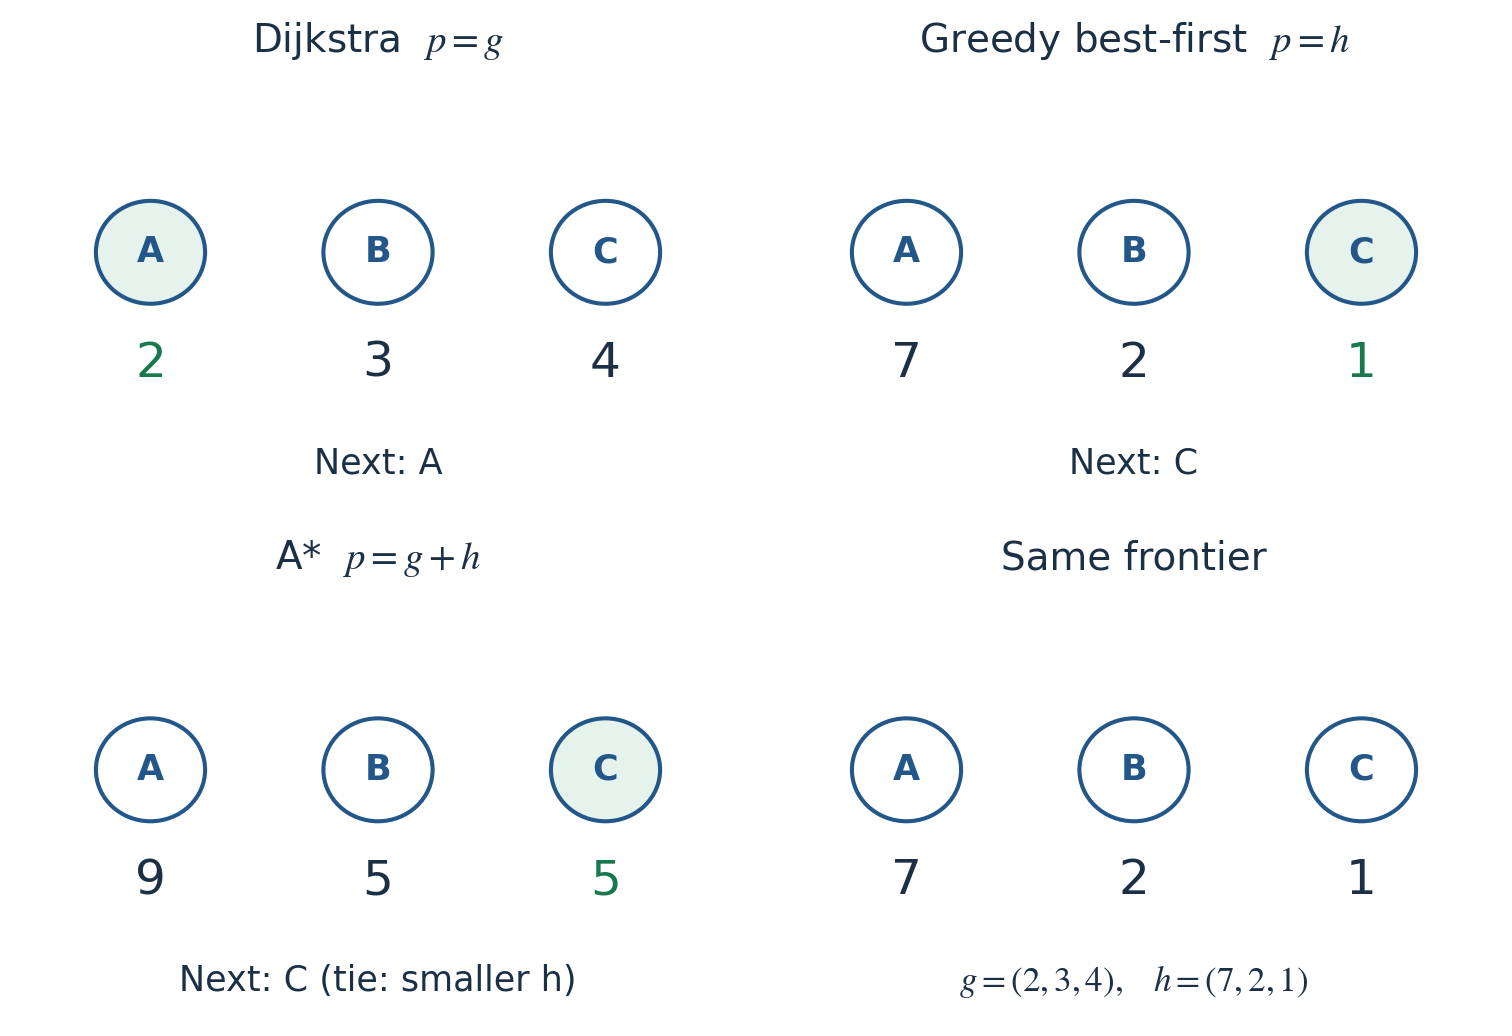

*Figure 4. 위 표와 달리 후보가 세 개인 별도의 예제다. Dijkstra는 A를, greedy와 A\*는 C를 고른다. B와 C는 $g+h=5$로 같고, 여기서는 $h$가 작은 쪽을 우선하는 tie-break에 따라 C를 고른다. Heuristic을 더하면 탐색 순서가 바뀐다. 최소화하려는 경로 비용과 relaxation 규칙은 그대로다.*

## 8. A\*: 지금까지의 비용과 남은 비용을 더한다

A\*는 지금까지 든 비용에 앞으로 들 것으로 추정한 비용을 더해 priority를 정한다.

$$
f(n)=g(n)+h(n).
\tag{10}
$$

$g(n)$은 시작점에서 현재 state까지 발견한 경로, 즉 prefix에 실제로 든 비용이다. $h(n)$은 그 뒤로 목적지까지 이어 갈 경로, 즉 suffix의 최소 비용을 추정한다. 둘의 합은 **현재 후보 경로를 거쳐 목적지까지 가는 전체 예상 비용**이다. Heuristic을 계산할 때 장애물을 무시했을 수도 있으므로, 이 추정값과 비용이 정확히 같은 실제 경로가 존재할 필요는 없다.

$h\equiv0$으로 놓으면 후보를 비교하는 기준이 Dijkstra와 같아진다. Tie-break까지 같게 처리하면 동작도 같다. A\*는 Dijkstra와 무관한 새 탐색 방식이 아니라, 같은 relaxation에 목적지까지의 추정 비용을 더해 순서를 정하는 알고리즘이다.

여기서 평가하는 대상은 state 하나가 아니라 **그 state까지 기록한 후보 경로와 그 이후의 예상 비용을 합친 값**이다. 지금까지 찾은 prefix 뒤에 가장 저렴한 경로를 이어 간다고 생각하면 된다. 시작점에서의 직선거리를 나타내는 값도 아니고, 이미 완성한 경로에서 계산한 비용일 필요도 없다. 합이 가장 작은 후보를 꺼내는 것은 그 후보를 다음에 더 살펴보겠다는 선택이다. 그 경로로 끝까지 가겠다고 확정하는 단계는 아니다.

앞의 graph로 실행 순서를 따라가 보자. 괄호에는 `(g, h, f)`를 적었다. 같은 state의 기록이 여러 개라면 현재 유효한 최신 항목만 표시했다.

| 여기까지 expand한 state | 유효한 frontier 항목 | 다음에 꺼낼 항목 |
| --- | --- | --- |
| 아직 없음 | S `(0, 3, 3)` | S |
| S | A `(2, 1, 3)`; B `(3, 2, 5)` | A |
| A | B `(3, 2, 5)`; G `(11, 0, 11)` | B |
| B | C `(4, 1, 5)`; G `(11, 0, 11)` | C |
| C | G `(5, 0, 5)` | G: 비용 5 반환 |


A\*도 처음에는 A를 고른다. Heuristic이 첫 선택부터 정답 경로를 알아맞혀야 하는 것은 아니다. 비싼 goal을 발견했더라도 더 작은 priority의 후보가 남아 있으면 그 후보를 먼저 살펴보는 것이 중요하다. C를 expand하면 G까지의 기록이 비용 5인 경로로 바뀐다. Heap 안에 비용 11인 예전 항목이 남아 있을 수는 있지만, 현재 가장 저렴한 경로는 비용 5인 쪽이다.

### 8.1 Admissibility: 실제 남은 최소 비용보다 크게 추정하지 않는다

$n$에서 $t$까지 가는 진짜 최소 비용을 $h^{\ast}(n)$이라고 하자. 0 이상인 heuristic이 다음을 만족하면 **admissible**하다고 한다.

$$
\begin{gathered}
0\le h(n)\le h^{\ast}(n),\\
h(t)=0.
\end{gathered}
\tag{11}
$$

목적지로 갈 수 없는 state에서는 $h^{\ast}(n)=\infty$이므로 유한한 heuristic을 써도 이 부등식을 만족한다. 문제는 목적지에 갈 수 있는 state에서 남은 비용을 실제보다 크게 잡는 경우다. 그러면 저렴한 경로의 priority를 지나치게 높여 탐색을 뒤로 미룬 사이, 더 비싼 goal 경로를 답으로 반환할 수 있다.

기록한 $g(n)$의 성질과 비교해 보자. $g(n)$은 실제로 발견한 경로의 비용이므로 $g(n)\ge g^{\ast}(n)$이다. 도착 비용은 실제 최솟값 이상의 값을 기록하고, 남은 비용은 실제 최솟값 이하로 추정하는 셈이다. 두 값은 서로 다른 구간의 비용에 대한 조건이다.

$g^{\ast}(n)$은 **시작점에서 해당 state까지**의 실제 최소 비용이고, $h^{\ast}(n)$은 **해당 state에서 목적지까지**의 실제 최소 비용이다. 별표는 최적값을 구분하는 기호다. 알고리즘은 이 값들을 미리 알고 시작하지 않는다. `best_g`에는 지금까지 찾은 가장 저렴한 prefix의 비용을 저장하고, suffix의 비용은 주어진 heuristic으로 추정한다.

그렇다면 heuristic이 admissible하면 모든 $f(n)$도 전체 최적 비용의 lower bound일까? 그렇지는 않다. 어떤 state까지 현재 기록한 비용은 8, 실제 최소 비용은 4라고 하자. 남은 실제 비용이 3이고 heuristic이 2라면 현재 추정값은 10이다. 하지만 그 state를 거치는 최적 경로의 비용은 7이다. Heuristic에는 문제가 없다. 아직 그 state까지의 최적 prefix를 찾지 못해서 차이가 생겼다. 따라서 최적성을 증명할 때는 아무 frontier 항목이 아니라 **prefix 비용이 이미 최적인 항목**이 필요하다.

### 8.2 Admissible A\*는 왜 최적 경로를 반환할까?

Graph는 유한하고 edge cost는 모두 유한한 0 이상의 값이라고 하자. 탐색 중에는 고정된 admissible heuristic을 쓴다. 구현에서는 **이미 처리한 state라도 더 저렴한 경로를 찾으면 다시 후보로 넣고**, 유효한 goal 항목을 priority queue에서 꺼낼 때 끝낸다. 이미 처리한 state를 다시 탐색 대상으로 넣는 것이 reopening이다.

증명의 핵심은 다음과 같다. 최적 goal을 아직 꺼내지 않았다면, 최적 경로 위의 어떤 state $n$은 최적 prefix 비용을 가진 채 frontier에서 기다리고 있다. 그 앞 state를 최적 비용으로 expand하면 relaxation을 통해 이 항목이 생긴다. 같은 state를 전에 더 비싼 경로로 expand했더라도, reopening을 허용하므로 더 저렴한 경로를 반영할 수 있다.

이 항목이 항상 존재하는 이유를 최적 경로 하나를 따라 확인해 보자. 시작점은 비용 0으로 frontier에 들어가므로 처음부터 최적 비용이 기록되어 있다. 이 경로의 한 state를 최적 prefix 비용으로 expand하면 다음 edge를 relaxation하면서 다음 state에도 최적 비용을 기록한다. 그다음 state는 frontier에서 차례를 기다리거나, 이미 그 비용으로 expand되어 다음 state를 같은 방식으로 처리했을 것이다. 아직 최적 goal을 꺼내지 않았다면, 이 경로에서 다음 처리를 기다리는 항목이 적어도 하나는 남아 있어야 한다.

여기에는 최적 경로의 prefix도 최적이라는 성질을 사용했다. 중간 state까지 더 저렴하게 올 수 있다면 그 경로로 앞부분만 바꿔 전체 비용을 줄일 수 있다. 그러면 원래 경로가 최적이었다는 가정과 모순된다. Reopening은 이 최적 비용이 중간에서 막히지 않게 해 준다. 어떤 state를 전에 더 비싼 경로로 처리했어도, 더 저렴한 비용으로 다시 처리해 다음 state에 반영할 수 있다.

이렇게 최적 prefix 비용을 기록한 항목에는 다음 관계가 성립한다.

$$
\begin{aligned}
f(n)&=g^{\ast}(n)+h(n)\\
&\le g^{\ast}(n)+h^{\ast}(n)\\
&=C^{\ast}.
\end{aligned}
\tag{12}
$$

이제 A\*가 비용 $C>C^{\ast}$인 goal을 꺼내려 한다고 가정하자. 이 goal의 priority는 $C+h(t)=C$다. 그러나 frontier에는 priority가 $C^{\ast}$ 이하인 항목이 아직 남아 있다. Min-priority queue라면 그 항목을 먼저 꺼내야 하므로 더 비싼 goal을 먼저 꺼낼 수 없다. 따라서 반환하는 goal의 비용은 $C^{\ast}$다.

코드에서도 이 논리에 맞춰 두 가지를 지켜야 한다. 첫째, goal의 heuristic은 0으로 둬야 한다. 그래야 goal의 priority가 기록한 경로 비용과 같아진다. 둘째, goal을 처음 발견했을 때가 아니라 queue에서 가장 작은 **유효한** 항목으로 꺼냈을 때 종료한다. 비용 11인 goal을 처음 발견했던 위 예제처럼, 발견 시점에는 더 작은 priority의 다른 후보가 남아 있을 수 있다.

여기서 증명한 것은 반환하는 경로의 최적성이다. *모든* state를 최적 prefix 비용으로만 expand한다는 더 강한 성질을 얻으려면 consistency가 필요하다. 또한 A\*는 최종 경로 밖의 state도 탐색할 수 있다. Heuristic이 낮은 비용을 예상한 후보가 실제로는 막다른 길로 이어질 수도 있기 때문이다.


#### 참고: 유한한 graph와 strict update 조건이 중요한 이유


유한한 graph에서 비용이 0 이상이면, 더 저렴할 때만 갱신하는 strict improvement 조건 덕분에 zero-cost cycle에서 같은 비용으로 갱신을 반복하지 않는다. 경로가 없을 때는 도달 가능한 후보를 모두 처리하고 실패를 반환할 수 있다. 무한한 state space에서는 조건이 더 필요하다. 해가 있으면 반드시 찾는 성질을 completeness라고 하는데, 이를 보장하려면 보통 각 state의 successor 수가 유한하고 모든 step cost가 양수인 공통 lower bound $\epsilon$ 이상이라고 가정한다. 그래야 유한한 비용 한도 안에 있는 관련 경로도 유한 개로 제한된다. 유한한 grid에서 탐색이 끝났다는 사실만으로 모든 무한 planning 문제에서도 종료한다고 보장할 수는 없다.



## 9. Consistency: 이미 처리한 state를 다시 열어야 하는 이유

Admissibility는 각 state의 추정값이 목적지까지 실제로 필요한 최소 비용을 넘지 않는다는 조건이다. **Consistency**는 이웃한 두 state의 추정값 사이에도 다음 관계가 성립할 것을 요구한다. 모든 directed edge에서 확인해야 하는 조건이다.

$$
\begin{gathered}
h(u)\le c(u,v)+h(v),\\
h(t)=0.
\end{gathered}
\tag{13}
$$

$u$에서 바로 다음 state로 이동하는 비용에 그곳의 추정값을 더해 보자. 이 합이 이동 전의 추정값보다 작아지면 안 된다. Triangle inequality와 비슷한 조건이다. 목적지까지 이어지는 경로의 edge마다 이 부등식을 적용하면 $h(u)\le C(u\leadsto t)$를 얻는다. 가장 저렴한 경로에도 성립하므로 admissibility도 만족한다.

두 조건의 차이는 비교 대상에 있다. Admissibility를 확인하려면 목적지까지의 실제 최소 비용을 알아야 하는데, 이를 구하는 데 큰 계산이 필요할 수도 있다. Consistency는 이웃한 두 state의 추정값과 이미 아는 edge cost 하나만 비교하면 된다. 예를 들어 edge cost가 1이고 이동 후 heuristic이 0이라면, 이동 전 heuristic은 최대 1이어야 consistent하다. 이동 전 값이 4라면 목적지까지 실제로 비용이 4 이상 들더라도 consistency는 위반한다. 전체 비용은 과대평가하지 않았지만, 비용 1짜리 이동 한 번에 추정값이 4나 줄었기 때문이다.

발견한 특정 경로에서 $g(v)=g(u)+c(u,v)$이므로

$$
\begin{aligned}
f(v)-f(u)&=c(u,v)\\
&\quad+h(v)-h(u)\\
&\ge0.
\end{aligned}
\tag{14}
$$

이다. 즉, 이 경로를 따라 한 step씩 이동할 때 priority는 줄어들지 않는다. Consistent A\*에서는 stale entry를 제외한 첫 expansion 때 해당 state까지의 최적 비용이 확정된다. 그러므로 한 번 처리한 state를 permanent closed set에 넣고 다시 처리하지 않아도 된다. 반면 admissible하지만 inconsistent한 heuristic에서는 뒤늦게 더 저렴한 경로가 발견될 수 있어, 같은 state를 다시 expand해야 할 수 있다.

### 9.1 네 state만으로 만드는 반례

다음 directed edge들을 사용하자.

$$
\begin{gathered}
S\to A:3,\quad S\to B:1,\\
B\to A:1,\quad A\to G:3,\\
B\to G:100.
\end{gathered}
$$

최적 경로는 $S\to B\to A\to G$이며 비용은 5다. Heuristic은 다음과 같이 정한다.

$$
\begin{aligned}
h(S)&=5,\quad h(A)=0,\\
h(B)&=4,\quad h(G)=0.
\end{aligned}
$$

실제로 남은 최소 비용은 각각 5, 3, 4, 0이다. 어느 추정값도 이를 넘지 않으므로 모두 admissible하다. 하지만 $B\to A$에서는 $4>1+0$이므로 consistency를 위반한다.

S를 expand한 직후 A는 $(g,f)=(3,3)$, B는 $(1,5)$다. Priority가 작은 A부터 expand하므로, 먼저 비용 6인 G 후보가 생긴다. 그다음 B를 expand하면 A까지 더 저렴하게 갈 수 있다는 사실을 발견하여 $g(A)=2$가 된다. A를 이미 처리했다는 이유로 무시하면, 이 경로를 거쳐 G의 비용도 줄일 수 있다는 사실을 놓쳐 비용 6을 반환한다. A를 reopen하면 priority 2로 다시 처리하고, G까지의 올바른 최적 비용 5를 얻는다.

B에서 A로 이동할 때 priority는 줄지만, 실제로 낸 비용은 늘어난다. Prefix 비용은 1에서 2로 증가한다. Priority가 5에서 2로 떨어지는 것은 비용 1짜리 edge를 지나는 동안 heuristic이 4에서 0으로 크게 줄기 때문이다. 한편 A에 도착하는 두 경로를 비교하면, 새 prefix의 비용 2가 예전에 기록한 비용 3보다 작다. **B에서 A로 이동하며 비용이 늘어나는 것**과 **A까지 가는 경로를 더 저렴한 것으로 바꾸는 것**은 서로 다른 비교다.

Reopening할 때는 A까지의 최소 기록 비용을 2로 고치고, parent를 S에서 B로 바꾼 뒤 frontier에 다시 넣는다. 이후 A를 다시 expand하면서 G의 비용도 5로 줄인다. 이때 G의 parent도 필요하면 고치고 새 goal 후보를 넣는다. 비용만 고치고 parent를 그대로 두면 복원한 경로와 비용이 맞지 않는다. 반대로 parent만 고치고 A를 다시 expand하지 않으면 G처럼 그 뒤에 있는 state의 비용은 갱신되지 않는다.


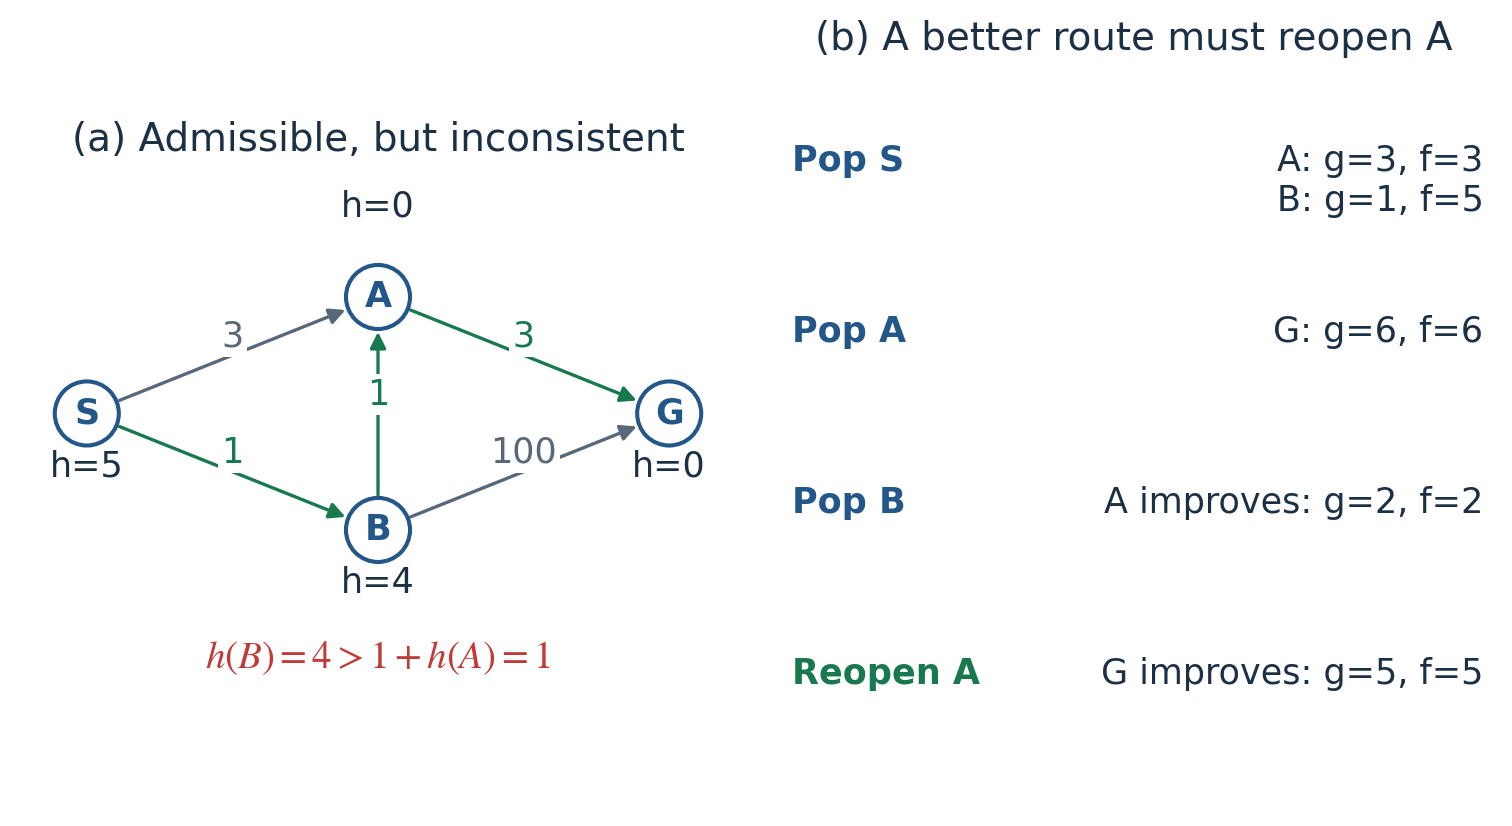

*Figure 5. Heuristic이 admissible해도 한 번 처리한 state를 영구적으로 무시해서는 안 되는 경우가 있다. 다음 구현은 더 저렴한 경로를 발견할 때마다 해당 state를 다시 queue에 넣는다.*

### 9.2 Heuristic 탐정: 어느 보장이 깨졌는지 찾아보자


**Heuristic 탐정.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-astar-detective)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


Admissible하지만 inconsistent한 예제를 고르고, 각 단계에서 다음에 꺼낼 state를 먼저 예상해 보자. Reopening을 켜고 실행한 뒤, 같은 graph에서 reopening만 끄고 다시 실행한다. A는 비용 3으로 먼저 expand되고, 나중에 B를 통해 비용이 2로 줄어든다. Reopening을 허용하면 답은 5지만, 한 번 처리한 A를 계속 무시하면 답은 6이다. Graph나 목표가 바뀐 것이 아니라, 새로 찾은 저렴한 prefix를 다음 계산에도 반영했는지가 결과를 가른다.

이번에는 비용을 과대평가하는 예제를 고르자. B에서 남은 실제 최적 비용은 4인데 heuristic은 8이다. 이 경우 reopening을 켜 두어도 B를 살펴보기 전에 비용 6인 goal에서 종료할 수 있다. Reopening은 뒤늦게 찾은 비용 개선을 반영하는 장치다. 잘못된 heuristic 때문에 유망한 후보를 너무 늦게 고르는 문제까지 해결하지는 못한다.

남은 최소 비용을 정확히 쓰는 예제와도 비교해 보자. **Admissibility**는 state별로, **consistency**는 edge별로 확인한다. Consistency 부등식을 어기는 edge가 하나라도 있으면 inconsistent하다. 정답 경로를 한 번 찾았다는 사실만으로는 두 조건을 만족하는지 판단할 수 없다.


#### 참고: Edge cost를 바꾸면 A*를 Dijkstra로 해석할 수 있다


새로운 edge cost를 다음과 같이 정의하자.

$$
\begin{aligned}
c_h(u,v)&=c(u,v)\\
&\quad+h(v)-h(u).
\end{aligned}
\tag{15}
$$

Consistency가 성립한다는 것은 새 비용이 $c_h(u,v)\ge0$을 만족한다는 것과 같다. S에서 $n$까지 새 edge cost를 모두 더하면, 중간 state의 heuristic 항들은 서로 상쇄된다.

$$
\begin{aligned}
g_h(n)&=g(n)+h(n)-h(s)\\
&=f(n)-h(s).
\end{aligned}
\tag{16}
$$

모든 priority에서 같은 상수 $h(s)$를 빼도 순서는 바뀌지 않는다. 따라서 consistent A\*의 탐색 순서는 새로 정의한 0 이상의 edge cost에 Dijkstra를 적용했을 때와 같다. 시작점부터 목적지까지 이어지는 경로들의 비용에도 같은 상수 $h(t)-h(s)$가 더해지므로, 어떤 경로가 가장 저렴한지도 달라지지 않는다. Dijkstra의 최적성 보장을 이 새 비용에 적용하면, consistent A\*가 최적 경로를 찾는 이유와 reopening이 필요 없는 이유를 함께 설명할 수 있다.



## 10. Lazy deletion과 reopening을 포함한 Python A\* 구현

`heuristic(node)`는 node를 받아 추정값을 돌려주는 함수이며, 탐색 도중 그 값이 바뀌어서는 안 된다. `weight`는 0 이상으로 지정한다. 일반 A\*는 `weight=1`, Dijkstra는 0을 사용하며, heuristic의 비중을 더 높이는 weighted A\*는 13절에서 다룬다. Graph는 앞과 같은 adjacency list 형식으로 전달한다.


In [10]:
import math

def astar(graph, start, goal, heuristic, weight=1.0):
    if not math.isfinite(weight) or weight < 0:
        raise ValueError("weight must be finite and nonnegative")

    # Cache a state-only heuristic: changing estimates during search would
    # invalidate this implementation's stored priorities and its proof.
    h_cache = {}
    def h(node):
        if node not in h_cache:
            value = float(heuristic(node))
            if not math.isfinite(value) or value < 0:
                raise ValueError("heuristic must be finite and nonnegative")
            h_cache[node] = value
        return h_cache[node]

    if h(goal) != 0:
        raise ValueError("the goal heuristic must be zero")
    serial = count()
    best_g = {start: 0.0}
    parent = {start: None}
    # Tuple fields: priority, h tie-breaker, unique serial, g snapshot, state.
    heap = [(weight * h(start), h(start), next(serial), 0.0, start)]
    expansion_order = []  # Includes repeated expansions after reopening.

    while heap:
        _priority, _h, _serial, g_entry, u = heappop(heap)
        if g_entry != best_g[u]:
            continue  # Skip an obsolete g snapshot before testing the goal.
        if u == goal:
            return reconstruct(parent, goal), g_entry, expansion_order

        expansion_order.append(u)
        for v, edge_cost in graph.get(u, []):
            if not math.isfinite(edge_cost) or edge_cost < 0:
                raise ValueError("edge costs must be finite and nonnegative")
            candidate = g_entry + edge_cost
            if not math.isfinite(candidate):
                raise OverflowError("path cost overflow")
            if candidate < best_g.get(v, math.inf):
                best_g[v] = candidate
                parent[v] = u
                # No closed-set rejection: even an expanded state may improve.
                heappush(heap, (candidate + weight * h(v), h(v),
                                next(serial), candidate, v))

    return None, math.inf, expansion_order

H = {"S": 3, "A": 1, "B": 2, "C": 1, "G": 0}
path, cost, expanded = astar(graph, "S", "G", H.__getitem__)
assert path == ["S", "B", "C", "G"] and cost == 5

reopen_graph = {
    "S": [("A", 3), ("B", 1)], "A": [("G", 3)],
    "B": [("A", 1), ("G", 100)], "G": [],
}
RH = {"S": 5, "A": 0, "B": 4, "G": 0}
path, cost, expanded = astar(reopen_graph, "S", "G", RH.__getitem__)
assert cost == 5 and expanded == ["S", "A", "B", "A"]


예제에서 `H.__getitem__`은 dictionary의 값을 읽는 함수를 가리킨다. Node를 인자로 주면 `H[node]`를 반환하므로, `lambda node: H[node]`라고 써도 같다. 가능한 이동과 비용은 graph에, 이 목적지에 대한 heuristic은 별도의 dictionary에 저장했다.

반환하는 expansion list에는 goal이 빠져 있다. Goal을 꺼내면 곧바로 종료하고 outgoing edge를 살펴보지 않기 때문이다. 일부 도구는 goal을 꺼내는 마지막 동작까지 expansion으로 센다. 수치를 비교할 때는 어느 기준으로 셌는지 맞춰야 한다.

Loop의 relaxation 과정은 Dijkstra와 같다. `g_entry`는 heap에 이 항목을 넣을 당시의 prefix 비용을 복사해 둔 값이다. 그 뒤 더 저렴한 경로를 찾아 `best_g[u]`가 바뀌었다면, 꺼낸 항목은 오래된 기록이므로 건너뛴다. 이 검사를 통과해야 goal인지 확인하거나 outgoing edge를 살펴본다. 각 이웃에 대해 계산하는 `candidate`는 실제 경로 비용이다. 이 값이 기존 기록보다 작을 때만 `best_g`와 `parent`를 **함께** 고치고 새 항목을 넣는다. 이미 expand한 state라도 이 갱신을 허용하므로, 별도의 함수 없이 같은 loop 안에서 reopening까지 처리한다.

Heap에는 node만 넣는 대신 다섯 값으로 이루어진 tuple을 넣는다. 어떤 후보를 먼저 고를지, 동률이면 어떻게 고를지, 삽입 당시 prefix 비용은 얼마였는지, 실제 state는 무엇인지를 함께 보관하기 위해서다. Python은 tuple의 값을 왼쪽부터 차례로 비교한다. `count()`는 삽입할 때마다 서로 다른 serial 값을 주므로, 그 값까지 비교하면 순서가 반드시 정해진다. 뒤에 있는 state object끼리 직접 비교할 일은 없다. 네 번째 값은 priority가 아니라 stale entry를 가려내기 위한 비용 복사본이다.

Heap의 두 번째 값에 따라 priority가 같으면 $h$가 작은 후보를 먼저 고른다. 일반 A\*에서는 $f$가 정확히 같은 후보 중 $g$가 큰 후보를 고르는 것과 같다. 여기까지 같으면 serial number, 즉 삽입 순서로 결정한다. Tie-break를 바꾸면 최적 비용은 같더라도 반환 경로나 expansion 수는 달라질 수 있다.

Stale 검사에서는 heap 항목에 저장한 floating-point 값과, 그때 같은 값을 복사해 둔 `best_g`를 비교한다. 합을 따로 다시 계산한 뒤 두 계산 결과가 같은지 묻는 검사가 아니므로 이 비교에 등호를 쓸 수 있다. 한편 strict relaxation 조건에 큰 tolerance를 넣으면 실제로 더 저렴한 경로까지 무시할 수 있다. 정수 비용을 쓰면 이런 수치 문제가 많이 줄어든다. Floating-point 비용을 쓴다면 비용이 거의 같은 경로들도 따로 테스트하는 편이 좋다.

이 함수는 heuristic 값이 유한하고 0 이상인지, goal에서의 값이 0인지 검사한다. 실제 남은 비용의 lower bound인지, 즉 admissible한지는 그 heuristic을 설계할 때 따로 확인해야 한다. Edge cost 역시 탐색 중 실제로 만난 edge에 대해서만 검사한다. Implicit graph 전체를 미리 생성해 검증하는 구현은 아니다.

## 11. Grid heuristic은 이동 규칙과 맞아야 한다

앞의 탐색 loop는 좌표 없이도 동작한다. Grid에서는 좌표를 이용해 남은 비용을 간단히 추정할 수 있다. 현재 state의 좌표를 `(x, y)`, 목적지의 좌표를 `(x_t, y_t)`라고 하자. 벽을 무시하면 두 위치의 좌표 차이만으로 이동 횟수를 계산할 수 있다. 필요한 기호는 다음과 같다.

$$
\begin{aligned}
\Delta x&=\lvert x-x_t\rvert,\\
\Delta y&=\lvert y-y_t\rvert,\\
m&=\min(\Delta x,\Delta y),\\
M&=\max(\Delta x,\Delta y).
\end{aligned}
$$

절댓값을 쓰므로 목적지가 어느 쪽에 있든 좌표 차이는 0 이상이다. 예를 들어 `(0, 0)`에서 `(3, 2)`까지는 가로로 3칸, 세로로 2칸 떨어져 있다. 두 차이 중 작은 값이 `m=2`, 큰 값이 `M=3`이다. 아래의 $D$와 $D_2$는 거리 대신 **한 번 이동하는 데 드는 비용의 lower bound**를 나타낸다. $D$는 수평·수직 이동, $D_2$는 대각선 이동의 비용에 해당한다.

### 11.1 네 방향 이동

모든 수평·수직 이동 비용이 적어도 $D$이면 Manhattan distance는 다음과 같다.

$$
h_4=D(\Delta x+\Delta y).
\tag{17}
$$

위 예제에서 한 번 이동하는 비용이 1이라면, 가로로 세 번과 세로로 두 번은 움직여야 한다. 순서는 바꿀 수 있어도 총 다섯 번보다 적게 움직일 수는 없다. 벽 때문에 실제로 일곱 번 움직여야 하더라도, 벽을 무시한 heuristic 값은 여전히 5다.

Euclidean distance인

$$
h_E=D\sqrt{\Delta x^2+\Delta y^2},
\tag{18}
$$

도 이 경우에는 lower bound다. 다만 보통 Manhattan distance보다 작은 값을 주므로 탐색 후보를 줄이는 데 불리하다. 익숙한 직선거리라고 해서 grid에서도 가장 좋은 heuristic이 되는 것은 아니다.

같은 예제에서 Euclidean distance는 약 3.61이고 Manhattan distance는 5다. 수평·수직 이동만 허용되므로 두 점 사이의 직선을 그대로 따라갈 수는 없다. 어차피 비용이 5 이상 든다는 사실을 알고 있는데도 약 3.61만 반영하니, Euclidean distance는 유효하지만 더 약한 추정값이다.

### 11.2 여덟 방향 이동

수평·수직 이동 비용이 적어도 $D$, 대각선 이동 비용이 적어도 $D_2$이고 다음을 만족한다고 하자.

$$
D\le D_2\le2D.
$$

장애물을 없앤 relaxed grid에서는 대각선으로 $m$번 이동해 가로·세로 차이를 함께 줄이면 된다. 그다음 남은 한 방향으로 $M-m$번 이동한다.

$$
\begin{aligned}
h_8&=D_2m+D(M-m)\\
&=D(\Delta x+\Delta y)\\
&\quad+(D_2-2D)m.
\end{aligned}
\tag{19}
$$

$D_2=\sqrt2D$이면 이 값을 **octile distance**라고 한다. 대각선과 수평·수직 이동 비용이 모두 $D$라면 **Chebyshev distance**인 $D\max(\Delta x,\Delta y)$가 된다.

`(0, 0)`에서 `(3, 2)`로 갈 때는 대각선으로 두 번 이동하면 가로·세로 차이가 각각 2씩 줄고, 가로 한 칸만 남는다. 수평 이동 비용이 1이고 대각선 비용이 약 1.414라면 총비용은 약 3.83이다. 대각선 비용도 1로 낮추면 같은 세 번의 이동에 비용 3이 든다. 목적지가 같아도 허용된 action의 비용에 따라 heuristic 값이 달라진다.

위에서 정한 비용 범위에서는 대각선 한 번이 수평·수직 두 번보다 비싸지 않고, 수평·수직 한 번보다 싸지도 않다. 그래서 가능한 만큼 대각선으로 간 뒤 남은 한 방향으로 이동하면 된다. 대각선을 지그재그로 두 번 움직여 한 방향으로만 전진하는 것이 직선 이동보다 저렴해지는 경우도 없다. 이 범위를 벗어나면 relaxed grid의 최저 비용 경로부터 다시 계산해야 한다.

대각선 비용이 $\sqrt2D$일 때 Manhattan distance는 일반적으로 **admissible하지 않다**. $(0,0)$에서 $(1,1)$까지 대각선 한 번이면 비용 $\sqrt2D$로 갈 수 있는데, Manhattan distance는 $2D$로 추정하기 때문이다. 이동 규칙을 조금만 바꿔도 증명은 달라진다.

대각선 비용이 $\sqrt2$배인 모델에서는 각 이동 비용이 그 이동의 Euclidean 거리에 $D$를 곱한 값 이상이므로, Euclidean distance도 admissible하다. 반면 대각선 비용이 $D$뿐이라면 같은 배율의 Euclidean distance는 실제 비용보다 커질 수 있다. 이때 장애물이 없는 grid의 최저 비용은 Chebyshev distance로 구한다.


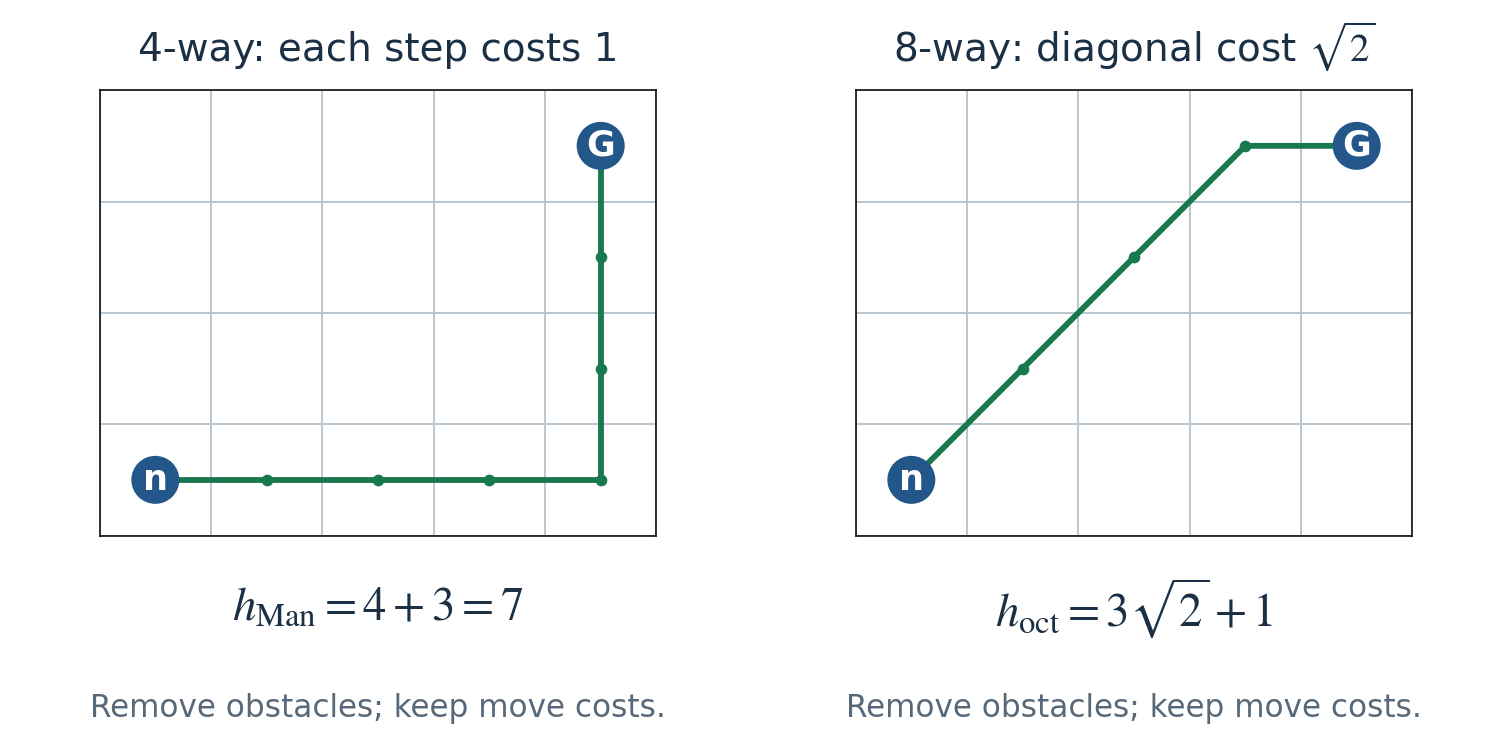

*Figure 6. Heuristic을 정하려면 허용된 이동 방향과 각 이동의 최소 비용을 알아야 한다. 벽을 없애면 최적 비용은 낮아질 수 있다. 대각선 이동을 새로 허용하면 네 방향 이동을 가정한 추정값은 실제 비용을 넘을 수도 있다.*

### 11.3 지형 비용과 단위

아래의 지도 편집 lab에서는 도착 칸의 지형에 따라 비용 배율 $q(v)$를 적용한다.

$$
\begin{gathered}
c(u,v)=\ell(u,v)\,q(v),\\
q(v)\in\{1,5\},\\
\ell(u,v)\in\{1,\sqrt2\}.
\end{gathered}
\tag{20}
$$

탐색을 시작할 때의 비용은 0이고, 이후에는 어느 칸이든 들어갈 때마다 비용을 더한다. 시작 칸으로 돌아올 때도 마찬가지다. $q(v)$는 도착 칸의 배율이므로 같은 두 칸 사이를 오가더라도 방향에 따라 비용이 다를 수 있다. 따라서 양방향으로 이동할 수 있는 지도지만, 비용을 표현한 모델은 directed weighted graph다.

예를 들어 잔디에서 진흙으로 수평 이동하면 비용은 5이고, 진흙에서 잔디로 돌아오면 비용은 1이다. 출발 칸의 비용까지 더하거나, 한 칸에 머무는 동안 계속 비용을 더하지는 않는다. 이런 규칙으로 지형 정보를 edge cost로 바꾸어 relaxation에 사용한다.

기하학적 heuristic에 곱할 배율은 평균 지형 비용이나 현재 칸의 배율이 아니다. 이동 가능한 모든 지형에서 유효한 **global lower bound** $q_{\min}$을 써야 한다. 여기서는 $q_{\min}=1$이다. 비용이 0.2인 지형을 추가하면, 한 칸당 비용 1을 가정한 Manhattan heuristic이 과대평가할 수 있다. $q_{\min}=0.2$를 곱하면 다시 lower bound가 된다. 비용 0인 지형까지 있다면, 그보다 강한 추정값이 유효하다는 근거가 없는 한 $h=0$이 안전하다.

단위도 맞춰야 한다. $g$가 초 단위라면 $h$도 초 단위의 lower bound여야 한다. 예를 들어 직선거리를 실제로 가능한 최대 속도로 나누면 시간의 lower bound를 구할 수 있다. 코드에서 둘 다 floating-point 숫자로 저장하더라도, 미터 단위 거리와 초 단위 시간을 그대로 더해서는 안 된다.

Lab에서는 **corner cutting**을 금지한다. 대각선 이동 경로 양옆에 있는 수평·수직 인접 칸이 모두 비어 있어야 그 방향으로 이동할 수 있다. Heuristic을 계산할 때는 이 제약을 없애도 된다. 더 쉽게 이동할 수 있는 문제의 비용은 lower bound로 쓸 수 있기 때문이다. 반면 실제 successor를 만들 때까지 무시하면, 벽 모서리를 뚫고 지나가는 잘못된 경로가 생긴다.


#### 참고: Python으로 grid edge 생성하기


`rows[y][x]`에서는 row를 먼저 고른 뒤 그 안의 column을 고른다. `(dx, dy)`는 한 번 움직일 방향이고, `free`는 해당 좌표가 지도 안에 있으면서 벽이 아닌지 확인한다. `math.hypot(dx, dy)`로 구한 이동 길이는 수평·수직일 때 1, 대각선일 때 약 1.414다. 여기에 도착 지형의 배율을 곱해 edge cost를 구하고, 앞의 `astar`에 바로 넣을 수 있는 adjacency list로 반환한다.


In [11]:
def grid_graph(rows, diagonal=False):
    # '#' is blocked; '.'/'S'/'G' cost 1 to enter; '5' costs 5.
    height, width = len(rows), len(rows[0])
    if any(len(row) != width for row in rows):
        raise ValueError("rows must have equal length")
    moves = [(1, 0), (0, 1), (-1, 0), (0, -1)]  # E, S, W, N
    if diagonal:
        moves += [(1, 1), (-1, 1), (-1, -1), (1, -1)]
    def free(x, y):
        return 0 <= x < width and 0 <= y < height and rows[y][x] != "#"
    result = {}
    for y in range(height):
        for x in range(width):
            if not free(x, y):
                continue
            edges = []
            for dx, dy in moves:
                nx, ny = x + dx, y + dy
                if not free(nx, ny):
                    continue
                if dx and dy and not (free(x + dx, y) and free(x, y + dy)):
                    continue  # Both sides of a diagonal must be clear.
                terrain = 5 if rows[ny][nx] == "5" else 1
                edges.append(((nx, ny), math.hypot(dx, dy) * terrain))
            result[(x, y)] = edges
    return result

rows = [".......", ".S555G.", "......."]
grid = grid_graph(rows)
start, goal = (1, 1), (5, 1)
manhattan = lambda n: abs(n[0] - goal[0]) + abs(n[1] - goal[1])
path, cost, _ = astar(grid, start, goal, manhattan)
assert cost == 6  # Six grass steps beat entering three mud tiles (cost 16).
assert len(bfs(grid, start, goal)) - 1 == 4


가운데 줄에서 S부터 G까지 직진하면 네 번 움직인다. 진흙 세 칸을 거쳐 G로 들어가므로 비용은 `5 + 5 + 5 + 1 = 16`이다. 위로 한 번 올라가 잔디를 따라 오른쪽으로 네 번 이동한 뒤 G로 내려오면, 여섯 번 움직이지만 비용은 6뿐이다. 그래서 BFS의 assertion은 최소 **이동 횟수**가 4인지, A\*의 assertion은 최소 **비용**이 6인지 확인한다. `lambda n`은 좌표 쌍 `n`의 `n[0]`과 `n[1]`을 이용해 Manhattan 값을 계산하는 함수를 짧게 쓴 표현이다.




**Weighted map 수정 실습.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-astar-weighted)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


같은 지도에서 BFS, Dijkstra, greedy, A\*를 비교해 보자. 먼저 네 방향 이동과 heuristic weight 1을 유지한다. 직행 경로에 진흙을 몇 칸 칠하고, 벽의 위치를 바꿔 우회로도 만들어 보자. **경로 비용 / 최적 비용**과 **Expanded / reopened**를 함께 확인하자. 여기서 최적 비용은 Dijkstra로 계산한 reference다. 후보를 적게 꺼냈더라도 경로 비용이 더 크다면, 그 수치만으로 더 좋은 탐색이라고 할 수 없다.

여덟 방향 이동으로 바꾸면 어떤 heuristic을 고를 수 있는지도 확인해 보자. Lab에서는 해당 이동 비용에 맞는 lower bound만 선택할 수 있다. **클릭 / Enter 동작**에서 편집할 항목을 고른 뒤 칸을 클릭하면 된다. 지도에 focus를 두고 화살표 키로 칸을 고른 다음 Enter나 Space를 눌러도 된다. 지도를 편집할 때마다 기존 frontier를 비우고 새 탐색을 시작한다.

### 11.4 Sliding tile puzzle: board 전체가 state 하나다

빈칸 바로 옆의 숫자 tile을 상하좌우로 옮겨, 1부터 8까지 순서대로 놓고 마지막 칸을 비워 보자. State는 row-major 순서로 읽은 아홉 값 전체다. Blank와 이웃 tile의 자리를 바꾸는 동작 하나가 비용 1인 edge다. 여기서는 칸마다 state가 하나씩 있는 것이 아니라, **board의 배치 전체가 state 하나**라는 점이 중요하다.

Row-major는 맨 윗줄을 왼쪽부터 읽고, 다음 줄도 같은 방식으로 읽는 순서다. 예를 들어 `(1, 2, 3, 4, 5, 6, 7, 0, 8)`에서 0은 blank다. Tile 8을 왼쪽으로 옮기면 목표 배치가 된다. 이동 전후의 배치가 각각 vertex 하나이고, 두 배치를 잇는 edge는 이 swap에 해당한다. 모든 edge cost가 1이므로 BFS로도 최소 이동 횟수를 구할 수 있다. A\*는 시작 배치에서 같은 횟수만큼 떨어진 후보를 차례로 살펴보는 대신, tile의 위치로 추정한 남은 비용까지 고려해 배치를 고른다.


**Sliding tile puzzle.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-search-astar-tiles)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


직접 몇 번 움직여 본 뒤, solver에서 Manhattan heuristic과 0을 번갈아 써 보자. 세 예제의 실제 최소 이동 횟수는 각각 4, 8, 12다. Goal에서 거꾸로 BFS를 실행해 확인했으며, 무작위로 몇 번 섞었는지를 세어 붙인 값이 아니다. 섞는 동안 앞 동작을 취소하거나 같은 배치를 다시 거치면 섞은 횟수보다 적은 이동으로도 풀 수 있기 때문이다.

Manhattan heuristic은 각 숫자 tile이 제자리에서 가로·세로로 얼마나 떨어져 있는지 구해 모두 더한 값이다. x와 y는 각각 column과 row index이고, 위에 붙인 “goal”은 목표 배치에서의 좌표를 가리킨다.

$$
\begin{aligned}
h_{\mathrm{tiles}}(s)
&=\sum_{k=1}^{8}\bigl(\lvert x_k-x_k^{\mathrm{goal}}\rvert\\
&\qquad+\lvert y_k-y_k^{\mathrm{goal}}\rvert\bigr).
\end{aligned}
$$

Blank는 계산에서 뺀다. 한 번에 숫자 tile 하나만 한 칸 움직이므로, 이 합은 한 번의 이동으로 최대 1만 줄어든다. 목표 배치에서는 합이 0이어야 하므로, 현재 합만큼은 적어도 움직여야 한다. 따라서 admissible하다. 한 번의 이동에서 추정값이 줄어드는 양도 비용 1 이하이므로 consistency도 만족한다.


#### 참고: Heuristic을 계산하고 blank를 빼야 하는 이유 확인하기


In [12]:
def tile_manhattan(board):
    total = 0
    for index, tile in enumerate(board):
        if tile == 0:
            continue  # Blank is an action mechanism, not another goal tile.
        y, x = divmod(index, 3)
        goal_y, goal_x = divmod(tile - 1, 3)
        total += abs(x - goal_x) + abs(y - goal_y)
    return total

assert tile_manhattan((1, 2, 3, 4, 5, 6, 7, 8, 0)) == 0
assert tile_manhattan((1, 2, 3, 4, 5, 6, 7, 0, 8)) == 1
assert tile_manhattan(tuple(map(int, "123687540"))) == 10


`divmod(index, 3)`은 3으로 나눈 몫과 나머지를 반환한다. 한 줄에 칸이 세 개이므로, 이 두 값이 각각 row와 column이다. `tile - 1`은 tile 번호를 목표 배치의 0-based index로 바꾼다. 한 번만 움직이면 끝나는 위 배치에서 tile 8의 현재 index는 8, 즉 row 2와 column 2다. 목표 index는 7이므로 row 2와 column 1에 있어야 한다. Tile 8의 거리는 1이고 다른 숫자 tile은 이미 제자리에 있으므로 모두 0이다.

그런데 이 배치에서 tile 8뿐 아니라 blank의 거리까지 더하면 추정값은 2가 된다. 실제로는 한 번의 swap이면 끝나므로 과대평가다. 한편 최소 이동 횟수가 12인 예제에서 숫자 tile의 Manhattan 합은 10이다. Tile들이 서로의 이동을 막아서, 개별 거리의 합에 반영되지 않은 이동이 더 필요하다. 이처럼 lower bound가 실제 비용보다 작아지는 것은 정상이다.



## 12. A\*가 줄이는 계산과 보장하지 않는 것

### 12.1 최적 비용을 기준으로 나뉘는 탐색 영역

최적 경로의 비용이 16이라고 하자. 어떤 후보까지의 기록 비용이 7이고 남은 비용의 lower bound가 4라면 priority는 11이다. 이 후보에서 이어지는 경로가 16보다 저렴할 가능성은 아직 남아 있다. 다만 11은 추정값을 더한 수치이므로, 비용 11인 경로를 끝까지 찾았다고 볼 수는 없다. 반면 기록 비용이 12이고 lower bound가 6인 후보의 priority는 18이다. 비용 16인 goal이 frontier에 있다면 이 goal부터 꺼낸다. A\*는 최적 비용 16을 미리 알 필요가 없다. 앞에서 증명했듯이, 너무 비싼 goal을 꺼내기 전에는 최적 경로로 이어지는 더 작은 priority의 후보가 frontier에 남아 있기 때문이다.

최적 goal을 꺼내기 전, admissible A\*의 frontier에는 최적 prefix 비용을 가진 $f\le C^{\ast}$ 항목이 남아 있다. 따라서 $f>C^{\ast}$인 후보를 먼저 선택하지 않고도 최적해에 도달한다. Consistent heuristic을 사용하면, 도달 가능한 state 중 $g^{\ast}(n)+h(n)<C^{\ast}$인 state들은 expand된다. 등호가 성립하는 경계에서는 tie-break에 따라 goal을 먼저 꺼낼 수도, 다른 state를 먼저 처리할 수도 있다.

이 부등식에는 이론적으로 정의한 최적 prefix 비용을 쓴다. 탐색 도중의 `best_g`에는 아직 그보다 큰 값이 들어 있을 수 있다. 실제 코드는 현재 priority끼리 비교할 뿐이며, 모르는 최적 비용을 pruning 기준으로 사용하지 않는다. 최적 비용을 기준으로 나눈 이 경계는 알고리즘에 필요한 입력이 아니라, priority 순서 덕분에 어떤 탐색을 생략할 수 있는지 설명하기 위한 것이다.

Lower bound가 커지면 이 경계 안쪽에 들어가는 state를 줄일 수 있다. 두 admissible heuristic이 모든 state에서 $h_2(n)\ge h_1(n)$을 만족하면 $h_2$가 $h_1$을 **dominate**한다고 한다. 그렇다고 모든 실행에서 계산량이 반드시 줄어드는 것은 아니다. Priority가 같은 후보가 넓게 모인 plateau, reopening 여부, heuristic 자체의 계산 비용, tie-break도 결과에 영향을 준다.

남은 비용을 정확히 아는 $h=h^{\ast}$를 써도 최적 경로 위의 state만 하나씩 expand하고 끝나리라는 보장은 없다. 비용이 똑같은 최적 경로가 여러 개라면, 그 위에 있는 많은 state가 모두 $f=C^{\ast}$를 가질 수 있기 때문이다. 이처럼 priority가 같을 때 $h$가 작은 후보를 먼저 고르면 goal에 빨리 도달하는 데 도움이 되는 경우가 많다. 최적 비용은 그대로이고, 이를 찾기까지의 탐색량이 달라지는 것이다.

### 12.2 복잡도는 구현과 state space에 따라 다르다

탐색 성능을 볼 때는 무엇을 센 값인지 구분해야 한다. **Expansion 수**는 successor를 살펴본 state의 수다. 한 번 expand하는 동안에도 여러 edge를 검사하고, 여러 heap entry를 넣고, 처음 만난 state의 heuristic을 계산할 수 있다. **실행 시간**에는 이런 작업이 모두 포함된다. **최대 메모리**는 동시에 보관한 정보가 가장 많았을 때의 사용량이다. 따라서 heuristic 계산이 비싸면 expansion 수는 적어도 실제로는 더 오래 걸릴 수 있다.

아래의 복잡도는 edge cost 조회와 heuristic 계산에 상수 시간이 들고, dictionary 연산도 평균적으로 상수 시간에 끝난다고 가정한 상한이다. Heuristic을 cache해도 처음 만난 state의 값은 한 번 계산해야 한다. 여기서 $T$는 시간 복잡도, $M$은 추가 메모리를 뜻한다. 11절에서 좌표 차이 중 큰 값을 나타낸 $M$과 같은 기호지만, 여기서는 메모리라는 다른 뜻으로 쓴다.

유한한 explicit graph에서 Dijkstra나 consistent A\*는 stale entry를 제외하면 각 state를 최대 한 번 expand한다. Lazy binary heap에는 비용을 줄일 때마다 같은 state의 항목을 추가하므로 $O(\lvert E\rvert)$개의 항목이 쌓일 수 있다. 이를 기준으로 잡은 보수적인 상한은

$$
\begin{aligned}
T&=O\bigl(\lvert V\rvert\\
&\qquad+\lvert E\rvert\log(2+\lvert E\rvert)\bigr),\\
M&=O(\lvert V\rvert+\lvert E\rvert).
\end{aligned}
\tag{21}
$$

이다. Cost/parent map과 lazy heap에 필요한 공간을 포함한 값이며, 입력 graph의 저장 공간은 중복해서 더하지 않았다. Edge를 검사할 때 더 저렴한 entry를 추가할 수 있고, heap에 넣거나 꺼내는 데는 heap 크기의 로그에 비례하는 연산이 든다. 그래서 edge 수에 로그 항을 곱한다. Implicit puzzle에서 state 수를 셀 때는 board의 아홉 칸이 아니라 가능한 배치 전체를 세어야 한다.


#### 참고: Heap 구현에 따라 복잡도 식이 달라지는 이유


Decrease-key를 지원하는 indexed heap은 기존 entry의 값을 직접 고치므로 state당 유효한 heap record 하나만 유지하면 된다. 이때 시간 복잡도는 $O((\lvert V\rvert+\lvert E\rvert)\log(2+\lvert V\rvert))$, 추가 공간은 $O(\lvert V\rvert)$로 제한된다. 위 Python 코드는 더 간단한 lazy 방식을 사용한다. 오래된 entry도 남겨 두기 때문에, heap record 수가 서로 다른 frontier state 수보다 많아질 수 있다.



Inconsistent heuristic을 쓰면 reopening할 때 같은 edge를 다시 확인할 수 있으므로, state를 한 번씩만 처리한다고 가정한 상한을 적용할 수 없다. Implicit search tree에서는 서로 다른 state의 수 자체가 해의 depth에 따라 지수적으로 커질 수도 있다. 따라서 A\*를 쓴다고 모든 planning 문제를 다항 시간에 풀 수 있는 것은 아니다.

실제로 A\*는 frontier의 여러 후보와 각 state까지의 최소 기록 비용을 함께 보관하므로 DFS보다 훨씬 많은 메모리를 사용할 수 있다. Heuristic 계산은 비싼데 유망한 후보를 가려내는 데 별 도움이 되지 않는다면 Dijkstra보다 느릴 수도 있다.


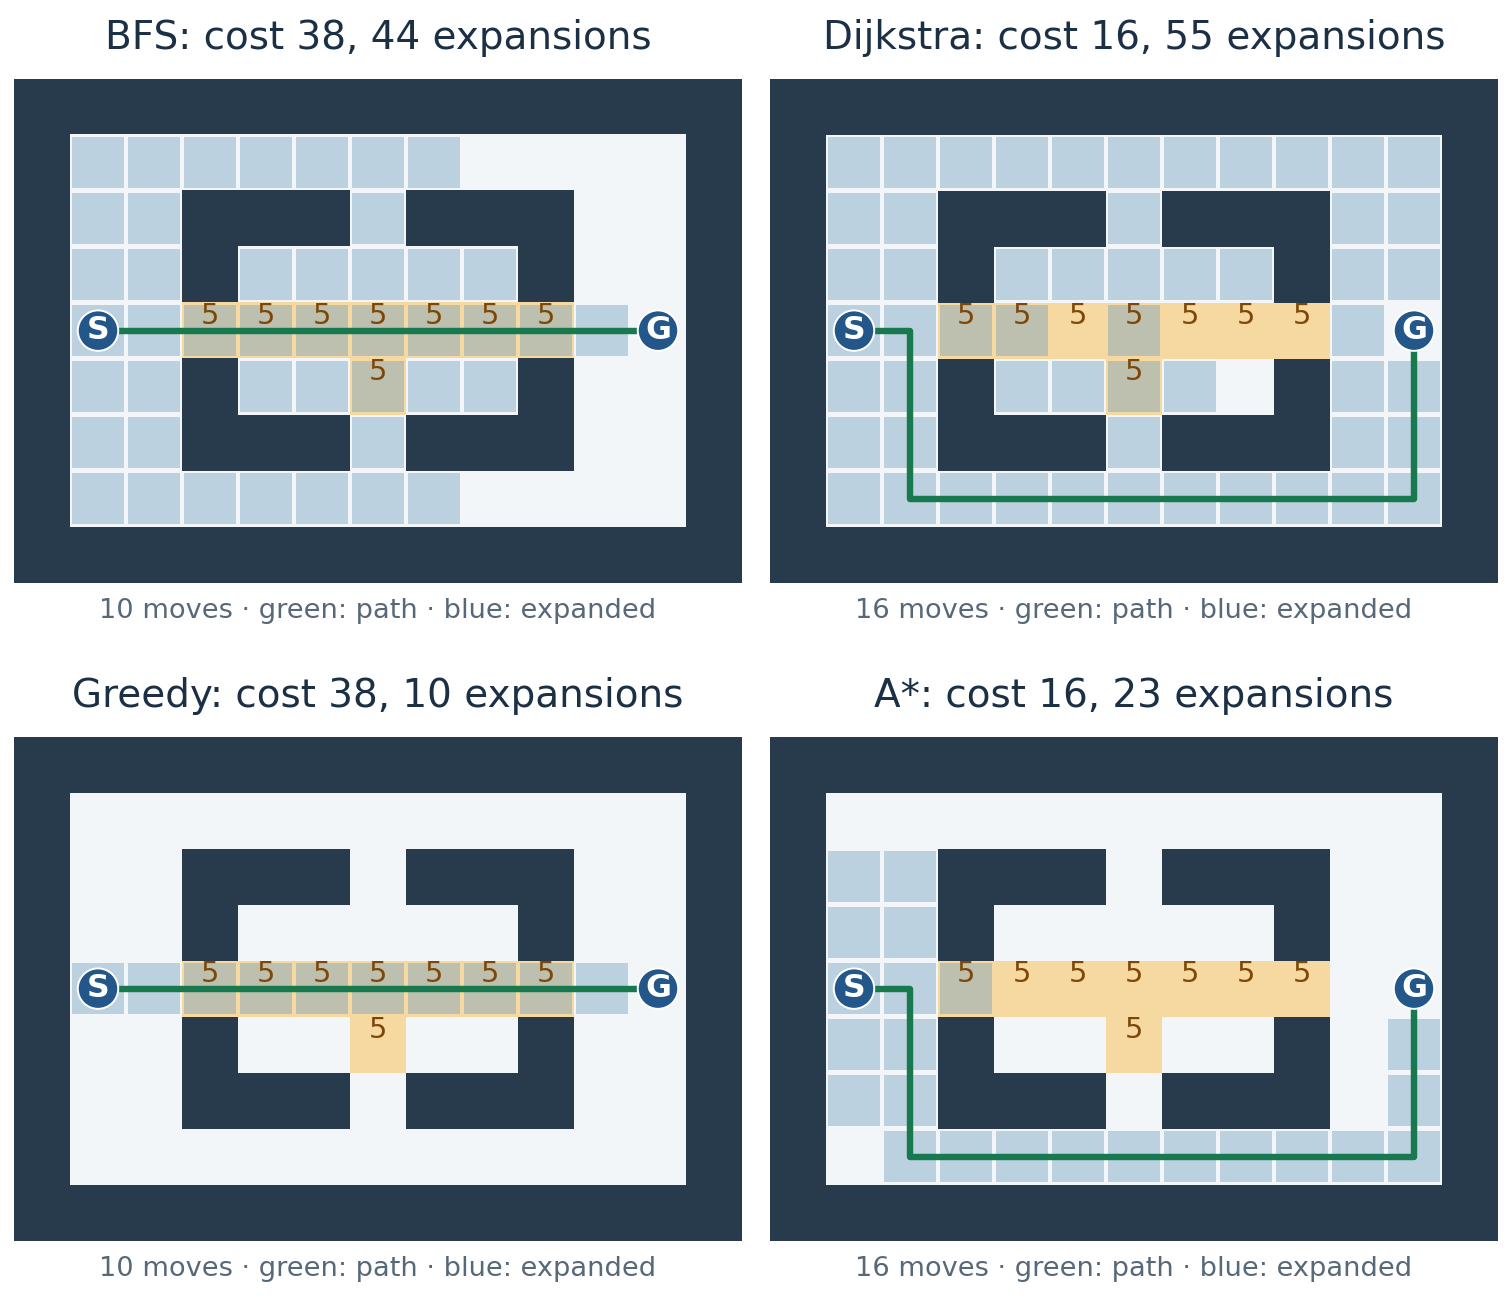

*Figure 7. 지도, 지형 비용, 이웃 순서, tie-break 규칙을 같게 맞춘 결과다. 경로 비용과 탐색량을 따로 비교해야 한다. 표시한 횟수는 이 지도에서 센 값으로, 지도에 상관없이 성립하는 속도 순위는 아니다.*

| Figure 7의 지도에서 실행 | 반환 비용 | 경로의 이동 횟수 | Expansion 수: goal 제외 |
| --- | ---: | ---: | ---: |
| BFS | 38 | 10 | 44 |
| Dijkstra | 16 | 16 | 55 |
| Greedy | 38 | 10 | 10 |
| A\* | 16 | 16 | 23 |

표의 한 행을 가로로 읽어 보자. BFS가 찾은 경로는 열 번만 움직이지만, 진흙 일곱 칸과 일반 칸 세 곳에 들어가므로 비용이 `7 × 5 + 3 = 38`이다. **이동 횟수**는 최소여도 지형 비용은 최소가 아니다. Dijkstra와 A\*는 비용 1인 칸으로 열여섯 번 이동하는 경로를 반환한다. 둘 다 같은 최적 비용을 얻었지만, 이를 찾는 데 Dijkstra는 55회, A\*는 23회 expand했다. Greedy는 열 번만 expand했어도 반환 비용이 38이므로, 탐색량만 보고 더 낫다고 평가해서는 안 된다.

지도 편집 lab의 **Map 예제**에서 **Figure 7 비교 maze**를 고르면 같은 지도로 실행할 수 있다. **비싼 terrain을 지나는 직선 경로**는 장애물이 더 적은 별도의 preset이므로 최적 비용도 다르다. 두 preset 모두 잔디에 들어가는 비용은 1, 진흙에 들어가는 비용은 5다.


#### 참고: 정확한 지도와 Python 재현 코드


In [13]:
comparison_rows = [
    "#############",
    "#...........#",
    "#..###.###..#",
    "#..#.....#..#",
    "#S.5555555.G#",
    "#..#..5..#..#",
    "#..###.###..#",
    "#...........#",
    "#############",
]
comparison_grid = grid_graph(comparison_rows)
cs, ct = (1, 4), (11, 4)  # Zero-based x, y; y increases downward.
ch = lambda n: abs(n[0] - ct[0]) + abs(n[1] - ct[1])
cp, cc, ce = astar(comparison_grid, cs, ct, ch)
assert cc == 16 and len(cp) - 1 == 16 and len(ce) == 23
assert path_cost(comparison_grid, bfs(comparison_grid, cs, ct)) == 38


이웃은 동쪽, 남쪽, 서쪽, 북쪽 순서로 생성한다. Heap 기반 탐색에서는 primary priority가 같으면 Manhattan $h$가 작은 후보를 고르고, 그 값도 같으면 먼저 넣은 후보를 고른다. 앞의 짧은 Dijkstra 코드는 $g$가 같을 때 삽입 순서만 사용하므로 최적 비용이 같아도 expansion 수는 달라질 수 있다. 그림과 같은 Dijkstra 순서로 실행하려면 `astar(comparison_grid, cs, ct, ch, weight=0)`을 사용한다. Weight가 0이어도 tuple의 두 번째 값인 $h$는 tie-break에 쓰인다.



### 12.3 알고리즘별 비교

| 방법 | 다음 후보를 고르는 기준 | 유한한 graph에서 최소 비용 보장 조건 | 주로 선택하는 이유 |
| --- | --- | --- | --- |
| Graph DFS | 가장 최근에 넣은 후보 | 보장하지 않음 | 도달 가능성, graph 구조 탐색, 간단한 구현 |
| Graph BFS | 가장 먼저 넣은 후보 | 동일한 edge cost | Unweighted 문제의 최소 이동 횟수 |
| Exhaustive simple paths | 모든 후보 경로 확인 | 0 이상의 비용이면 보장 | 작은 독립 reference 예제 |
| Dijkstra / UCS | 최소 $g$ | 0 이상의 비용 | 유용한 heuristic이 없거나 여러 goal까지의 거리가 필요할 때 |
| Greedy best-first | 최소 $h$ | 보장하지 않음 | 빠르게 후보 경로를 얻고 품질을 따로 확인할 때 |
| A\* with reopening | 최소 $g+h$ | Admissible $h$ | 하나의 goal과 유용한 남은 비용 lower bound가 있을 때 |

유한한 graph에서 중복을 적절히 처리하면, 위 방법들은 경로가 없을 때도 탐색을 끝내고 그 사실을 반환할 수 있다. Greedy는 최적 비용을 보장하지 않지만, 그렇다고 유한한 graph에서도 반드시 답을 놓치거나 끝없이 실행되는 것은 아니다. Greedy가 incomplete할 수 있다는 설명은 무한한 탐색 공간이나 cycle을 제대로 처리하지 않는 구현 등을 전제로 한다.

## 13. Weighted A\*: heuristic의 비중을 높이는 탐색


“Weighted”는 다음 두 의미를 구분해야 한다.

- **Weighted graph**는 edge에 비용이 있는 graph다. 일반 A\*도 이미 처리할 수 있다.
- **Weighted A\***는 heuristic의 비중을 높이도록 priority를 바꾼 알고리즘이다.

$$
f_w(n)=g(n)+w\,h(n).
\tag{22}
$$

Weight로 바꾸는 것은 도로의 비용이 아니라 **후보를 처리하는 순서**다. Frontier에 다음 두 후보가 있다고 하자. 마지막 두 열에 일반 A\*와 $w=2$일 때의 priority를 계산했다.

| 후보 | $g$ | $h$ | $g+h$ | $g+2h$ |
| --- | ---: | ---: | ---: | ---: |
| X | 2 | 5 | 7 | 12 |
| Y | 6 | 2 | 8 | 10 |


일반 A\*는 X를 먼저 고르지만 weight가 2이면 Y를 먼저 고른다. Y까지 오는 데 비용이 더 들었어도, 남은 비용의 추정값에 더 큰 비중을 두기 때문이다. 반환 경로의 비용은 어느 경우든 **원래 edge cost의 합**으로 계산한다. Priority만 부풀려 탐색 순서를 바꾼 것이며, 경로의 좋고 나쁨을 평가하는 비용 자체는 그대로다.

$w=0$이면 primary priority가 Dijkstra와 같아지고, $w=1$이면 일반 A\*가 된다. $0<w<1$에서는 0 이상의 admissible heuristic을 줄여 쓴 것이므로 여전히 admissible하다. 따라서 reopening을 허용한 A\*는 최적해를 반환한다. 반면 $w>1$이면 $wh$가 실제 비용보다 커질 수 있어, 일반 A\*의 최적성 증명을 그대로 적용할 수 없다.

대신 다음 조건에서는 반환 비용이 얼마나 커질 수 있는지 상한을 구할 수 있다. Graph가 유한하고 edge cost는 0 이상이어야 한다. 원래의 $h$는 0 이상의 admissible heuristic이며 $h(t)=0$을 만족하고, 탐색 중 고정된 $w\ge1$을 사용해야 한다. 더 저렴한 경로를 찾을 때마다 reopening을 허용하고, stale entry가 아닌 goal 항목을 꺼낼 때 종료하면 다음이 성립한다.

$$
C_{\mathrm{returned}}\le w\,C^{\ast}.
\tag{23}
$$

예를 들어 $w=1.5$이면 위 조건에서 반환 비용이 최적 비용의 1.5배를 넘지 않는다. 실제로 50% 더 비싼 경로를 반환한다는 예측이 아니라, 그 이상 비싸지지는 않는다는 보장이다. 실행 시간이 얼마나 줄어들지는 별개의 문제다. 지도에 따라서는 $w$를 높여도 expansion 수가 줄지 않을 수 있고, 반환 비용이 계속 커지는 것도 아니다.

최적 비용이 16이면 반환 비용의 상한은 24다. 여전히 최적 비용 16을 얻을 수도 있고, 16과 24 사이의 비용을 얻을 수도 있다. 배율을 곱한 heuristic이 admissible하지 않아도 이런 보장을 할 수 있는 이유는, **원래 heuristic은 admissible하다**는 조건을 유지했기 때문이다.


#### 참고: Weighted bound 유도하기


일반 A\*를 증명할 때처럼, 최적 경로를 따라 탐색을 끝내기 전에는 frontier에 최적 prefix 비용을 가진 항목 $n$이 남아 있다. $w\ge1$일 때

$$
\begin{aligned}
f_w(n)&=g^{\ast}(n)+w h(n)\\
&\le g^{\ast}(n)+w h^{\ast}(n)\\
&\le w\bigl(g^{\ast}(n)+h^{\ast}(n)\bigr)\\
&=wC^{\ast}.
\end{aligned}
\tag{24}
$$

이다. 두 번째 부등식에는 $g^{\ast}(n)\ge0$을 사용했다. 유효한 goal을 꺼내는 순간 그 priority는 경로 비용과 같으며, frontier에 남아 있는 이 항목의 priority보다 클 수 없다. 따라서 반환 비용에도 같은 상한이 성립한다. 이 증명은 reopening을 허용해 최적 prefix 항목을 frontier에 유지할 수 있다는 조건에 의존한다. 임의의 pruning 규칙을 추가해 이 항목을 버리면 보장이 깨질 수 있다. [Likhachev, Gordon, Thrun의 ARA\* 논문](https://papers.nips.cc/paper_files/paper/2003/hash/ee8fe9093fbbb687bef15a38facc44d2-Abstract.html)은 bounded-suboptimal search와 anytime heuristic search를 자세히 다룬다.




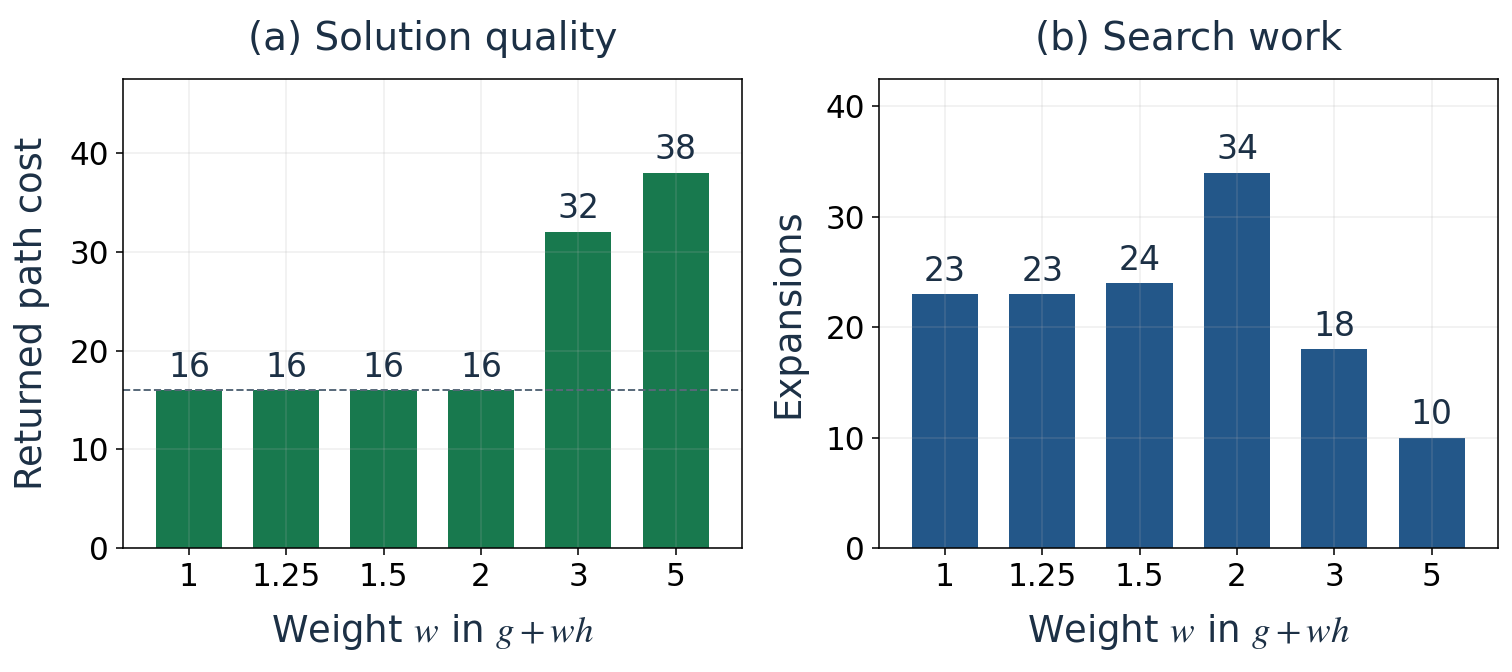

*Figure 8. 같은 지도에서 weight를 바꿀 때마다 탐색을 새로 실행한 결과다. $wC^{\ast}$는 위 조건에서 반환 비용이 넘지 않는 상한이며, 실제 반환 비용을 예측한 곡선이 아니다.*

### 13.1 Priority 규칙을 직접 작성하고 테스트하기


**Priority 식 작성 실습.** 직접 조작하고 탐색을 한 단계씩 진행하는 실습은 [블로그의 해당 실습](https://pilkwangkim.github.io/posts/A-Star-From-Scratch-KR/#lab-astar-priority-lab)에서 실행합니다. 아래 Python cell은 notebook 안에서 직접 수정하고 실행할 수 있습니다.


`g + h`를 입력해 test map에서 실행하고, `g`, `h`, `g + 2*h`로 바꿨을 때와 비교해 보자. 편집기에는 `g`와 `h`로 이루어진 제한된 산술식만 입력할 수 있다. JavaScript나 Python 코드 전체를 실행하는 방식이 아니어서, 잘못 입력한 코드가 다른 작업을 하거나 무한 loop를 만드는 일은 없다. 일반 Python 코드를 수정하며 실험하려면 notebook을 내려받으면 된다.

여러 test map에서 정답을 얻어도 admissibility나 worst-case bound까지 증명한 것은 아니다. 테스트로 확인하는 것은 주어진 입력에서의 결과다. 반면 앞의 부등식은 가정을 만족하는 **모든 입력**에 대한 보장이다. 테스트는 구현 오류를 찾고 구체적인 동작을 이해하는 데 쓰고, 일반적인 보장은 별도의 논리로 확인해야 한다.

Reference cost를 보기 전에 각 결과를 예상해 보자. 어떤 식은 지금까지 든 비용을 무시하는가? 어떤 식은 최적해를 보장하지 못하는가? 보장 조건이 다른 두 식으로 같은 경로를 얻을 수도 있는 이유는 무엇일까?

## 14. 더 강한 heuristic을 만들고 검증하기

### 14.1 Lower bound를 안전하게 결합한다

$h_1$과 $h_2$가 admissible하다면

$$
h(n)=\max\{h_1(n),h_2(n)\}
\tag{25}
$$

도 admissible하다. 두 값 모두 실제 남은 비용 이하이므로, 큰 쪽을 골라도 그 비용을 넘지 않는다. 어느 하나만 쓸 때보다 작아지지도 않으므로 두 heuristic의 장점을 함께 활용할 수 있다. 둘 다 consistent하면 최댓값도 consistent하다. 이를 확인하려면 $u$에서 최댓값이 된 heuristic을 고르면 된다. 그 값은 consistency에 따라 $c(u,v)$에 같은 heuristic의 $v$ 값을 더한 것 이하이다. 이때 선택한 heuristic의 $v$ 값은 그 위치에서 구한 최댓값보다 클 수 없다. 따라서 최댓값으로 만든 새 heuristic에도 consistency 부등식이 성립한다.

반면 둘을 **더하면** admissibility가 깨질 수 있다. 같은 필수 이동의 비용을 두 추정값에서 중복해서 셀 수 있기 때문이다. 각각 admissible한 추정값을 더하려면 cost partitioning이나 disjoint subproblem을 이용해 비용이 겹치지 않는다는 근거를 마련해야 한다. 각 추정값이 개별 테스트를 통과했다는 것만으로는 부족하다.

한 번만 움직이면 끝나는 tile puzzle에 두 방법을 적용해, 각각 올바른 lower bound인 1을 얻었다고 하자. 최댓값은 1이지만 합은 2이므로 실제 최소 비용을 넘는다. 꼭 필요한 그 한 번의 이동을 두 번 센 결과다. 각 방법이 따로는 맞아도 단순히 더해서는 안 되는 이유다.

### 14.2 정확한 거리로 heuristic을 검사한다

유한한 graph에서는 모든 edge를 뒤집은 **reversed graph**를 만든 뒤, goal에서 Dijkstra를 실행해 $h^{\ast}(n)$을 구할 수 있다. Edge $u\to v$를 뒤집어 $v\to u$로 만들 때 비용은 원래의 $c(u,v)$를 그대로 옮긴다. 도착 칸의 지형으로 비용을 정했던 모델이라도, 새 도착 칸을 기준으로 비용을 다시 매겨서는 안 된다. 그러면 원래 graph와 경로 비용이 달라진다.

이 방법으로 모든 state에서 goal까지의 최소 비용을 한 번에 구한다. 처음의 다섯 state 예제에서 S → B → C → G의 비용은 `3 + 1 + 1 = 5`다. 뒤집으면 G → C → B → S가 되고 비용은 `1 + 1 + 3 = 5`로 같다. 원래 graph에서 G로 가는 각 경로마다, reversed graph에는 G에서 출발하는 같은 비용의 경로가 하나씩 있다. 원래 graph에서 edge를 그대로 둔 채 G만 시작점으로 바꾸면, G에는 outgoing edge가 없어 탐색이 진행되지 않는다. 실제 도로의 통행 방향을 바꾸려는 것이 아니라, 원래 경로들의 비용을 거꾸로 계산하기 위한 변환이다.

그다음 offline checker에서 다음 조건을 검사한다.

$$
\begin{gathered}
h(n)\le h^{\ast}(n),\\
h(u)\le c(u,v)+h(v).
\end{gathered}
\tag{26}
$$

모든 state와 edge를 빠짐없이 검사하면 **해당 graph에서** 두 조건이 성립하는지 확인할 수 있다. 같은 heuristic 공식을 다른 크기의 지도나 다른 비용 모델에 적용하려면, 그 조건에서도 유효한지 따로 따져야 한다.

A\*를 딱 한 번 실행할 생각이라면, 정확한 남은 비용을 미리 구하는 일이 원래 문제를 푸는 것만큼 비쌀 수 있다. 반면 같은 graph와 goal에서 시작점만 바꿔 여러 번 탐색한다면, 한 번 구한 값을 재사용할 수 있다. 더 큰 preprocessing 과정에 이 거리를 활용하는 경우에도 유용하다.


#### 참고: Undirected graph에서 landmark로 lower bound 만들기


0 이상의 비용을 가진 undirected graph에서 landmark $L$을 고르면 triangle inequality에 의해

$$
\begin{aligned}
h_L(n)&=\left\lvert d(L,t)-d(L,n)\right\rvert\\
&\le d(n,t).
\end{aligned}
\tag{27}
$$

가 성립한다. 여기서 $d$는 두 지점 사이의 최소 경로 비용을 뜻하며, 기하학적 거리로 한정하지 않는다. 계산에 필요한 거리가 유한한 landmark만 써야 하므로, 예를 들어 goal과 같은 connected component에서 고를 수 있다. 거리를 구할 수 없는 landmark는 건너뛴다. 두 무한대의 차는 정의할 수 없기 때문이다. 사용할 landmark가 하나도 없다면 0을 안전한 lower bound로 쓴다.

여러 landmark에서 구한 값의 최댓값을 쓰면 더 강한 lower bound를 얻는다. Graph가 고정되어 있으면 landmark까지의 거리는 한 번 미리 계산해 둘 수 있다. 단, directed graph에는 위의 절댓값 식을 일반적으로 쓸 수 없다. 필요한 거리가 유한하다면 $d(L,t)-d(L,n)$과 $d(n,L)-d(t,L)$, 그리고 0을 lower bound로 사용할 수 있다. [Goldberg와 Harrelson의 ALT 연구](https://www.microsoft.com/en-us/research/publication/computing-the-shortest-path-a-search-meets-graph-theory/)는 이처럼 A\*, landmark, triangle inequality를 함께 이용해 경로를 찾는 방법이다.



## 15. Priority 규칙으로 해결할 수 없는 모델링 오류

**State에 필요한 정보가 빠진 경우.** 같은 칸에 도착했더라도 남은 연료, 가진 열쇠, 바라보는 방향, 도착 시각에 따라 다음에 할 수 있는 행동이 달라질 수 있다. 이때는 위치만으로 state를 정해서는 안 된다. 같은 좌표까지 오는 데 쓴 $g$가 작아도 연료가 거의 없다면, 비용은 더 들었지만 연료가 많이 남은 경로보다 나쁘게 이어질 수 있다. 이후 행동에 영향을 주는 변수를 state에 넣거나 적절한 multi-label 방법을 사용해야 한다.

**원하는 것과 다른 목표를 최적화하는 경우.** 가장 짧은 경로가 가장 빠르거나, 안전하거나, 에너지가 적게 드는 경로라는 보장은 없다. 회전이 적은 경로를 원할 수도 있다. 여러 penalty를 비용에 더하려면 단위를 맞추고, 서로 얼마나 중요하게 볼지 tradeoff 계수를 정해야 한다. A\*가 최소화하는 것은 입력한 scalar 비용의 합이다. 원하는 선호는 비용식에 직접 반영해야 한다.

**탐색 중에 비용을 바꾸는 경우.** 앞의 증명은 탐색하는 동안 graph가 바뀌지 않는다는 가정에 따른 것이다. 문이 닫히거나 지형 비용이 달라졌는데 예전 비용과 parent를 계속 사용하면 잘못된 결과가 나올 수 있다. 작은 문제라면 탐색을 처음부터 다시 실행하면 된다. 지도가 자주 바뀐다면 이전 탐색 정보를 갱신하며 재사용하는 incremental planning 방법이 적합하다.

**충돌 모델을 지나치게 단순화한 경우.** 로봇은 너비와 회전 반경이 있으므로 칸 중심을 잇는 선이 장애물을 지나지 않더라도 실제로 이동할 수 있는 것은 아니다. 필요한 여유 거리만큼 장애물 영역을 넓히거나, state 사이를 이동하는 동안 충돌하는지 검사하거나, 더 자세한 configuration-space 모델을 써야 한다. Graph에서 유효한 경로를 찾은 뒤에도 실제 움직임을 위한 continuous trajectory planning이 필요할 수 있다.

**Shortcut을 무시해서 생긴 과대평가.** 벽을 없애면 이동이 더 쉬워지므로 lower bound를 만드는 데 쓸 수 있다. 하지만 사용할 수 있는 teleport를 heuristic 계산에서 빼는 것은 반대다. 실제로는 teleport로 저렴하게 갈 수 있는데도 걸어서 가는 비용을 추정하므로, 벽을 모두 없앤 보행 거리조차 실제 비용보다 커질 수 있다.

**비교 조건이 다른 benchmark.** 시작점과 goal뿐 아니라 장애물, 비용 모델, 이동 규칙, tie-break, 종료 조건까지 같게 맞춰야 한다. Expansion 수, 생성된 항목 수, 최대 frontier 크기, 경로 비용, 실행 시간은 따로 기록한다. Browser animation에는 한 step씩 눈으로 볼 수 있도록 일부러 기다리는 시간도 들어간다. 따라서 animation 재생 시간을 알고리즘의 실행 시간으로 비교해서는 안 된다.

## 16. A\*의 활용과 다른 방법이 더 적합한 경우

### 게임과 navigation mesh

Grid의 칸, polygon 영역, waypoint 교차점 등을 state로 삼아 경로를 찾을 수 있다. 목적지가 정해져 있고 기하학적 거리로 남은 비용을 저렴하게 추정할 수 있다면 A\*가 유용하다. 찾은 경로를 실제로 따라가려면 별도의 이동 제어와 충돌 처리가 필요하다. 많은 유닛이 같은 고정 goal로 간다면, 유닛마다 A\*를 실행하기보다 reverse shortest-path tree나 flow field를 함께 쓰는 편이 효율적일 수 있다.

Waypoint를 쓰는 경우라면 waypoint 하나가 state, 실제로 통과할 수 있는 연결이 edge, 그 구간의 이동 시간이 cost가 된다. 목적지 waypoint가 goal이다. **Navigation mesh**는 이동 가능한 공간을 정사각형 tile 대신 서로 연결된 polygon으로 표현한다. **Flow field**는 목적지까지 남은 비용을 미리 계산해 두고, 각 위치에서 다음에 어느 방향으로 가야 할지 여러 유닛에게 공통으로 알려 주는 방식이다.


#### 참고: Grid에 특화된 확장: Jump Point Search


**Jump Point Search**는 uniform-cost grid의 특정 이동 조건에서, 대칭적인 경로를 중복해서 탐색하지 않도록 후보를 줄인다. Terrain weight가 제각각인 지도에 같은 pruning 규칙을 그대로 적용할 수는 없다. Harabor와 Grastien의 [원 논문](https://ojs.aaai.org/index.php/AAAI/article/view/7994)에 적용 가능한 grid 조건과 pruning 규칙이 나와 있다.



### 로봇과 변하는 지도

옆으로 움직일 수 없는 로봇은 어느 방향을 보고 있는지에 따라 다음 동작이 달라진다. 따라서 위치만 적기보다 `(x, y, heading)`을 state로 쓰는 편이 낫다. 짧은 전진이나 가능한 회전 하나가 edge이고, 소요 시간이나 에너지가 edge cost다. **Motion primitive**는 이런 짧은 동작을 미리 정해 둔 것이다. 충돌 검사는 해당 edge로 이동해도 되는지 판단하고, 탐색 priority는 허용된 edge 중 어느 쪽을 먼저 살펴볼지 정한다.

각 primitive가 끝난 뒤의 위치와 방향들을 state로 모으면 로봇의 discrete **configuration space**가 된다. 이 모델에서 표현할 수 있는 자세들의 집합이다. A\*는 이 state들을 탐색하고, heuristic은 장애물을 없애거나 차원을 낮춘 더 쉬운 문제에서 구할 수 있다. 지도가 바뀌는 경우 **D\* Lite**는 관련 edge cost가 바뀔 때마다 처음부터 다시 탐색하는 대신 이전 정보를 재사용한다. 자세한 방법은 [Koenig와 Likhachev](https://www.cs.cmu.edu/afs/cs/Web/People/motionplanning/papers/sbp_papers/integrated3/koenig_dstarlite_aaai02b.pdf)의 논문에 설명되어 있다.


#### 참고: Any-angle 경로를 위한 확장: Theta*


**Theta\***는 두 state 사이를 장애물 없이 직선으로 이을 수 있으면 parent를 직접 연결한다. 그래서 grid에서도 정해진 이동 방향에만 묶이지 않는 any-angle 경로를 만들 수 있다. 일반 grid A\*와는 graph와 relaxation 규칙이 다르며, continuous 공간에서의 실제 최단 경로를 항상 찾는 것은 아니다. [Daniel 등의 논문](https://arxiv.org/abs/1401.3843)에 알고리즘과 한계가 설명되어 있다.



### 도로 경로 탐색과 대규모 고정 graph

직선거리를 실제로 가능한 최대 속도로 나누면 이동 시간의 lower bound로 쓸 수 있다. 같은 도로망에서 경로를 반복해서 찾는다면 preprocessing에 더 많은 계산을 투자할 수 있다. ALT 같은 landmark 방법으로 A\*의 heuristic을 강화하거나, hierarchical 방법과 contraction-based routing으로 도로망의 구조를 활용할 수 있다. 실제 지도 서비스의 전체 경로 탐색을 A\* 하나만으로 설명할 수 있는 것은 아니다.

### 퍼즐과 symbolic planning

Sliding-tile puzzle에서는 tile 배치 전체가 state 하나이고, blank와 이웃 tile의 자리를 바꾸는 것이 한 번의 이동이다. 이동 비용이 1일 때, blank를 제외한 각 tile의 Manhattan distance를 모두 더하면 admissible heuristic이 된다. 한 번에 tile 하나만 움직여 그 거리를 최대 1만 줄일 수 있기 때문이다. 더 강한 **pattern database**는 relaxed subproblem을 정확히 푼 거리를 저장해 사용한다. 여러 pattern의 값을 더할 때는 같은 비용을 중복해서 세지 않는다는 근거가 필요하다.

Planning도 같은 구조로 표현한다. 현재 어떤 사실들이 성립하는지 state에 기록하고, 가능한 action을 edge로 연결하며, 최소화하려는 값을 cost로 정한다. 실제로는 heap을 구현하는 것보다 필요한 정보를 빠뜨리지 않으면서 state를 작게 만들고, 강한 lower bound를 찾는 일이 더 어려운 경우가 많다.

예를 들어 `(room, have_key, door_open)`으로 현재 방, 열쇠 유무, 문이 열렸는지를 기록할 수 있다. 열쇠 줍기, 문 열기, 옆방으로 이동하기가 action이다. 각 action을 실행할 수 있는 조건과 실행 후 바뀌는 값을 정하면 successor를 만들 수 있다. 모든 action의 비용이 1이고 특정 방에 도착하는 것이 goal이라면, 탐색으로 최소 action 수를 구한다. 물통 퍼즐과 successor 규칙만 다를 뿐, frontier에서 후보를 고르는 원리는 같다.

### 메모리 제한과 anytime 알고리즘

일반 A\*는 여러 후보를 나중에 비교할 수 있도록 보관한다. 메모리가 부족하다면 일부 정보를 버리고 필요할 때 다시 계산하는 방식이 필요하다. 한편 **anytime** 방법은 시간 제약에 대응한다. 우선 실행 가능한 답을 내놓고, 시간이 더 있으면 계산을 이어 가며 답을 개선한다.


#### 참고: 메모리와 시간 제약에 대응하는 IDA*·ARA*


**IDA\***는 $f$ threshold를 정해 depth-first search를 반복한다. 일반적인 tree search에서는 같은 계산을 일부 반복하는 대신 메모리 사용량을 크게 줄일 수 있다. **ARA\***는 heuristic을 크게 부풀려 빠르게 초기 해를 구한 뒤, 이전 탐색 결과를 재사용하며 해를 개선한다. IDA\*는 메모리 부족에, ARA\*는 제한된 시간 안에서 점차 좋은 답을 내야 하는 상황에 대응한다. 거대한 state space에서 일반 A\*를 그대로 실행할 때 생기는 메모리 문제는 여전히 별도로 고려해야 한다.



### A\*보다 다른 방법이 나은 경우

모든 edge cost가 같고 graph가 크지 않으면 BFS로 충분하다. 유용한 heuristic이 없거나, 한 시작점에서 여러 목적지까지의 거리가 필요하면 Dijkstra가 적합하다. Directed acyclic graph는 topological order로 처리하는 최단 경로 알고리즘이 더 단순할 수 있고 음수 edge도 다룬다. 일반 graph에 음수 edge가 있다면 negative cycle까지 처리하는 Bellman–Ford 같은 방법을 써야 한다. 여러 agent가 서로 충돌하지 않아야 하는 문제에서는 각자 single-agent A\*로 경로를 찾는 것만으로 부족하다. Agent들의 이동을 함께 조정해야 한다.

## 17. 구현이 맞는지 확인하는 연습문제

### 17.1 그림을 보고 풀어 보는 다섯 문제

각 문제의 graph나 이동 규칙을 보고 답을 골라 보자. Goal의 종료 조건, reopening, 이동 비용, 경계 조건, 거리로 만든 lower bound를 차례로 확인할 수 있다. 답을 고르면 해설이 나타난다. 문제를 바꿔도 이전 답은 남고, 막히면 힌트를 열어 볼 수 있다.






#### 1. Goal을 발견하면 바로 끝내도 될까?

화살표 방향으로만 이동할 수 있고 모든 state에서 h=0이다. S를 확장하면 먼저 비용 10인 G를 발견하고, 이어서 비용 1인 A를 발견한다. Goal을 발견하자마자 종료하면 얼마를 반환할까? 유효한 최소 priority entry로 goal을 꺼낼 때 종료하면 얼마일까?

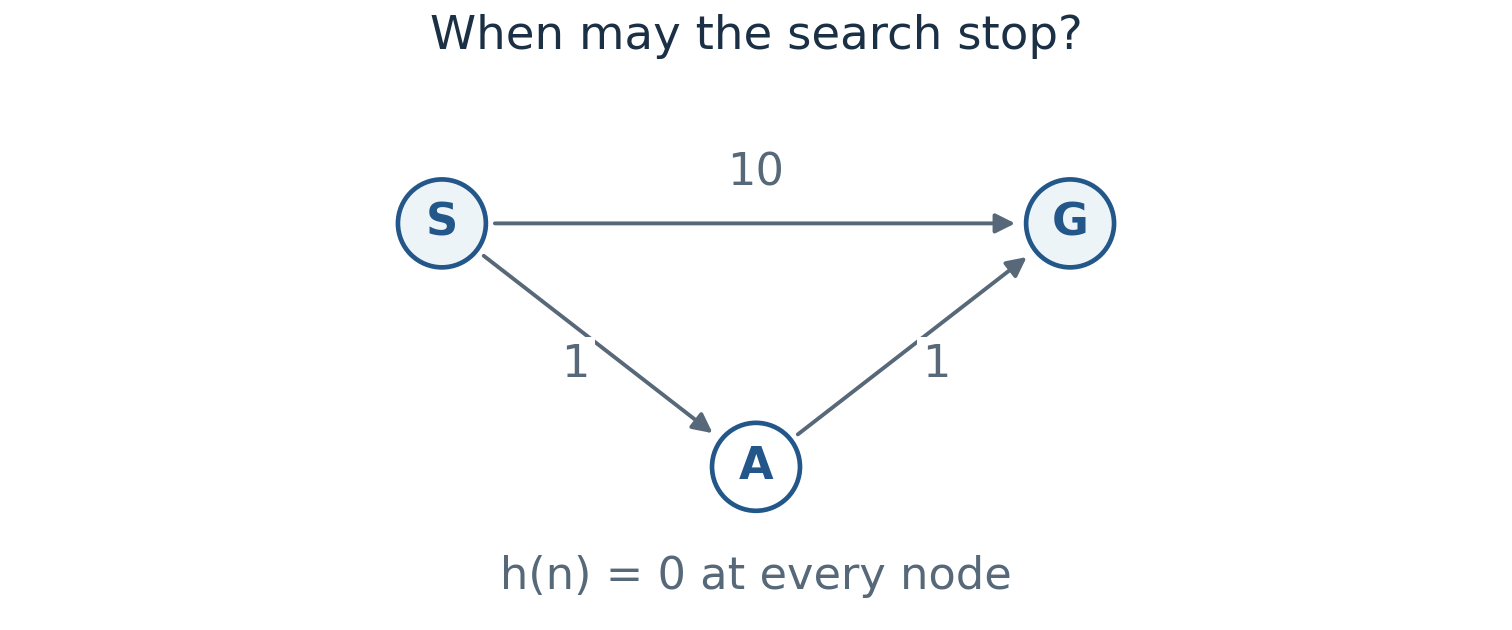

*화살표의 숫자는 edge 비용이다. S의 이웃은 G, A 순서로 확인한다.*


1. 발견 즉시 종료: 10 / 유효 pop에서 종료: 2
2. 발견 즉시 종료: 2 / 유효 pop에서 종료: 2
3. 발견 즉시 종료: 10 / 유효 pop에서 종료: 10

**힌트.** S를 확장한 뒤, A와 처음 발견한 G 중 어느 쪽의 priority가 작은지 비교해 보자.

**정답·해설: 1.** 처음 발견한 G는 비용 10인 후보일 뿐이다. h=0이므로 A의 priority는 1이고, 비용 10인 G보다 먼저 꺼낸다. A를 확장하면 g(G)가 2로 줄어들고 새 entry가 들어간다. 이후 유효한 G entry를 꺼내 비용 2를 반환한다. 비용 10인 기존 entry는 더 이상 유효하지 않다. Goal을 찾았다는 사실만으로 그 경로가 최적이라고 결론 낼 수는 없다.

유효한 pop 순서는 S, A, G다. 이 탐색은 비용 10인 오래된 G entry를 꺼내기 전에 끝난다.

#### 2. 이미 확장한 state를 왜 다시 열까?

f=g+h를 쓰고, 동점이면 h가 작은 쪽, 그다음 먼저 넣은 쪽을 고른다. 그림의 h는 admissible하지만 inconsistent하다. 한 번 확장한 state를 영구히 닫으면 얼마를 반환할까? 더 작은 g가 나올 때마다 reopening하면 얼마일까?

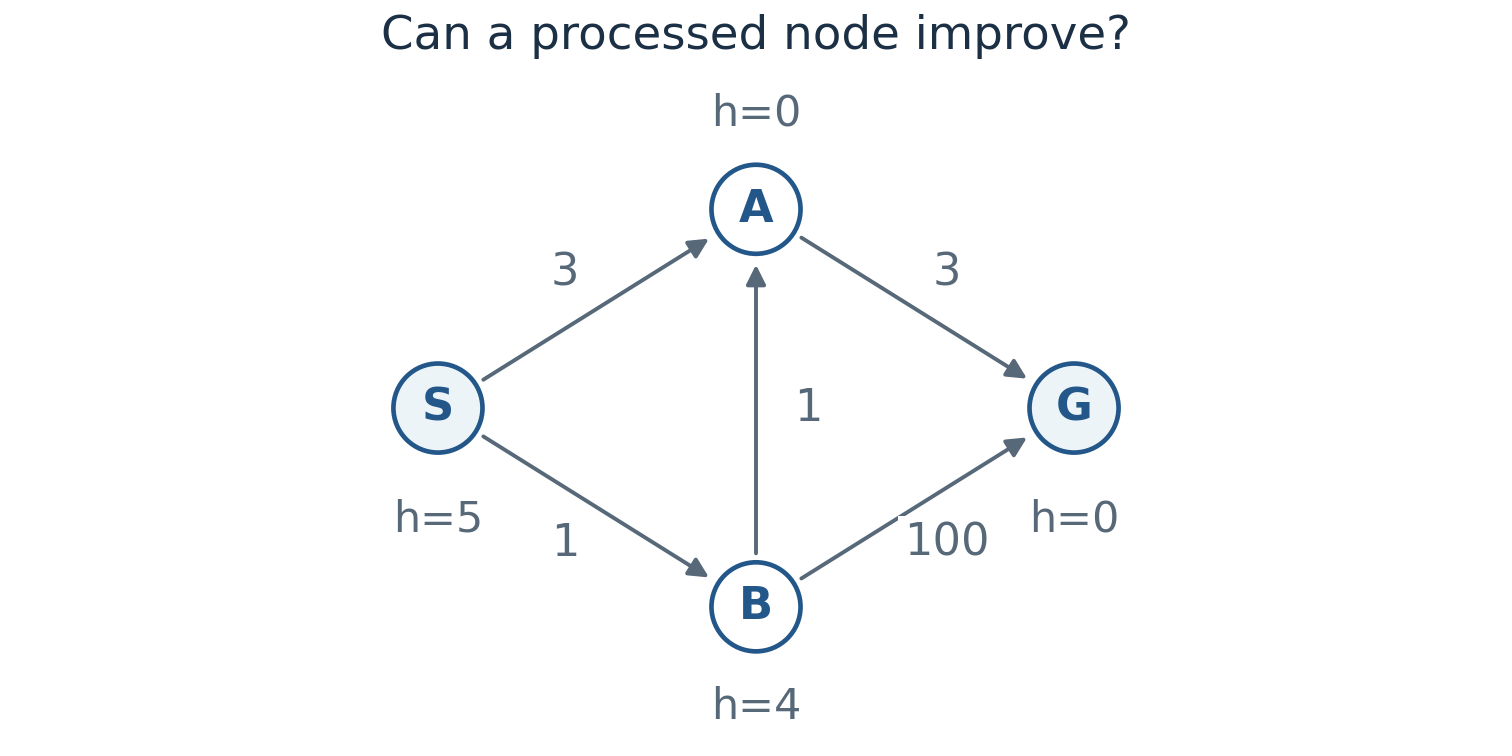

*각 node 아래에 h를 적었다. 모든 edge에는 방향이 있다. A를 한 번 확장한 뒤 B→A를 확인하면 어떤 일이 생길지 생각해 보자.*


1. 영구 closed: 5 / reopening: 5
2. 영구 closed: 6 / reopening: 5
3. 영구 closed: 6 / reopening: 6

**힌트.** S를 확장하면 A는 g=3, f=3이고 B는 g=1, f=5다. A를 먼저 확장한 뒤 B를 꺼내면, A로 가는 비용이 어떻게 바뀔까?

**정답·해설: 2.** A를 g=3으로 확장하면 G의 후보 비용은 6이다. 이어서 B를 확장하면 A까지 비용 2인 더 싼 경로를 찾는다. 영구 closed로 막아 두면 이 개선을 G까지 전달하지 못해 비용 6을 반환한다. Reopening하면 A가 f=2로 다시 들어가고, A를 재확장하면서 G의 비용을 5로 줄인다. 유효한 pop 순서는 S, A, B, A, G다. 실제 남은 최소 비용은 h*(S,A,B,G)=(5,3,4,0)이다. 주어진 h는 어느 state에서도 이 값을 넘지 않으므로 admissible하다. 하지만 B→A에서는 h(B)=4가 1+h(A)=1보다 크므로 consistency가 깨진다. Admissibility만으로는 이미 확장한 state의 g가 나중에 줄어드는 일을 막을 수 없다.

최종 경로만 보지 말고 g(A)와 g(G)가 바뀌는 순서도 적어 보자. Reopening은 graph를 바꾸는 작업이 아니라, 더 싼 prefix 비용을 이웃에 다시 전달하는 과정이다.

#### 3. 이동 규칙이 바뀌면 거리도 달라진다

장애물이 없는 grid에서 (0,0)에서 (3,2)로 이동한다. (a)는 4방향 이동, 한 번에 비용 1이다. (b)는 8방향 이동으로 직선은 1, 대각선은 √2다. (c)는 8방향 이동이지만 대각선을 포함해 모두 비용 1이다. 세 경우의 최단 비용을 순서대로 고르면?

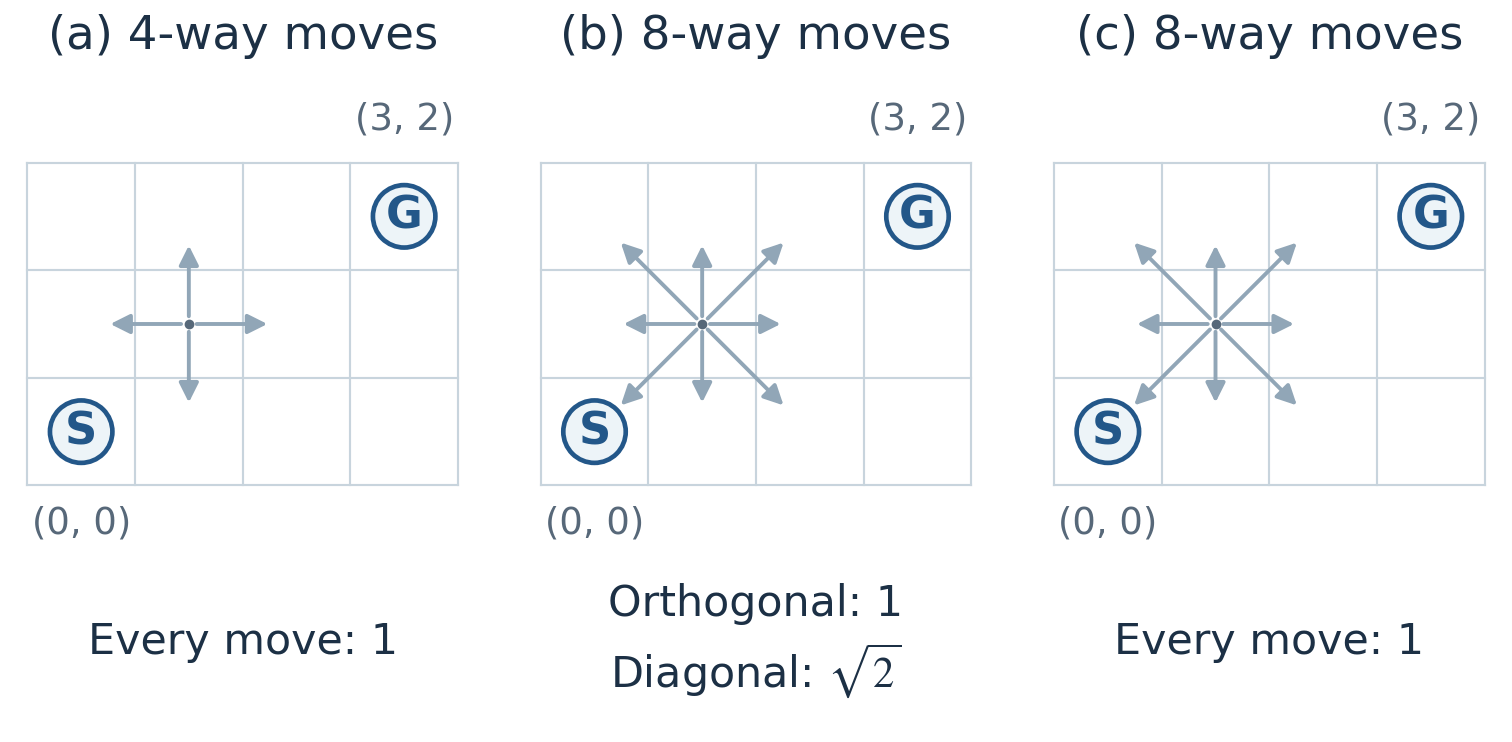

*회색 화살표는 한 칸에서 가능한 이동 방향을 나타내며, S에서 출발하는 경로를 그린 것은 아니다. 출발점과 도착점은 같고, 이동 방향과 비용만 달라진다.*


1. 5, 5, 5
2. 5, √13, 3
3. 5, 1 + 2√2, 3

**힌트.** 대각선 두 번이면 세로 차이 2를 모두 줄일 수 있다. 그러고 나면 가로로 얼마나 더 이동해야 할까?

**정답·해설: 3.** 4방향에서는 가로 세 번, 세로 두 번이 필요하므로 Manhattan distance는 5다. 8방향이면 대각선 두 번과 가로 한 번으로 갈 수 있다. 대각선 비용이 √2일 때는 octile distance인 1+2√2, 모든 이동 비용이 1이면 Chebyshev distance인 3이 정확한 값이다. Euclidean distance √13은 (b)의 lower bound지만, 이 grid에서 실제 이동으로 만들 수 있는 경로 비용은 아니다. 거리식만 외우기보다 어떤 이동 규칙과 비용을 전제로 하는지 함께 확인해야 한다.

각 경우에 필요한 이동을 직접 그리고 비용을 더해 보자. 이 예제의 두 8방향 모델에서는 Manhattan distance가 실제 비용을 과대추정한다.

#### 4. 예외적인 입력도 처리할 수 있을까?

유한 graph이고 비용은 모두 0 이상이다. h=0, 유효 pop에서 goal 확인, reopening을 사용한다. 그림의 세 입력에 대한 반환값과, 비용 0인 cycle에서 같은 비용의 entry를 끝없이 넣지 않게 하는 갱신 조건을 고르면?

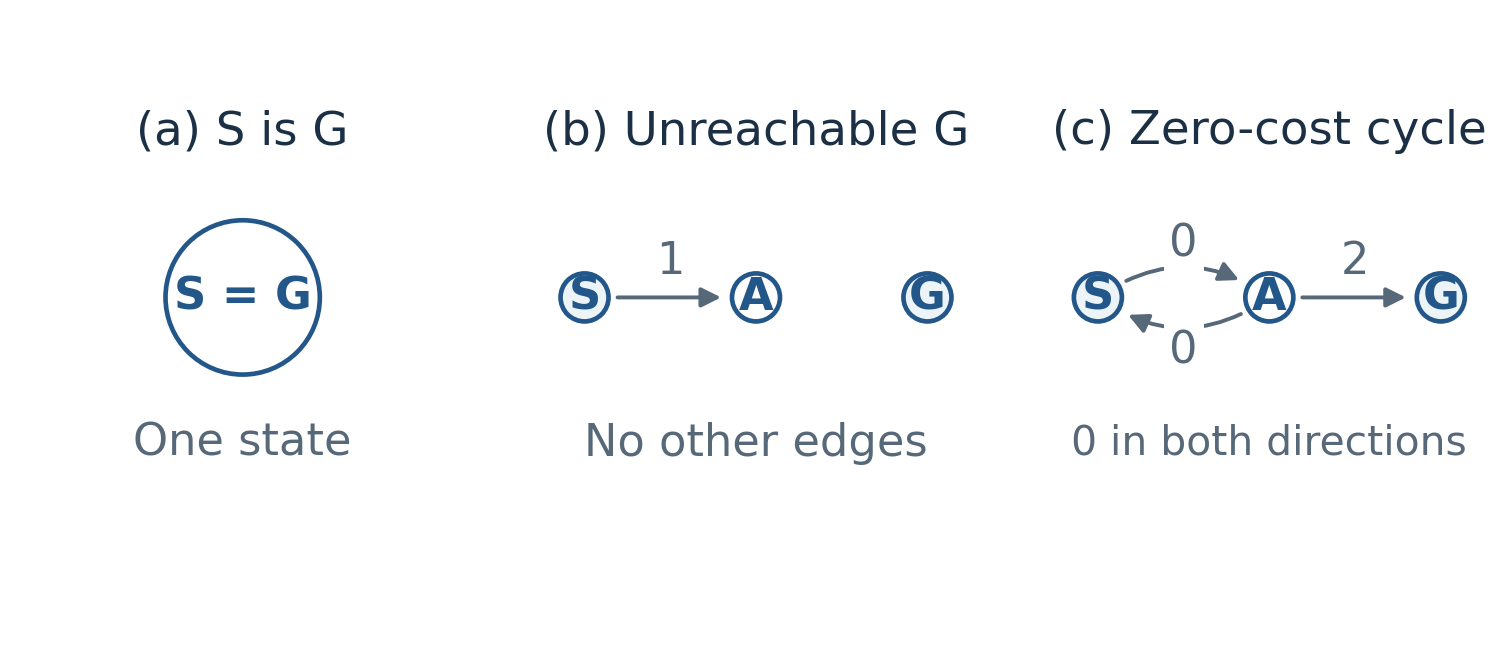

*Start=goal이면 이동하지 않는다. 연결되지 않은 goal은 frontier가 빌 때까지 찾을 수 없다. 마지막 graph의 cycle 비용은 0이며 음수 edge는 없다.*


1. 0, 경로 없음, 2 / candidate < old_g일 때만 갱신
2. 0, 경로 없음, 2 / candidate ≤ old_g이면 갱신
3. 1, 비용 0, 2 / candidate < old_g일 때만 갱신

**힌트.** S→A→S로 돌아왔을 때, S까지의 best cost가 정말 줄어들었는지 확인해 보자.

**정답·해설: 1.** Start에서 움직이지 않는 경로의 비용은 0이다. Goal에 도달할 수 없는 것은 무료로 도착하는 것과 다르므로 ‘경로 없음’을 반환해야 한다. 마지막 graph에서는 g(S)=g(A)=0이고 G까지의 비용은 2다. Strict improvement를 쓰면 S로 돌아오는 비용 0은 기존 값과 같으므로 무시한다. 반대로 <를 ≤로 바꾸면 이 reopening 구현에서는 S와 A를 priority 0으로 계속 다시 넣을 수 있다. 그러면 비용 2인 G를 꺼내지 못한다. 이 구현에서는 strict 비교가 zero-cost cycle의 반복을 막는다.

비용만 반환하는 API에서는 Python의 None, 브라우저 결과의 null로 ‘경로 없음’을 나타낸다. 비용 0과 구별해야 한다.

#### 5. 직선거리를 쓰면 언제 문제가 생길까?

Goal까지 직선거리는 60 km이고 실제 도로 길이는 90 km다. 모든 일반 도로의 최고 속도가 120 km/h라고 하자. h=60/120=0.5시간을 남은 시간의 lower bound로 쓸 수 있을까? 여기에 goal로 바로 가는 시간 0짜리 teleport를 추가하면 어떻게 될까?

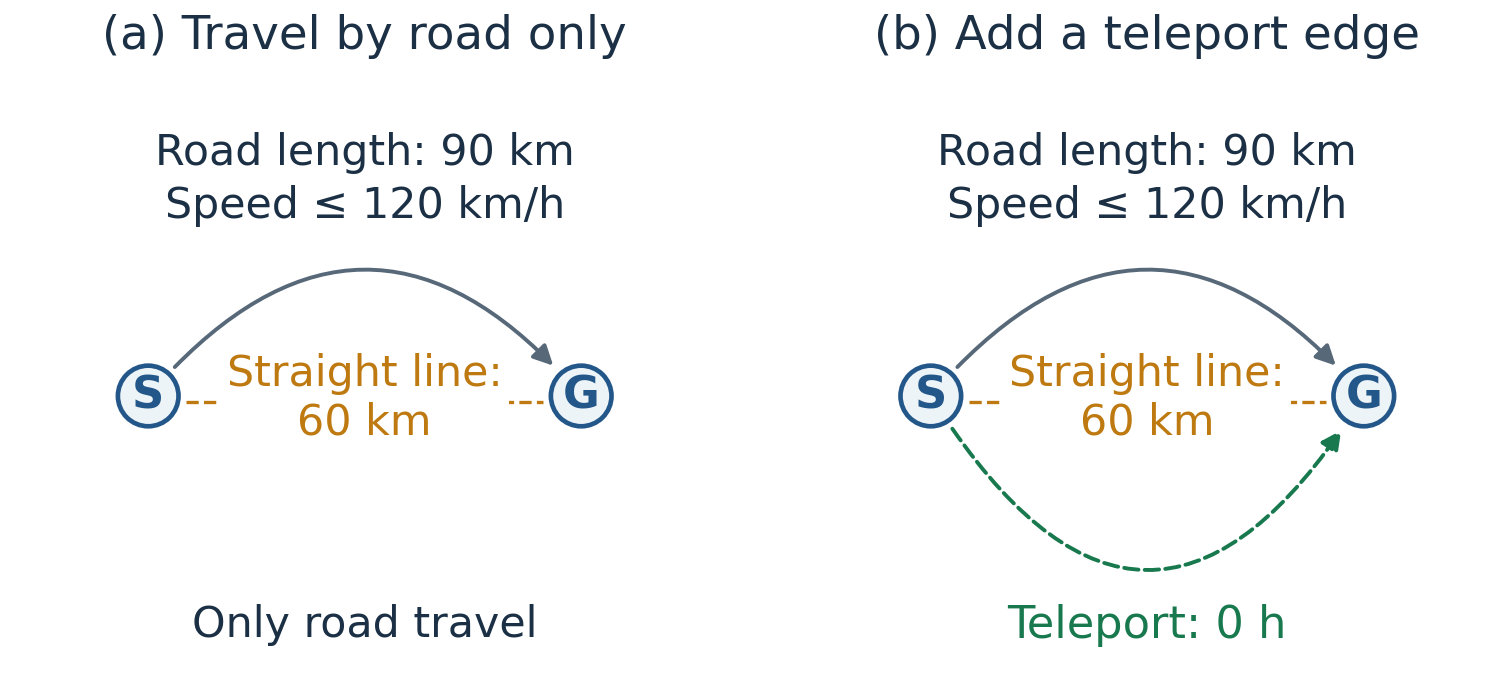

*도로 길이와 직선거리의 단위는 km다. 최적화할 비용과 heuristic의 단위는 시간이다.*


1. 도로만 있을 때도, teleport가 있을 때도 유효하다
2. 도로만 있을 때는 유효하지만, 시간 0인 teleport를 넣으면 유효하지 않다
3. 실제 도로가 60 km보다 길기 때문에 도로만 있어도 유효하지 않다

**힌트.** Lower bound는 허용된 경로 중 가장 빠른 경로의 시간보다 커서는 안 된다. Teleport도 허용하는 순간, 그 이동까지 포함해 확인해야 한다.

**정답·해설: 2.** 속도 제한을 우회하는 이동이 없다면 어느 경로도 직선거리 60 km보다 짧을 수 없고, 걸리는 시간도 60/120=0.5시간 이상이다. 그림의 90 km 도로는 적어도 0.75시간이 걸리므로 이 lower bound는 유효하다. 하지만 시간 0인 teleport를 허용하면 실제 남은 시간이 0이 된다. 기존의 양수 h는 이를 과대추정한다. 단위를 맞췄다는 이유만으로 heuristic이 안전해지는 것은 아니다. 허용한 모든 이동에서 lower bound가 성립해야 한다. Teleport가 있는 모델에서도 h=0은 사용할 수 있다.

새로운 이동을 추가했다면 기존 거리식을 그대로 쓰지 말고, 바뀐 이동 규칙에서 lower bound를 다시 따져 보자.


### 17.2 Coding test: A*의 핵심 채우기

**문제.** `astar_cost(graph, start, goal, h)`를 완성하자. 입력은 edge cost가 모두 0 이상인 유한 directed graph와, 0 이상의 admissible heuristic이다. `h[goal] == 0`이며, heuristic이 consistent하다는 보장은 없다. 최소 경로 비용을 반환하고, 경로가 없으면 `None`, start와 goal이 같으면 `0`을 반환해야 한다. 이미 확장한 state라도 더 싼 경로를 찾으면 비용을 갱신할 수 있어야 한다.

Heap, 비용 snapshot, stale entry 검사, 새 entry를 넣는 코드는 제공한다. 직접 채울 부분은 세 가지다. `g`와 `h`로 priority를 계산하는 식, `candidate`와 `old_g`를 비교하는 갱신 조건, 그리고 goal을 확인할 위치다. Priority가 같으면 `h`가 작은 쪽을, 그 값도 같으면 먼저 넣은 쪽을 고른다. Expansion 수에는 goal을 포함하지 않는다.

그림의 예제에서 A의 heuristic은 0이다. 가까워 보인다는 이유로 A만 따라가면, 마지막 A→G 구간에서 큰 비용을 내게 된다.


In [14]:
exercise_graph = {
    "S": [("A", 1), ("B", 4)],
    "A": [("G", 20)],
    "B": [("G", 1)],
    "G": [],
}
exercise_h = {"S": 5, "A": 0, "B": 1, "G": 0}

# Expected output for astar_cost: 5, from S -> B -> G.
# Check the same input with the complete search from section 10.
assert astar(exercise_graph, "S", "G", exercise_h.__getitem__)[1] == 5


채점에서는 반환 비용과 함께, 두 테스트에 명시한 expansion 상한도 확인한다. 그중 장애물이 없는 15×15 grid의 상한은 40회다. 위 tie-break를 쓰면 일반 A*는 28개 state를, Dijkstra는 224개 state를 확장한다. Dijkstra도 최적 비용은 맞힌다. 이 테스트는 정답 여부와 별개로, 주어진 heuristic을 활용해 탐색량을 줄였는지 확인하는 것이다. 28회와 224회는 이 grid에서의 결과이며, 모든 지도에서의 속도 차이를 뜻하지는 않는다.

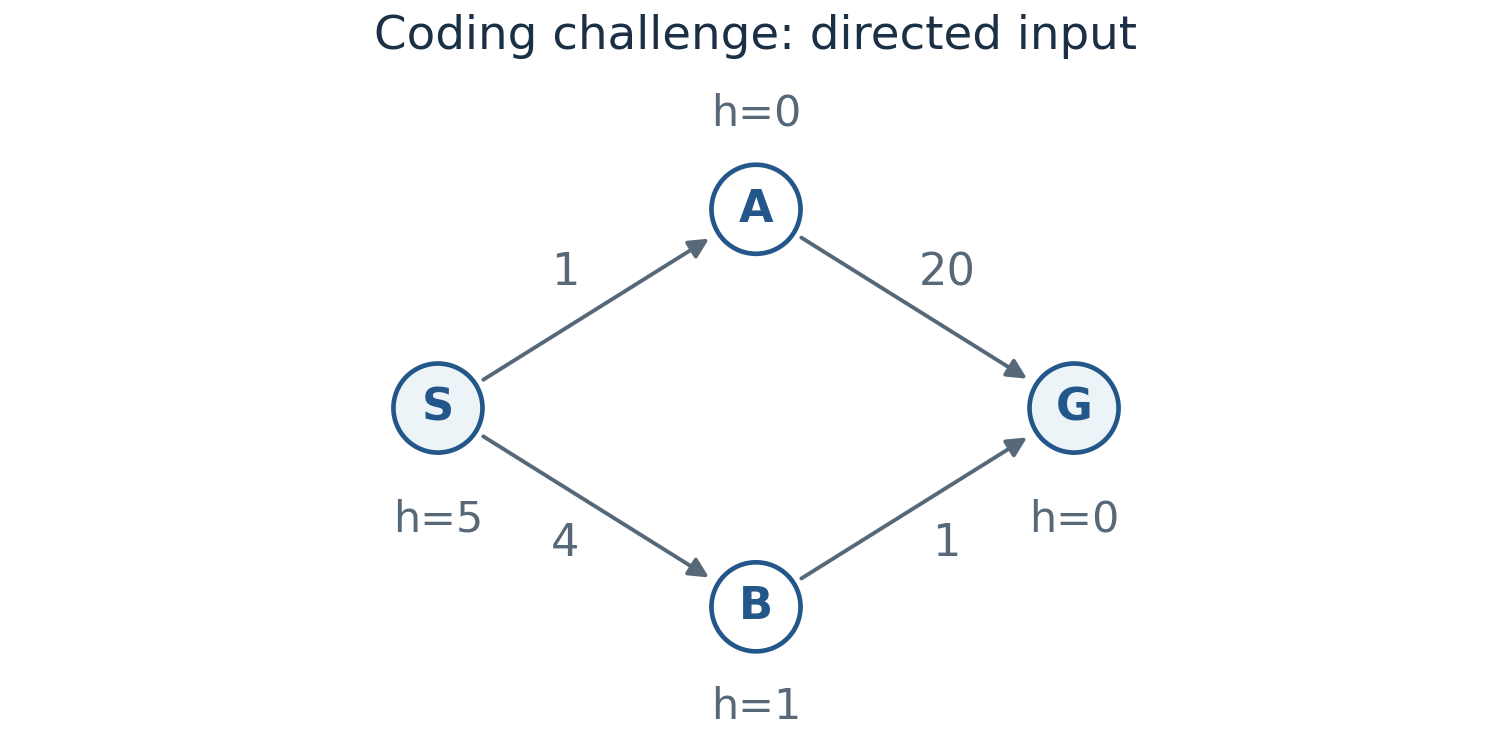

*정답 비용으로 갱신·종료 조건을 확인한다. 빈 grid에서는 주어진 heuristic을 활용해 탐색을 줄이는지도 확인한다.*

아래 함수의 TODO_PRIORITY, TODO_RELAXATION, TODO_GOAL_CHECK를 채운 뒤 다음 cell을 실행하자. Stats에는 expansion과 heap pop 횟수 등을 기록한다. TODO가 남아 있으면 테스트가 FAIL로 표시되는 것이 정상이다. 코드 전체를 직접 수정할 수 있으며, reference solution은 마지막 별도 cell에 있다.


In [15]:
from heapq import heappush, heappop
from itertools import count

def priority(g, h):
    return TODO_PRIORITY

def astar_cost(graph, start, goal, h, *, stats=None):
    goal_check = 'TODO_GOAL_CHECK'
    if stats is not None:
        stats.update(expanded=0, pops=0, stale=0, reopened=0)
    serial = count()
    best = {start: 0}
    expanded_before = set()
    pops = 0
    heap = []
    heappush(heap, (priority(0, h[start]), h[start],
                    next(serial), 0, start))
    while heap:
        if pops >= 5000:
            raise RuntimeError('5000-pop teaching limit')
        _, _, _, g, u = heappop(heap)
        pops += 1
        if stats is not None:
            stats['pops'] = pops
        if g != best.get(u):
            if stats is not None:
                stats['stale'] += 1
            continue  # obsolete snapshot
        if goal_check == 'pop' and u == goal:
            return g
        expanded_before.add(u)
        if stats is not None:
            stats['expanded'] += 1
        for v, cost in graph.get(u, []):
            candidate = g + cost
            old_g = best.get(v, float('inf'))
            if TODO_RELAXATION:
                if v in expanded_before and stats is not None:
                    stats['reopened'] += 1
                best[v] = candidate
                if goal_check == 'discovery' and v == goal:
                    return candidate
                heappush(heap, (priority(candidate, h[v]),
                                h[v], next(serial), candidate, v))
    return None


In [16]:
CODE_CASES = [{'id': 'illustrated',
  'graph': {'edges': [[[1, 1], [2, 4]], [[3, 20]], [[3, 1]], []],
            'start': 0,
            'goal': 3,
            'h': [5, 0, 1, 0]},
  'expected': 5},
 {'id': 'first-goal',
  'graph': {'edges': [[[2, 10], [1, 1]], [[2, 1]], []],
            'start': 0,
            'goal': 2,
            'h': [0, 0, 0]},
  'expected': 2},
 {'id': 'reopening',
  'graph': {'edges': [[[1, 3], [2, 1]], [[3, 3]], [[1, 1], [3, 100]], []],
            'start': 0,
            'goal': 3,
            'h': [5, 0, 4, 0]},
  'expected': 5},
 {'id': 'start-goal',
  'graph': {'edges': [[]], 'start': 0, 'goal': 0, 'h': [0]},
  'expected': 0},
 {'id': 'unreachable',
  'graph': {'edges': [[[1, 2]], [], []], 'start': 0, 'goal': 2, 'h': [0, 0, 0]},
  'expected': None},
 {'id': 'zero-cycle',
  'graph': {'edges': [[[1, 0]], [[0, 0], [2, 2]], []],
            'start': 0,
            'goal': 2,
            'h': [0, 0, 0]},
  'expected': 2},
 {'id': 'stale',
  'graph': {'edges': [[[1, 5], [2, 1]], [[3, 1]], [[1, 1]], [[4, 10]], []],
            'start': 0,
            'goal': 4,
            'h': [0, 0, 0, 0, 0]},
  'expected': 13,
  'maxExpanded': 4},
 {'id': 'informed',
  'graph': {'grid': {'width': 15, 'height': 15},
            'start': 0,
            'goal': 224,
            'h': 'manhattan'},
  'expected': 28,
  'maxExpanded': 40}]

def materialize_code_case(case):
    spec = case["graph"]
    if "grid" in spec:
        width, height = spec["grid"]["width"], spec["grid"]["height"]
        graph = {}
        for u in range(width * height):
            x, y = u % width, u // width
            graph[u] = [(ny * width + nx, 1)
                        for dx, dy in ((1, 0), (0, 1), (-1, 0), (0, -1))
                        for nx, ny in [(x + dx, y + dy)]
                        if 0 <= nx < width and 0 <= ny < height]
        tx, ty = spec["goal"] % width, spec["goal"] // width
        h = {u: abs(u % width - tx) + abs(u // width - ty) for u in graph}
    else:
        graph = {u: [tuple(edge) for edge in edges]
                 for u, edges in enumerate(spec["edges"])}
        h = dict(enumerate(spec["h"]))
    return graph, spec["start"], spec["goal"], h


def run_astar_code_tests(solver, verbose=True):
    # Optional stats are maintained by the supplied scaffold, not a timer.
    results = []
    for case in CODE_CASES:
        graph, start, goal, h = materialize_code_case(case)
        stats = {}
        cost, error = None, None
        try:
            cost = solver(graph, start, goal, h, stats=stats)
        except Exception as exc:
            error = f"{type(exc).__name__}: {exc}"
        cost_ok = error is None and cost == case["expected"]
        effort_ok = error is None and ("maxExpanded" not in case or
                     stats.get("expanded", float("inf")) <= case["maxExpanded"])
        result = {"id": case["id"], "cost": cost, "expected": case["expected"],
                  "cost_passed": cost_ok, "effort_passed": effort_ok,
                  "passed": cost_ok and effort_ok, "error": error, **stats}
        results.append(result)
        if verbose:
            status = "PASS" if result["passed"] else "FAIL"
            print(f"{case['id']}: {status}; cost={cost!r}; "
                  f"expected={case['expected']!r}; "
                  f"expanded={stats.get('expanded', '?')}" +
                  (f"; budget={case['maxExpanded']}" if "maxExpanded" in case else "") +
                  (f"; {error}" if error else ""))
    return results

exercise_results = run_astar_code_tests(astar_cost)


illustrated: FAIL; cost=None; expected=5; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
first-goal: FAIL; cost=None; expected=2; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
reopening: FAIL; cost=None; expected=5; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
start-goal: FAIL; cost=None; expected=0; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
unreachable: FAIL; cost=None; expected=None; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
zero-cycle: FAIL; cost=None; expected=2; expanded=0; NameError: name 'TODO_PRIORITY' is not defined
stale: FAIL; cost=None; expected=13; expanded=0; budget=4; NameError: name 'TODO_PRIORITY' is not defined
informed: FAIL; cost=None; expected=28; expanded=0; budget=40; NameError: name 'TODO_PRIORITY' is not defined


#### 참고: Reference solution — 먼저 직접 풀어 본 뒤 확인


In [17]:
from heapq import heappush, heappop
from itertools import count

def reference_priority(g, h):
    return g + h

def reference_astar_cost(graph, start, goal, h, *, stats=None):
    goal_check = 'pop'
    if stats is not None:
        stats.update(expanded=0, pops=0, stale=0, reopened=0)
    serial = count()
    best = {start: 0}
    expanded_before = set()
    pops = 0
    heap = []
    heappush(heap, (reference_priority(0, h[start]), h[start],
                    next(serial), 0, start))
    while heap:
        if pops >= 5000:
            raise RuntimeError('5000-pop teaching limit')
        _, _, _, g, u = heappop(heap)
        pops += 1
        if stats is not None:
            stats['pops'] = pops
        if g != best.get(u):
            if stats is not None:
                stats['stale'] += 1
            continue  # obsolete snapshot
        if goal_check == 'pop' and u == goal:
            return g
        expanded_before.add(u)
        if stats is not None:
            stats['expanded'] += 1
        for v, cost in graph.get(u, []):
            candidate = g + cost
            old_g = best.get(v, float('inf'))
            if candidate < old_g:
                if v in expanded_before and stats is not None:
                    stats['reopened'] += 1
                best[v] = candidate
                if goal_check == 'discovery' and v == goal:
                    return candidate
                heappush(heap, (reference_priority(candidate, h[v]),
                                h[v], next(serial), candidate, v))
    return None

reference_results = run_astar_code_tests(reference_astar_cost)
assert all(row['passed'] for row in reference_results)


illustrated: PASS; cost=5; expected=5; expanded=3
first-goal: PASS; cost=2; expected=2; expanded=2
reopening: PASS; cost=5; expected=5; expanded=4
start-goal: PASS; cost=0; expected=0; expanded=0
unreachable: PASS; cost=None; expected=None; expanded=2
zero-cycle: PASS; cost=2; expected=2; expanded=2
stale: PASS; cost=13; expected=13; expanded=4; budget=4
informed: PASS; cost=28; expected=28; expanded=28; budget=40


브라우저에서는 정해진 탐색 코드에 입력한 두 Python식 표현과 goal 확인 위치만 적용한다. Python 프로그램 전체를 실행하는 환경은 아니다. 한 번에 heap에서 최대 5,000개 항목까지만 꺼내므로, 같은 비용을 계속 갱신하는 실수를 해도 페이지가 멈추지 않는다. 실행 제한에 걸린 경우와 경로가 없는 경우는 따로 표시한다.

함수 전체를 직접 고치려면 [Python 문제와 테스트 파일](https://pilkwangkim.github.io/assets/code/astar-code-test.py)을 내려받으면 된다. 이 notebook에도 같은 그림 문제 다섯 개, 코드 뼈대, 테스트 입력 여덟 개, 별도의 reference solution이 들어 있다. 먼저 직접 풀어 본 뒤 정답을 열어 보자. 한 번 통과했다면 세 결정 중 하나만 바꿔 보고, 어느 테스트에서 왜 실패하는지도 확인해 보자.

## 18. 알고리즘을 구분하는 핵심

DFS는 가장 최근에 넣은 갈래부터 이어 가고, BFS는 가장 먼저 넣은 후보부터 살펴본다. Dijkstra는 지금까지의 비용이 가장 작은 prefix를, greedy는 목적지까지의 추정 비용이 가장 작은 state를 고른다. A\*는 이 둘을 함께 본다. **지금까지 든 비용과 앞으로 필요한 비용의 lower bound를 더한 값**이 가장 작은 prefix를 고른다.

A\*는 graph로 표현할 수 있는 다양한 문제에 적용할 수 있다. 조건에 맞게 구현하면 최적 경로를 보장하면서도, 좋은 heuristic으로 탐색 범위를 크게 줄일 수 있다. 대신 여러 후보를 보관하느라 메모리를 많이 쓰고, heuristic이 약하면 계산량도 별로 줄지 않는다. Heuristic이 과대평가하거나 state에 필요한 정보가 빠지면 앞서 증명한 보장은 적용할 수 없다.

$f=g+h$라는 식만으로 구현이 완성되지는 않는다. Edge cost와 state를 정확히 정의하고, strict relaxation으로 비용과 parent를 갱신하며, stale entry를 건너뛰고, goal을 올바른 시점에 꺼내야 한다. Consistency를 보장할 수 없다면 reopening도 허용해야 한다. 이 조건들이 맞물려 A\*가 최적 경로를 찾는다는 보장을 만든다.

## 참고문헌과 더 읽을 자료

- Peter E. Hart, Nils J. Nilsson, Bertram Raphael, [A Formal Basis for the Heuristic Determination of Minimum Cost Paths](https://doi.org/10.1109/TSSC.1968.300136), 1968. A\*를 처음 정식화한 논문.
- Edsger W. Dijkstra, [A Note on Two Problems in Connexion with Graphs](https://doi.org/10.1007/BF01386390), 1959. Dijkstra 최단 경로 알고리즘의 원 논문.
- UC Berkeley CS 188, [Uninformed Search](https://inst.eecs.berkeley.edu/~cs188/textbook/search/uninformed.html), [Informed Search](https://inst.eecs.berkeley.edu/~cs188/textbook/search/informed.html). 탐색 방식, relaxed problem, heuristic의 근거를 설명한다.
- Python 문서, [heapq: priority-queue implementation notes](https://docs.python.org/3/library/heapq.html#priority-queue-implementation-notes), [collections.deque](https://docs.python.org/3/library/collections.html#collections.deque). 코드에서 사용한 표준 라이브러리 자료구조.
- Amit Patel, [Introduction to A\*](https://www.redblobgames.com/pathfinding/a-star/introduction.html), [Implementation of A\*](https://www.redblobgames.com/pathfinding/a-star/implementation.html). 원 저자가 직접 만든 interactive 설명과 구현상의 선택.
- Maxim Likhachev, Geoffrey J. Gordon, Sebastian Thrun, [ARA\*: Anytime A\* with Provable Bounds on Sub-Optimality](https://papers.nips.cc/paper_files/paper/2003/hash/ee8fe9093fbbb687bef15a38facc44d2-Abstract.html), 2003. Bounded-suboptimal search와 점진적인 답 개선.
- Andrew V. Goldberg, Chris Harrelson, [Computing the Shortest Path: A\* Search Meets Graph Theory](https://www.microsoft.com/en-us/research/publication/computing-the-shortest-path-a-search-meets-graph-theory/), 2004 (technical report). 반복적인 경로 질의를 위한 landmark lower bound.
- Daniel Harabor, Alban Grastien, [Online Graph Pruning for Pathfinding on Grid Maps](https://ojs.aaai.org/index.php/AAAI/article/view/7994), 2011. Jump Point Search와 grid에 관한 가정.
- Sven Koenig, Maxim Likhachev, [D\* Lite](https://www.cs.cmu.edu/afs/cs/Web/People/motionplanning/papers/sbp_papers/integrated3/koenig_dstarlite_aaai02b.pdf), 2002. 정보가 바뀔 때 이전 결과를 활용하는 incremental replanning.
- Kenny Daniel, Alex Nash, Sven Koenig, Ariel Felner, [Theta\*: Any-Angle Path Planning on Grids](https://arxiv.org/abs/1401.3843), 2010. Grid edge의 방향에만 제한되지 않는 경로.
